Morse sets: 5
  M0:  312 cells  (attracting loop)  occupancy  29.7%
  M1:  312 cells  (attracting loop)  occupancy  39.3%
  M2:    7 cells  (saddle region  )  occupancy   0.7%
  M3:    1 cells  (repelling focus)  occupancy   0.0%
  M4:    1 cells  (repelling focus)  occupancy   0.0%
Conley-Morse edges: [('M2', 'M0'), ('M2', 'M1'), ('M3', 'M0'), ('M4', 'M1')]
Loop-to-loop switches in trajectory: 18
saved morse_metastable.png


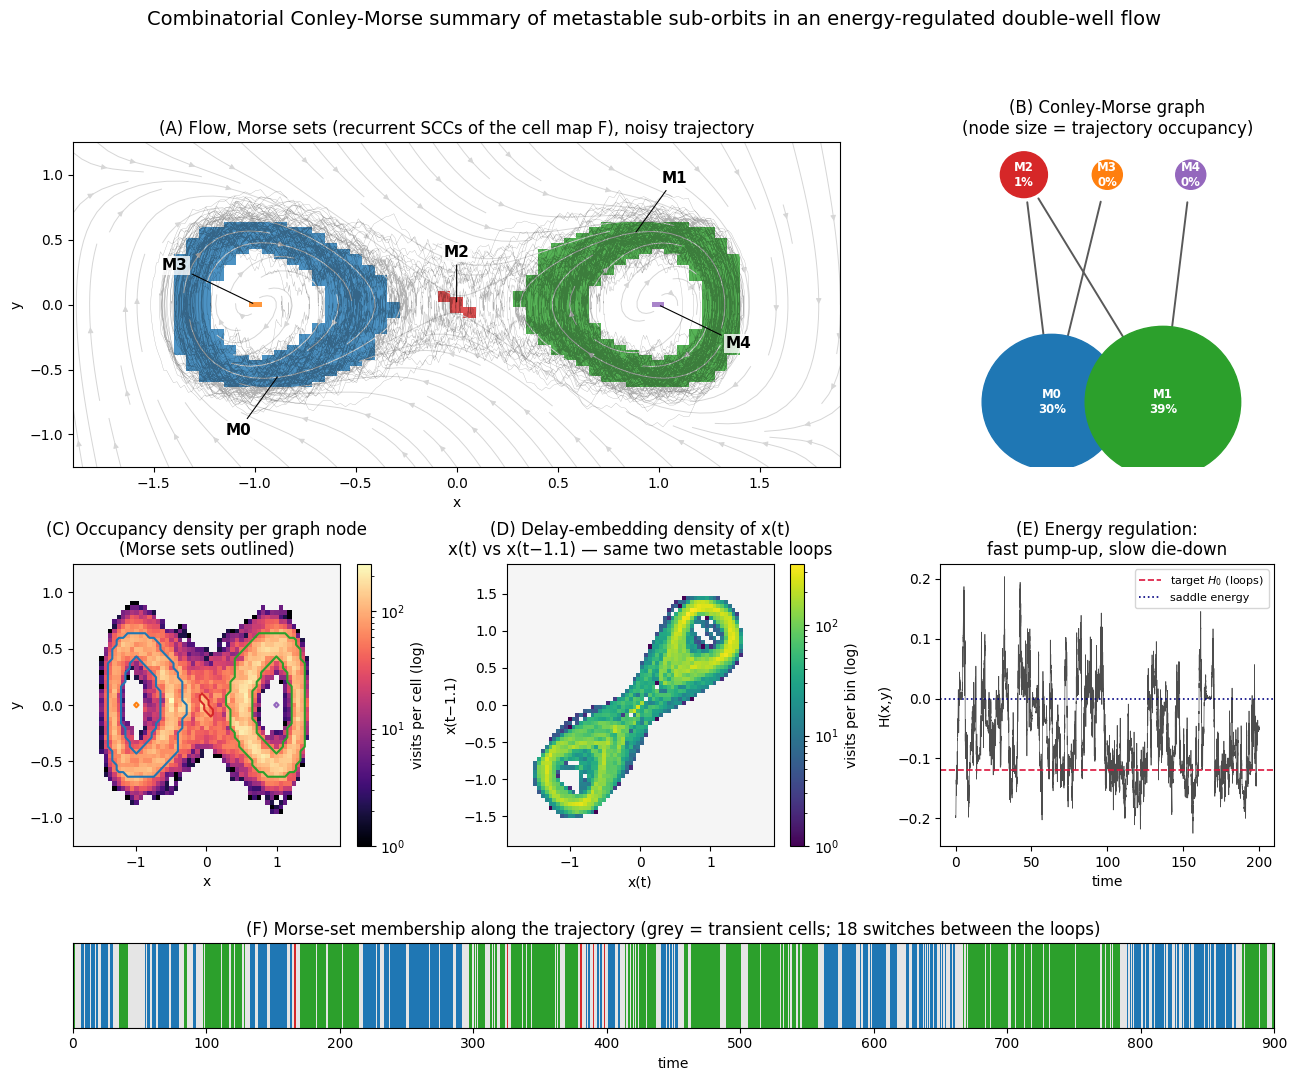

In [1]:
# =============================================================================
# Combinatorial (multivector-style) Conley-Morse decomposition of a 2D flow
# with metastable sub-orbits, plus per-node density / delay-embedding heatmaps.
#
# THE SYSTEM -- a double-well flow with state-dependent ENERGY REGULATION:
#
#     x' = y
#     y' = x - x^3 + g(H) * (H0 - H) * y ,     H(x,y) = y^2/2 + x^4/4 - x^2/2
#
#     g(H) = GAMMA_UP  if H < H0   (strong pumping: the longer the state sits
#                                   at low energy, the harder it accelerates)
#          = GAMMA_DOWN otherwise  (gentle damping: the excitation dies back
#                                   down slowly once energy overshoots)
#
#   * In EACH well the attractor is therefore a small periodic LOOP at energy
#     ~H0: a sub-orbit inside the main double-well structure -- the 2D
#     caricature of a Lorenz wing. Because H0 < 0 (the saddle sits at H = 0)
#     the two loops are confined to their wells: two metastable regimes.
#   * Small noise occasionally kicks the energy over the saddle and the state
#     switches wings -- rarely, because pumping pulls it straight back down.
#
# THE COMBINATORIAL PIPELINE (grid analogue of a multivector field):
#   1. Partition a window of phase space into grid cells (the complex).
#   2. For each cell, flow a fan of sample points for time tau and bloat the
#      landing cells by one cell in every direction  ->  a combinatorial
#      multivalued map F (an outer approximation of the time-tau flow map,
#      in the spirit of the Conley-Morse database / multivector framework).
#   3. Recurrent dynamics = nontrivial strongly connected components of the
#      digraph of F  ->  the MORSE SETS. Here: two attracting loop annuli,
#      two repelling foci, and the saddle.
#   4. Reachability between Morse sets (transitively reduced) -> the
#      CONLEY-MORSE GRAPH: repellers and saddle feed the two loops.
#   5. Characterize each node of the combinatorial graph with heatmaps:
#      occupancy density of a long noisy trajectory per grid cell, and the
#      same density in a scalar DELAY EMBEDDING (x(t), x(t - tau_d)) -- what
#      you would build if you could only observe x.
#   6. Trace the trajectory through the decomposition: Morse-set membership
#      over time shows metastable residence and the rare switching events.
#
# Resolution caveat (the honest part): a grid outer approximation can only
# bound recurrence from outside, so Morse sets are "fat" enclosures -- e.g.
# each loop annulus here is several cells thick. The Conley-Morse database
# method shrinks them by adaptive subdivision; the parameters below (grid 61,
# tau = 2.5, 1-cell bloat) were chosen so all five sets already separate.
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import FancyArrowPatch, Circle
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

rng = np.random.default_rng(7)

# ----------------------------------------------------------------------------
# 1) The flow
# ----------------------------------------------------------------------------
H0 = -0.12                     # target loop energy (< 0 = saddle energy)
GAMMA_UP, GAMMA_DOWN = 12.0, 2.5   # fast pump-up, slow die-down

def V(x):            return 0.25 * x**4 - 0.5 * x**2
def energy(x, y):    return 0.5 * y**2 + V(x)

def field(x, y):
    H = energy(x, y)
    g = np.where(H < H0, GAMMA_UP, GAMMA_DOWN)
    return y, x - x**3 + g * (H0 - H) * y

def rk2(x, y, dt):
    k1x, k1y = field(x, y)
    k2x, k2y = field(x + 0.5 * dt * k1x, y + 0.5 * dt * k1y)
    return x + dt * k2x, y + dt * k2y

# ----------------------------------------------------------------------------
# 2) Grid (the combinatorial complex)
# ----------------------------------------------------------------------------
NX = NY = 61                                  # odd: fixed points sit mid-cell
XMIN, XMAX, YMIN, YMAX = -1.9, 1.9, -1.25, 1.25
x_edges = np.linspace(XMIN, XMAX, NX + 1)
y_edges = np.linspace(YMIN, YMAX, NY + 1)
N_CELLS, EXT = NX * NY, NX * NY               # EXT = absorbing exterior node

def cell_of(x, y):
    i = np.floor((x - XMIN) / (XMAX - XMIN) * NX).astype(int)
    j = np.floor((y - YMIN) / (YMAX - YMIN) * NY).astype(int)
    inside = (i >= 0) & (i < NX) & (j >= 0) & (j < NY)
    return np.where(inside, j * NX + i, -1)

# ----------------------------------------------------------------------------
# 3) Combinatorial multivalued map F (bloated time-tau outer approximation)
# ----------------------------------------------------------------------------
DT, TAU_STEPS = 0.01, 250                     # map time tau = 2.5
fr = np.array([0.1, 0.37, 0.63, 0.9])         # 4x4 sample fan per cell
ii, jj = np.meshgrid(np.arange(NX), np.arange(NY))
cx = XMIN + (ii.ravel()[:, None] + fr[None, :]) * (XMAX - XMIN) / NX
cy = YMIN + (jj.ravel()[:, None] + fr[None, :]) * (YMAX - YMIN) / NY
PX = np.repeat(cx, len(fr), axis=1).ravel()
PY = np.tile(cy, (1, len(fr))).ravel()
SRC = np.repeat(np.arange(N_CELLS), len(fr) ** 2)

px, py = PX.copy(), PY.copy()
for _ in range(TAU_STEPS):
    px, py = rk2(px, py, DT)

di = np.floor((px - XMIN) / (XMAX - XMIN) * NX).astype(int)
dj = np.floor((py - YMIN) / (YMAX - YMIN) * NY).astype(int)
offs = [(a, b) for a in (-1, 0, 1) for b in (-1, 0, 1)]   # 1-cell bloat
I = np.concatenate([di + a for a, b in offs])
J = np.concatenate([dj + b for a, b in offs])
S = np.tile(SRC, len(offs))
inside = (I >= 0) & (I < NX) & (J >= 0) & (J < NY)
D = np.where(inside, J * NX + I, EXT)

edges = np.unique(np.stack([S, D], axis=1), axis=0)
A = coo_matrix((np.ones(len(edges)), (edges[:, 0], edges[:, 1])),
               shape=(N_CELLS + 1, N_CELLS + 1)).tocsr()

# ----------------------------------------------------------------------------
# 4) Morse sets = nontrivial SCCs;  Conley-Morse graph = reachability order
# ----------------------------------------------------------------------------
_, scc = connected_components(A, directed=True, connection='strong')
scc_size = np.bincount(scc)
has_selfloop = np.zeros(len(scc_size), dtype=bool)
sl = edges[edges[:, 0] == edges[:, 1], 0]
has_selfloop[scc[sl]] = True
recurrent = (scc_size > 1) | has_selfloop
recurrent[scc[EXT]] = False

def scc_cells(s):  return np.flatnonzero(scc[:N_CELLS] == s)

morse_sccs = sorted(np.flatnonzero(recurrent),
                    key=lambda s: (-scc_size[s], np.mean(scc_cells(s) % NX)))
morse_id = {s: k for k, s in enumerate(morse_sccs)}
n_morse = len(morse_sccs)

cell_morse = np.full(N_CELLS, -1)             # -1 = transient cell
for s, k in morse_id.items():
    cell_morse[scc_cells(s)] = k

cond = {}                                     # condensation adjacency
for u, v in edges:
    if scc[u] != scc[v]:
        cond.setdefault(scc[u], set()).add(scc[v])

def reachable_morse(s0):
    seen, stack, out = {s0}, [s0], set()
    while stack:
        for t in cond.get(stack.pop(), ()):
            if t not in seen:
                seen.add(t)
                if recurrent[t]:
                    out.add(t)
                stack.append(t)
    return out

reach = {s: reachable_morse(s) for s in morse_sccs}
morse_edges = [(morse_id[s], morse_id[t])
               for s in morse_sccs for t in reach[s]
               if not any(t in reach[m] for m in reach[s] if m != t)]   # trans. red.

# ----------------------------------------------------------------------------
# 5) Long noisy trajectory: per-node densities, delay embedding, tracing
# ----------------------------------------------------------------------------
STEPS, SIGMA = 90_000, 0.19
tx, ty = np.empty(STEPS), np.empty(STEPS)
x, y = 1.2, 0.1
for t in range(STEPS):
    x, y = rk2(x, y, DT)
    y += SIGMA * np.sqrt(DT) * rng.standard_normal()
    x = np.clip(x, XMIN + 1e-6, XMAX - 1e-6)
    y = np.clip(y, YMIN + 1e-6, YMAX - 1e-6)
    tx[t], ty[t] = x, y

traj_cells = cell_of(tx, ty)
density = np.bincount(traj_cells, minlength=N_CELLS).reshape(NY, NX).astype(float)
trace = cell_morse[traj_cells]                # Morse membership along the path

occ = np.array([(trace == k).sum() for k in range(n_morse)]) / STEPS
loops = [0, 1]                                # two largest sets = the loops
visits = trace[np.isin(trace, loops)]
switches = int(np.sum(visits[1:] != visits[:-1]))

LAG = 110                                     # ~ quarter loop period
emb_hist, ex_e, ey_e = np.histogram2d(tx[LAG:], tx[:-LAG], bins=70,
                                      range=[[XMIN, XMAX], [XMIN, XMAX]])

print(f"Morse sets: {n_morse}")
for k, s in enumerate(morse_sccs):
    cs = scc_cells(s)
    cxm = XMIN + (cs % NX + 0.5).mean() * (XMAX - XMIN) / NX
    kind = "attracting loop" if scc_size[s] > 20 else \
           ("saddle region" if abs(cxm) < 0.3 else "repelling focus")
    print(f"  M{k}: {scc_size[s]:4d} cells  ({kind:15s})  occupancy {occ[k]*100:5.1f}%")
print("Conley-Morse edges:", [(f"M{a}", f"M{b}") for a, b in morse_edges])
print(f"Loop-to-loop switches in trajectory: {switches}")

# ----------------------------------------------------------------------------
# 6) Figure
# ----------------------------------------------------------------------------
morse_colors = np.array(plt.cm.tab10.colors)[[0, 2, 3, 1, 4, 5, 6, 7, 8, 9][:n_morse]]
fig = plt.figure(figsize=(15.5, 11.5))
gs = fig.add_gridspec(3, 3, height_ratios=[1.15, 1, 0.3], hspace=0.42, wspace=0.3)

# (A) phase space: flow + Morse sets + noisy trajectory
axA = fig.add_subplot(gs[0, 0:2])
gx, gy = np.meshgrid(np.linspace(XMIN, XMAX, 26), np.linspace(YMIN, YMAX, 18))
u, v = field(gx, gy)
axA.streamplot(gx, gy, u, v, color='0.84', density=1.1, linewidth=0.7, arrowsize=0.8)
overlay = np.ma.masked_where(cell_morse.reshape(NY, NX) < 0, cell_morse.reshape(NY, NX))
axA.pcolormesh(x_edges, y_edges, overlay,
               cmap=mcolors.ListedColormap(morse_colors),
               vmin=-0.5, vmax=n_morse - 0.5, alpha=0.8)
axA.plot(tx[::3], ty[::3], color='k', lw=0.25, alpha=0.3)
# label anchors: point at the set itself (loops are annuli, so anchor on the ring)
anchor_off = {0: (0, -0.52), 1: (0, 0.52)}        # on-ring anchor for the loops
text_off   = {0: (-0.2, -0.95), 1: (0.2, 0.95),   # label positions
              2: (0, 0.4), 3: (-0.4, 0.3), 4: (0.4, -0.3)}
for k in range(n_morse):
    cs = np.flatnonzero(cell_morse == k)
    mx = np.mean(XMIN + (cs % NX + 0.5) * (XMAX - XMIN) / NX)
    my = np.mean(YMIN + (cs // NX + 0.5) * (YMAX - YMIN) / NY)
    ax_, ay_ = anchor_off.get(k, (0, 0))
    tx_, ty_ = text_off.get(k, (0, 0))
    axA.annotate(f"M{k}", (mx + ax_, my + ay_), (mx + tx_, my + ty_),
                 fontsize=11, fontweight='bold', ha='center', va='center',
                 arrowprops=dict(arrowstyle='-', lw=0.8) if (tx_ or ty_) else None,
                 bbox=dict(fc='white', alpha=0.8, ec='none', pad=1.5))
axA.set_title("(A) Flow, Morse sets (recurrent SCCs of the cell map F), noisy trajectory")
axA.set_xlabel("x"); axA.set_ylabel("y")

# (B) Conley-Morse graph
axB = fig.add_subplot(gs[0, 2]); axB.set_axis_off()
axB.set_title("(B) Conley-Morse graph\n(node size = trajectory occupancy)")
depth = {k: 0 for k in range(n_morse)}
for _ in range(n_morse):
    for a, b in morse_edges:
        depth[b] = max(depth[b], depth[a] + 1)
levels = {}
for k in range(n_morse):
    levels.setdefault(depth[k], []).append(k)
pos = {}
maxd = max(depth.values()) if depth else 1
for d, ks in levels.items():
    for q, k in enumerate(sorted(ks)):
        pos[k] = ((q + 1) / (len(ks) + 1), 0.9 - 0.7 * d / max(maxd, 1))
for a, b in morse_edges:
    axB.add_patch(FancyArrowPatch(pos[a], pos[b], arrowstyle='-|>',
                                  mutation_scale=16, color='0.35',
                                  shrinkA=20, shrinkB=24, lw=1.4))
for k in range(n_morse):
    r = 0.045 + 0.30 * np.sqrt(occ[k])
    axB.add_patch(Circle(pos[k], r, color=morse_colors[k], zorder=3))
    axB.text(pos[k][0], pos[k][1], f"M{k}\n{occ[k]*100:.0f}%", ha='center',
             va='center', fontsize=8.5, zorder=4, color='white', fontweight='bold')
axB.set_xlim(0, 1); axB.set_ylim(0, 1)

# (C) per-node occupancy density heatmap (state space)
axC = fig.add_subplot(gs[1, 0])
pc = axC.pcolormesh(x_edges, y_edges, np.ma.masked_less(density, 1),
                    norm=mcolors.LogNorm(vmin=1), cmap='magma')
fig.colorbar(pc, ax=axC, label="visits per cell (log)")
cxs = 0.5 * (x_edges[:-1] + x_edges[1:])
cys = 0.5 * (y_edges[:-1] + y_edges[1:])
for k in range(n_morse):
    axC.contour(cxs, cys, (cell_morse.reshape(NY, NX) == k).astype(float),
                levels=[0.5], colors=[morse_colors[k]], linewidths=1.5)
axC.set_facecolor('0.96')
axC.set_title("(C) Occupancy density per graph node\n(Morse sets outlined)")
axC.set_xlabel("x"); axC.set_ylabel("y")

# (D) delay-embedding density of the scalar observable x(t)
axD = fig.add_subplot(gs[1, 1])
pd_ = axD.pcolormesh(ex_e, ey_e, np.ma.masked_less(emb_hist.T, 1),
                     norm=mcolors.LogNorm(vmin=1), cmap='viridis')
fig.colorbar(pd_, ax=axD, label="visits per bin (log)")
axD.set_facecolor('0.96')
axD.set_title(f"(D) Delay-embedding density of x(t)\n"
              f"x(t) vs x(t−{LAG*DT:.1f}) — same two metastable loops")
axD.set_xlabel("x(t)"); axD.set_ylabel(f"x(t−{LAG*DT:.1f})")

# (E) the energy-regulation mechanism
axE = fig.add_subplot(gs[1, 2])
tseg = slice(0, 20_000)
tt = np.arange(STEPS) * DT
axE.plot(tt[tseg], energy(tx, ty)[tseg], lw=0.5, color='0.3')
axE.axhline(H0, color='crimson', ls='--', lw=1.2, label='target $H_0$ (loops)')
axE.axhline(0.0, color='navy', ls=':', lw=1.2, label='saddle energy')
axE.set_title("(E) Energy regulation:\nfast pump-up, slow die-down")
axE.set_xlabel("time"); axE.set_ylabel("H(x,y)")
axE.legend(fontsize=8, loc='upper right')

# (F) trajectory traced through the decomposition
axF = fig.add_subplot(gs[2, :])
strip = mcolors.ListedColormap(['0.9'] + [tuple(c) for c in morse_colors])
axF.imshow((trace + 1)[None, :], aspect='auto', cmap=strip,
           vmin=-0.5, vmax=n_morse + 0.5,
           extent=[0, STEPS * DT, 0, 1], interpolation='nearest')
axF.set_yticks([]); axF.set_xlabel("time")
axF.set_title(f"(F) Morse-set membership along the trajectory "
              f"(grey = transient cells; {switches} switches between the loops)")

fig.suptitle("Combinatorial Conley-Morse summary of metastable sub-orbits in an "
             "energy-regulated double-well flow", fontsize=14, y=0.995)
fig.savefig("morse_metastable.png", dpi=140, bbox_inches='tight')
print("saved morse_metastable.png")

Morse sets: 5   (cells mapping out of window: 0)
  M0:  312 cells   Con = (1,1,0)  p(t) = 1 + t    |P1|= 171 |P2|=  0  isolated=True
  M1:  312 cells   Con = (1,1,0)  p(t) = 1 + t    |P1|= 171 |P2|=  0  isolated=True
  M2:    7 cells   Con = (0,1,0)  p(t) = t        |P1|=  43 |P2|= 26  isolated=True
  M3:    1 cells   Con = (0,0,1)  p(t) = t²       |P1|=  35 |P2|= 32  isolated=True
  M4:    1 cells   Con = (0,0,1)  p(t) = t²       |P1|=  35 |P2|= 32  isolated=True
Conley-Morse edges: [('M2', 'M0'), ('M2', 'M1'), ('M3', 'M0'), ('M4', 'M1')]
Morse equation:  sum p_M = 2 + 3t + 2t²  =  p_X + (1+t) q(t)  with p_X = 1,  q(t) = 1 + 2t  ->  BALANCED (q >= 0 certifies the forced connecting orbits)
Loop-to-loop switches in trajectory: 18


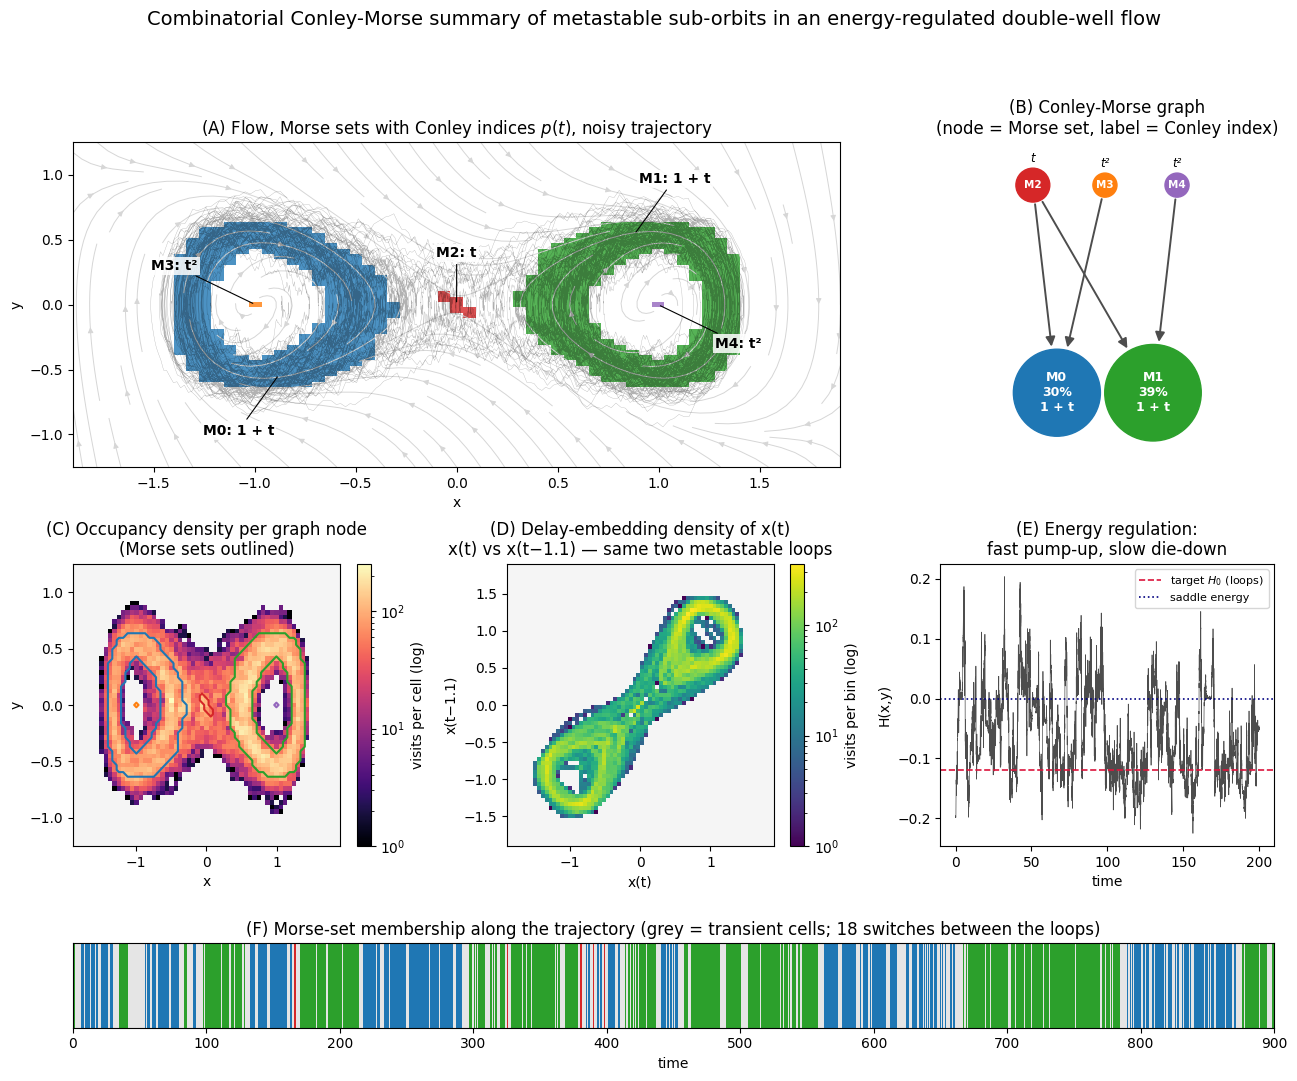

critical cells by dimension: {0: 4, 1: 2, 2: 0}


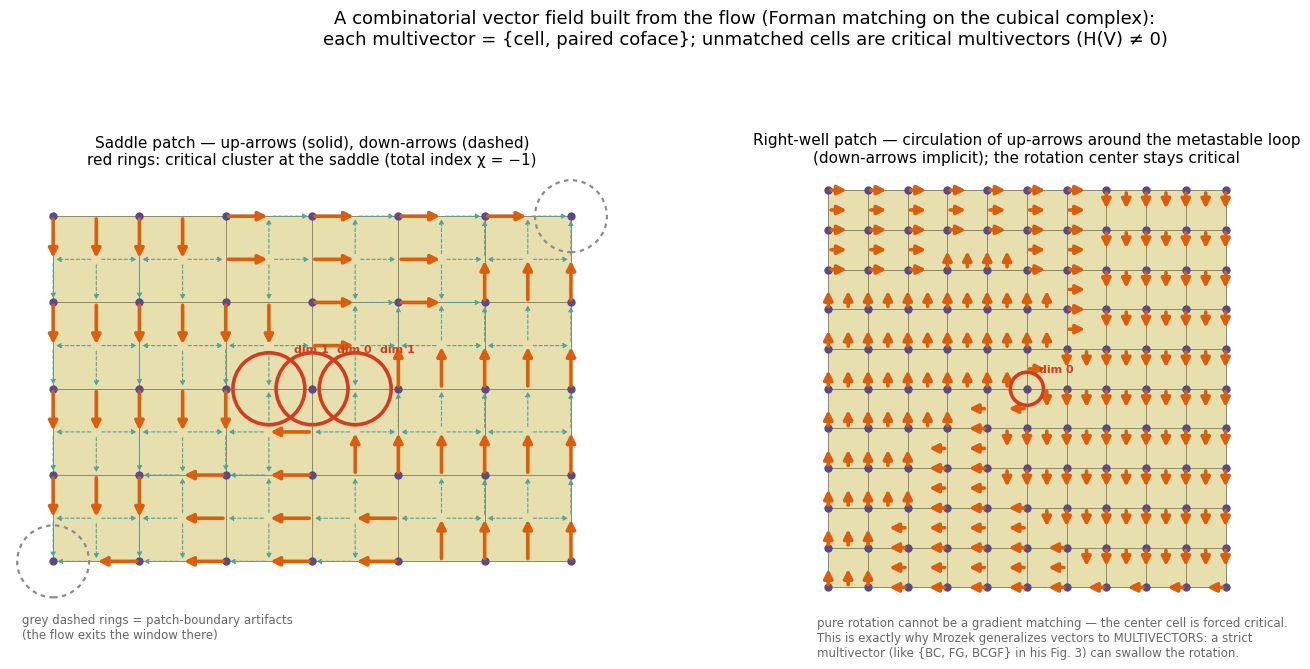

lambda=-0.30: 3 Morse sets  [1, 1, t]
lambda=-0.28: 3 Morse sets  [1, 1, t]
lambda=-0.26: 3 Morse sets  [1, 1, t]
lambda=-0.24: 3 Morse sets  [1, 1, t]
lambda=-0.22: 3 Morse sets  [1, 1, t]
lambda=-0.20: 3 Morse sets  [1, 1, t]
lambda=-0.18: 5 Morse sets  [1 + t, 1 + t, t², t², t]
lambda=-0.16: 5 Morse sets  [1 + t, 1 + t, t, t², t²]
lambda=-0.14: 5 Morse sets  [1 + t, 1 + t, t, t², t²]
lambda=-0.12: 5 Morse sets  [1 + t, 1 + t, t, t², t²]
lambda=-0.10: 5 Morse sets  [1 + t, 1 + t, t, t², t²]
lambda=-0.08: 5 Morse sets  [1 + t, 1 + t, t, t², t²]
lambda=-0.06: 3 Morse sets  [1 + 2t, t², t²]
lambda=-0.04: 3 Morse sets  [1 + 2t, t², t²]
lambda=-0.02: 3 Morse sets  [1 + 2t, t², t²]
lambda=+0.00: 3 Morse sets  [1 + 2t, t², t²]
lambda=+0.02: 3 Morse sets  [1 + 2t, t², t²]
lambda=+0.04: 4 Morse sets  [1 + t, t, t², t²]
lambda=+0.06: 4 Morse sets  [1 + t, t, t², t²]
lambda=+0.08: 4 Morse sets  [1 + t, t, t², t²]
lambda=+0.10: 4 Morse sets  [1 + t, t, t², t²]
lambda=+0.12: 4 Morse sets  [1 + t,

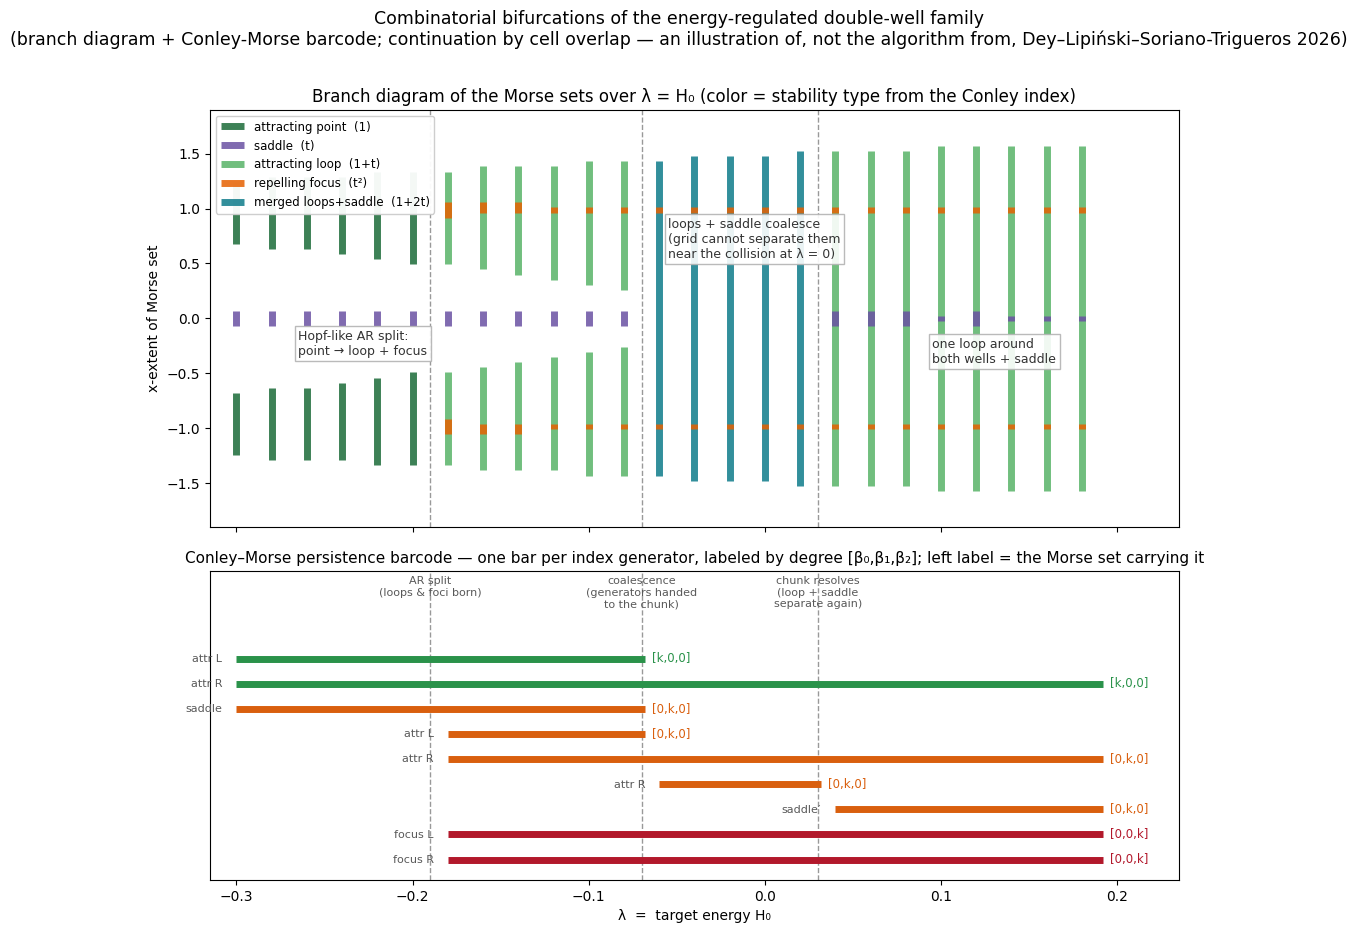

In [2]:
# =============================================================================
# conley_morse_notebook.py
#
# ONE self-contained script / notebook for the combinatorial Conley-Morse
# analysis of a 2D flow with metastable sub-orbits (an energy-regulated
# double-well: each well holds a small attracting loop at target energy H0,
# noise switches the state between wells -- a 2D caricature of Lorenz wings).
#
# Run top-to-bottom, or as cells (the "# %%" markers work in Jupyter/VS Code):
#   cell 1  LIBRARY   flow, grid, bloated time-tau cell map, Morse sets
#                     (recurrent SCCs), Conley-Morse graph, Conley indices
#                     via flow-adapted index pairs + relative cubical
#                     homology over Z/2, Morse-equation check, graph drawing
#   cell 2  FIGURE 1  six-panel summary: Morse sets + computed indices,
#                     Conley-Morse graph, occupancy heatmap per graph node,
#                     delay-embedding density, energy regulation, trajectory
#                     traced through the decomposition
#   cell 3  FIGURE 2  Forman-style combinatorial (multi)vector field on two
#                     cubical patches (saddle + right well)
#   cell 4  FIGURE 3  lambda-sweep over H0: branch diagram + Conley-Morse
#                     persistence barcode (illustration of, not the algorithm
#                     from, Dey-Lipinski-Soriano-Trigueros, FoCM 2026).
#                     ~3 min on first run; results cached in sweep_cache.pkl.
#
# Extend from here: swap in your own 2D field in make_field(), re-tune the
# grid/tau/bloat in cell 2, or add lambda-parameterized families in cell 4.
# =============================================================================
# %% ------------------------------------------------- cell 1: LIBRARY
from types import SimpleNamespace

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import FancyArrowPatch, Circle, Rectangle
from matplotlib.collections import LineCollection
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

# ----------------------------------------------------------------------------
# flow
# ----------------------------------------------------------------------------
def make_field(H0, gamma_up=12.0, gamma_down=2.5):
    """Energy-regulated double-well vector field, vectorized."""
    def field(x, y):
        H = 0.5 * y**2 + 0.25 * x**4 - 0.5 * x**2
        g = np.where(H < H0, gamma_up, gamma_down)
        return y, x - x**3 + g * (H0 - H) * y
    return field

def make_rk2(field):
    def rk2(x, y, dt):
        k1x, k1y = field(x, y)
        k2x, k2y = field(x + 0.5 * dt * k1x, y + 0.5 * dt * k1y)
        return x + dt * k2x, y + dt * k2y
    return rk2

# ----------------------------------------------------------------------------
# grid
# ----------------------------------------------------------------------------
def make_grid(NX=61, NY=61, XMIN=-1.9, XMAX=1.9, YMIN=-1.25, YMAX=1.25):
    g = SimpleNamespace(NX=NX, NY=NY, XMIN=XMIN, XMAX=XMAX, YMIN=YMIN, YMAX=YMAX)
    g.x_edges = np.linspace(XMIN, XMAX, NX + 1)
    g.y_edges = np.linspace(YMIN, YMAX, NY + 1)
    g.hx = (XMAX - XMIN) / NX
    g.hy = (YMAX - YMIN) / NY
    g.N = NX * NY
    g.EXT = NX * NY
    return g

def cell_of(g, x, y):
    i = np.floor((x - g.XMIN) / (g.XMAX - g.XMIN) * g.NX).astype(int)
    j = np.floor((y - g.YMIN) / (g.YMAX - g.YMIN) * g.NY).astype(int)
    inside = (i >= 0) & (i < g.NX) & (j >= 0) & (j < g.NY)
    return np.where(inside, j * g.NX + i, -1)

def sample_points(g, cells, fr=(0.1, 0.37, 0.63, 0.9)):
    """k x k fan of sample points inside each listed cell. Returns px, py, src."""
    fr = np.asarray(fr)
    ci, cj = cells % g.NX, cells // g.NX
    cx = g.XMIN + (ci[:, None] + fr[None, :]) * g.hx
    cy = g.YMIN + (cj[:, None] + fr[None, :]) * g.hy
    px = np.repeat(cx, len(fr), axis=1).ravel()
    py = np.tile(cy, (1, len(fr))).ravel()
    src = np.repeat(cells, len(fr) ** 2)
    return px, py, src

# ----------------------------------------------------------------------------
# bloated time-tau multivalued cell map F
# ----------------------------------------------------------------------------
def build_map(g, rk2, dt=0.01, tau_steps=250, bloat=1):
    """Edges (src_cell, dst_cell) of the combinatorial multivalued map."""
    px, py, src = sample_points(g, np.arange(g.N))
    for _ in range(tau_steps):
        px, py = rk2(px, py, dt)
    di = np.floor((px - g.XMIN) / (g.XMAX - g.XMIN) * g.NX).astype(int)
    dj = np.floor((py - g.YMIN) / (g.YMAX - g.YMIN) * g.NY).astype(int)
    offs = [(a, b) for a in range(-bloat, bloat + 1) for b in range(-bloat, bloat + 1)]
    I = np.concatenate([di + a for a, b in offs])
    J = np.concatenate([dj + b for a, b in offs])
    S = np.tile(src, len(offs))
    inside = (I >= 0) & (I < g.NX) & (J >= 0) & (J < g.NY)
    D = np.where(inside, J * g.NX + I, g.EXT)
    return np.unique(np.stack([S, D], axis=1), axis=0)

# ----------------------------------------------------------------------------
# Morse decomposition + reduced Morse graph
# ----------------------------------------------------------------------------
def morse_decomposition(g, edges):
    """Returns (cell_morse, morse_cells, morse_edges, n_exits_to_EXT)."""
    A = coo_matrix((np.ones(len(edges)), (edges[:, 0], edges[:, 1])),
                   shape=(g.N + 1, g.N + 1)).tocsr()
    _, scc = connected_components(A, directed=True, connection='strong')
    size = np.bincount(scc)
    selfloop = np.zeros(len(size), dtype=bool)
    selfloop[scc[edges[edges[:, 0] == edges[:, 1], 0]]] = True
    recurrent = (size > 1) | selfloop
    recurrent[scc[g.EXT]] = False

    def cells(s): return np.flatnonzero(scc[:g.N] == s)
    morse_sccs = sorted(np.flatnonzero(recurrent),
                        key=lambda s: (-size[s], np.mean(cells(s) % g.NX)))
    morse_id = {s: k for k, s in enumerate(morse_sccs)}
    cell_morse = np.full(g.N, -1)
    morse_cells = []
    for s, k in morse_id.items():
        cs = cells(s)
        cell_morse[cs] = k
        morse_cells.append(cs)

    cond = {}
    for u, v in edges:
        if scc[u] != scc[v]:
            cond.setdefault(scc[u], set()).add(scc[v])

    def reach(s0):
        seen, stack, out = {s0}, [s0], set()
        while stack:
            for t in cond.get(stack.pop(), ()):
                if t not in seen:
                    seen.add(t)
                    if recurrent[t]:
                        out.add(t)
                    stack.append(t)
        return out

    R = {s: reach(s) for s in morse_sccs}
    morse_edges = [(morse_id[s], morse_id[t])
                   for s in morse_sccs for t in R[s]
                   if not any(t in R[m] for m in R[s] if m != t)]
    n_exit = int((edges[:, 1] == g.EXT).sum())
    return cell_morse, morse_cells, morse_edges, n_exit

# ----------------------------------------------------------------------------
# GF(2) linear algebra + relative cubical homology of a pair of square sets
# ----------------------------------------------------------------------------
def gf2_rank(A):
    A = A.copy()
    r = 0
    nrows, ncols = A.shape
    for c in range(ncols):
        piv = np.flatnonzero(A[r:, c])
        if len(piv) == 0:
            continue
        p = r + piv[0]
        if p != r:
            A[[r, p]] = A[[p, r]]
        mask = A[:, c].copy()
        mask[r] = False
        A[mask] ^= A[r]
        r += 1
        if r == nrows:
            break
    return r

def _closed_cells(squares):
    """Vertices, edges of the closed cubical complex spanned by (i,j) squares."""
    sq = set(map(tuple, squares))
    verts, hedges, vedges = set(), set(), set()
    for (i, j) in sq:
        verts |= {(i, j), (i + 1, j), (i, j + 1), (i + 1, j + 1)}
        hedges |= {(i, j), (i, j + 1)}          # horizontal edge at (i, j)
        vedges |= {(i, j), (i + 1, j)}          # vertical   edge at (i, j)
    return sq, verts, hedges, vedges

def relative_betti(P1_squares, P2_squares):
    """Betti numbers of H(cl P1, cl P2; Z/2). P2_squares subset of P1_squares."""
    sq1, v1, h1, ve1 = _closed_cells(P1_squares)
    sq2, v2, h2, ve2 = _closed_cells(P2_squares) if len(P2_squares) else \
        (set(), set(), set(), set())
    Q2 = sorted(sq1 - sq2)
    Qh = sorted(h1 - h2)
    Qv = sorted(ve1 - ve2)
    Q1 = [('h', e) for e in Qh] + [('v', e) for e in Qv]
    Q0 = sorted(v1 - v2)
    i1 = {c: n for n, c in enumerate(Q1)}
    i0 = {c: n for n, c in enumerate(Q0)}

    d2 = np.zeros((len(Q1), len(Q2)), dtype=bool)
    for n, (i, j) in enumerate(Q2):
        for c in (('h', (i, j)), ('h', (i, j + 1)),
                  ('v', (i, j)), ('v', (i + 1, j))):
            if c in i1:
                d2[i1[c], n] = True
    d1 = np.zeros((len(Q0), len(Q1)), dtype=bool)
    for n, (kind, (i, j)) in enumerate(Q1):
        ends = ((i, j), (i + 1, j)) if kind == 'h' else ((i, j), (i, j + 1))
        for vtx in ends:
            if vtx in i0:
                d1[i0[vtx], n] = True

    r2 = gf2_rank(d2) if d2.size else 0
    r1 = gf2_rank(d1) if d1.size else 0
    b2 = len(Q2) - r2
    b1 = len(Q1) - r1 - r2
    b0 = len(Q0) - r1
    return (b0, b1, b2)

def poincare_str(betti):
    terms = []
    for k, b in enumerate(betti):
        if b == 0:
            continue
        t = {0: "1", 1: "t", 2: "t²"}[k]
        terms.append(str(b) if (k == 0 and b > 1) else (t if b == 1 else f"{b}{t}"))
    return " + ".join(terms) if terms else "0"

# ----------------------------------------------------------------------------
# Conley index of a Morse set: index pair + relative homology
#
# Two constructions:
#   * equilibrium-like sets (saddle, foci): forward tube + exit squares
#   * attracting sets: a FLOW-ADAPTED ISOLATING BLOCK built from the energy
#     H (which the regulation term makes a two-sided Lyapunov function around
#     the loop): the band {c- <= H <= c+} straddling the target energy is
#     positively invariant exactly -- pumping enters through the inner shell,
#     damping through the outer -- so its exit set is empty and its topology
#     (annulus / disk) carries the index. A cell-hull cannot do this, because
#     grid cells straddling the separatrix drag the hull into the other well.
# ----------------------------------------------------------------------------
def _H(x, y):
    return 0.5 * y**2 + 0.25 * x**4 - 0.5 * x**2

def _n_components(cells):
    """Number of 8-connected components of a set of (i, j) squares."""
    cells = set(cells)
    comps, seen = 0, set()
    for c in cells:
        if c in seen:
            continue
        comps += 1
        stack = [c]
        while stack:
            x = stack.pop()
            if x in seen:
                continue
            seen.add(x)
            for a in (-1, 0, 1):
                for b in (-1, 0, 1):
                    n = (x[0] + a, x[1] + b)
                    if n in cells and n not in seen:
                        stack.append(n)
    return comps

def attracting_block_index(g, rk2, set_cells, H0, other_sets=None,
                           exit_time=2.0, dt=0.01, delta=0.02):
    """
    Index pair for an attracting Morse set at target energy H0, from a
    flow-adapted energy block (the band/sub-level sets of H are exactly
    positively invariant). Shapes:
      * point-attractor blob (H0 <= -0.25, or set contains a well bottom,
        or the set has swallowed everything near a bifurcation):
        disk {H <= hi}, possibly minus holes at remaining OTHER Morse sets
      * loop in one well (H0 < 0): annulus {lo <= H <= hi} in that well
      * merged loop around both wells (H0 > 0): global annulus
    The margin is widened until the cubical carrier is one connected piece;
    exits are tested against the SMOOTH block (H within [lo-delta, hi+delta]
    and on the correct side), not the jagged cell carrier.
    """
    ci = set_cells % g.NX
    xlo = g.XMIN + ci.min() * g.hx
    xhi = g.XMIN + (ci.max() + 1) * g.hx
    mean_x = 0.5 * (xlo + xhi)
    spans = (xlo < -0.3) and (xhi > 0.3)
    fcells = {cell_of(g, np.array([sx]), np.array([0.0]))[0] for sx in (-1., 1.)}
    scell = int(cell_of(g, np.array([0.0]), np.array([0.0]))[0])
    contains_focus = bool(fcells & set(set_cells.tolist()))
    # a set that has swallowed the saddle is a merged bifurcation chunk: its
    # block must be a disk (minus holes at remaining sets), never a band
    contains_saddle = scell in set(set_cells.tolist())

    ii, jj = np.meshgrid(np.arange(g.NX), np.arange(g.NY))
    Xc = g.XMIN + np.stack([ii, ii + 1, ii, ii + 1, ii + 0.5]) * g.hx
    Yc = g.YMIN + np.stack([jj, jj, jj + 1, jj + 1, jj + 0.5]) * g.hy
    Hs = _H(Xc, Yc)
    Hmin, Hmax = Hs.min(axis=0), Hs.max(axis=0)
    xc = g.XMIN + (ii + 0.5) * g.hx

    holes = set()
    if other_sets:
        for cs in other_sets:
            holes |= _dilate(g, cs, 2)

    shape = None
    for margin in (0.5, 0.65, 0.8, 0.92):
        if spans and H0 > 0 and not contains_saddle:   # global annulus
            lo = max(1e-4, H0 - margin * H0)
            hi = H0 + margin * (0.25 - H0)
            keep = (Hmin >= lo) & (Hmax <= hi)
            shape, well = 'band', 0
        elif (spans or contains_saddle or H0 <= -0.25
              or contains_focus):               # disk (minus holes)
            lo = -np.inf
            glob = spans or contains_saddle
            hi = (H0 + margin * (0.0 - H0)) if (H0 < 0 and not glob) \
                else (max(0.02, H0) + 0.06)
            keep = Hmax <= hi
            shape = 'disk'
            well = 0 if glob else (-1 if mean_x < 0 else 1)
        else:                                   # annulus in one well
            lo = H0 - margin * (H0 + 0.25)
            hi = H0 + margin * (0.0 - H0)
            keep = (Hmin >= lo) & (Hmax <= hi)
            shape, well = 'band', (-1 if mean_x < 0 else 1)
        if well < 0:
            keep = keep & (xc < 0)
        elif well > 0:
            keep = keep & (xc > 0)
        P1 = set(zip(ii[keep].ravel().tolist(), jj[keep].ravel().tolist()))
        P1 -= holes
        if P1 and _n_components(P1) == 1:
            break

    P1_cells = np.array(sorted(i + j * g.NX for i, j in P1))
    if len(P1_cells) == 0:
        return (0, 0, 0), SimpleNamespace(P1=[], P2=[], isolated=False,
                                          tube_time=0.0)
    # exit test against the smooth block
    px, py, src = sample_points(g, P1_cells)
    for _ in range(max(1, int(round(exit_time / dt)))):
        px, py = rk2(px, py, dt)
    Hf = _H(px, py)
    ok = (Hf <= hi + delta)
    if shape == 'band':
        ok &= (Hf >= lo - delta)
    if well < 0:
        ok &= (px < 0.05)
    elif well > 0:
        ok &= (px > -0.05)
    if holes:                                   # landing inside a hole = exit
        hc = cell_of(g, px, py)
        hole_ids = {i + j * g.NX for i, j in holes}
        ok &= ~np.isin(hc, list(hole_ids))
    exit_cells = np.unique(src[~ok])
    P2 = [(c % g.NX, c // g.NX) for c in exit_cells]
    betti = relative_betti(sorted(P1), sorted(P2))
    return betti, SimpleNamespace(P1=sorted(P1), P2=sorted(P2), isolated=True,
                                  tube_time=0.0)

def repelling_block_index(g, set_cells, lam, margin=0.6):
    """
    Flow-adapted index pair for a repelling focus at a well bottom (lam >
    -0.25 makes the bottoms unstable): P1 = energy disk {H <= c} around the
    bottom with -0.25 < c < lam. Pumping pushes H up through its entire
    boundary, so the exit set is the whole combinatorial boundary ring and
    H(P1, P2) = t^2 exactly. (Mirror image of the attracting energy block.)
    """
    ci = set_cells % g.NX
    mean_x = np.mean(g.XMIN + (ci + 0.5) * g.hx)
    sgn = -1 if mean_x < 0 else 1
    c = -0.25 + margin * (lam + 0.25)
    ii, jj = np.meshgrid(np.arange(g.NX), np.arange(g.NY))
    Xc = g.XMIN + np.stack([ii, ii + 1, ii, ii + 1, ii + 0.5]) * g.hx
    Yc = g.YMIN + np.stack([jj, jj, jj + 1, jj + 1, jj + 0.5]) * g.hy
    Hmax = _H(Xc, Yc).max(axis=0)
    xc = g.XMIN + (ii + 0.5) * g.hx
    keep = (Hmax <= c) & ((xc < 0) if sgn < 0 else (xc > 0))
    P1 = set(zip(ii[keep].ravel().tolist(), jj[keep].ravel().tolist()))
    if not P1:                                # disk under grid resolution:
        P1 = _dilate(g, set_cells, 1)         # fall back to dilated cells
    P2 = [c_ for c_ in P1
          if any((c_[0] + a, c_[1] + b) not in P1
                 for a in (-1, 0, 1) for b in (-1, 0, 1))]
    betti = relative_betti(sorted(P1), sorted(P2))
    return betti, SimpleNamespace(P1=sorted(P1), P2=sorted(P2), isolated=True,
                                  tube_time=0.0)

def equilibrium_cells(g):
    """Grid cells of the three equilibria: left bottom, saddle, right bottom."""
    return {name: int(cell_of(g, np.array([x]), np.array([0.0]))[0])
            for name, x in (('left', -1.0), ('saddle', 0.0), ('right', 1.0))}

def merge_adjacent_sets(g, morse_cells, radius=1):
    """Union Morse sets whose cells come within `radius` cells of each other
    (combinatorial Morse decompositions may always be coarsened; this absorbs
    splinter SCCs produced by near-neutral slow regions)."""
    n = len(morse_cells)
    parent = list(range(n))
    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a
    pts = [set(zip((cs % g.NX).tolist(), (cs // g.NX).tolist()))
           for cs in morse_cells]
    dil = [_dilate(g, cs, radius) for cs in morse_cells]
    for a in range(n):
        for b in range(a + 1, n):
            if dil[a] & pts[b]:
                parent[find(a)] = find(b)
    groups = {}
    for k in range(n):
        groups.setdefault(find(k), []).append(k)
    merged = [np.unique(np.concatenate([morse_cells[k] for k in ks]))
              for ks in groups.values()]
    return sorted(merged, key=lambda cs: (-len(cs), float(np.mean(cs % g.NX))))

def _dilate(g, cells, r=1):
    ci, cj = cells % g.NX, cells // g.NX
    out = set()
    for a in range(-r, r + 1):
        for b in range(-r, r + 1):
            I, J = ci + a, cj + b
            ok = (I >= 0) & (I < g.NX) & (J >= 0) & (J < g.NY)
            out |= set(zip(I[ok].tolist(), J[ok].tolist()))
    return out

def conley_index(g, rk2, set_cells, tube_time, exit_time,
                 dt=0.01, snapshots=10, forbidden=None, max_retry=3):
    """
    Forward-tube index pair for an equilibrium-like Morse set:
      P1 = 1-cell dilation of (set cells + cells swept by the flow over
           [0, tube_time], recorded at `snapshots` intermediate times)
      P2 = squares of P1 any of whose sample points leave P1 within exit_time
    Returns (betti, info). `forbidden` = cells of OTHER Morse sets; the tube
    is shrunk (retries) if it touches them, so the pair stays isolating.
    The time scale is also retried downward if the pair comes out degenerate
    (e.g. the quotient core disconnects for a very unstable saddle).
    Attracting sets should use attracting_block_index instead.
    """
    result = None
    for scale in (1.0, 0.65, 0.45, 0.3):
        tt, et = tube_time * scale, exit_time * scale
        fset = set()
        for attempt in range(max_retry):
            swept = set(zip((set_cells % g.NX).tolist(),
                            (set_cells // g.NX).tolist()))
            if tt > 0:
                px, py, _ = sample_points(g, set_cells)
                steps = max(1, int(round(tt / dt)))
                rec = np.unique(np.linspace(0, steps, snapshots + 1).astype(int))
                for s in range(1, steps + 1):
                    px, py = rk2(px, py, dt)
                    if s in rec:
                        c = cell_of(g, px, py)
                        c = c[c >= 0]
                        swept |= set(zip((c % g.NX).tolist(),
                                         (c // g.NX).tolist()))
            P1 = _dilate(g, np.array([i + j * g.NX for i, j in swept]), 1)

            if forbidden is not None and len(forbidden):
                fset = set(zip((forbidden % g.NX).tolist(),
                               (forbidden // g.NX).tolist()))
                if P1 & fset:
                    tt *= 0.6             # tube touched another Morse set
                    continue
            break
        isolated = not (P1 & fset)

        # exit squares: any sample point leaves P1 within exit_time
        P1_cells = np.array(sorted(i + j * g.NX for i, j in P1))
        px, py, src = sample_points(g, P1_cells)
        for _ in range(max(1, int(round(et / dt)))):
            px, py = rk2(px, py, dt)
        dest = cell_of(g, px, py)
        in_P1 = np.isin(dest, P1_cells) & (dest >= 0)
        exit_cells = np.unique(src[~in_P1])
        P2 = [(c % g.NX, c // g.NX) for c in exit_cells]

        betti = relative_betti(sorted(P1), sorted(P2))
        result = (betti, SimpleNamespace(P1=sorted(P1), P2=sorted(P2),
                                         isolated=isolated, tube_time=tt))
        if max(betti) <= 1 and 1 <= sum(betti) <= 2:   # elementary index: done
            break
    return result

def index_params_for(set_cells, g):
    """Heuristic (tube_time, exit_time) per Morse-set size/kind."""
    if len(set_cells) > 20:               # loop annulus or attracting blob
        return 0.0, 2.5
    return 1.1, 1.1                       # equilibrium-like (saddle / focus)

# ----------------------------------------------------------------------------
# Morse-equation check
# ----------------------------------------------------------------------------
def morse_equation(bettis, pX=(1, 0, 0)):
    """sum p_M(t) - p_X(t) must equal (1+t) q(t), q >= 0. Returns q or None."""
    tot = [sum(b[k] for b in bettis) - pX[k] for k in range(3)]
    # divide 'tot' (degree <= 2) by (1+t): synthetic division
    q0 = tot[0]
    q1 = tot[1] - q0
    rem = tot[2] - q1
    if rem != 0 or q0 < 0 or q1 < 0:
        return None
    return (q0, q1)

# ----------------------------------------------------------------------------
# Morse-graph drawing (Hasse diagram, rim-offset arrows, p(t) labels)
# ----------------------------------------------------------------------------
def layout_morse_graph(n, edges):
    """Longest-path layering + barycenter ordering within layers."""
    depth = {k: 0 for k in range(n)}
    for _ in range(n):
        for a, b in edges:
            depth[b] = max(depth[b], depth[a] + 1)
    maxd = max(depth.values()) if n else 0
    layers = {}
    for k in range(n):
        layers.setdefault(depth[k], []).append(k)
    # barycenter pass: order each layer by mean x of connected nodes above
    dy = max(0.72 / max(maxd, 1), 0.26)      # adaptive spacing for deep graphs
    pos = {}
    for d in sorted(layers):
        ks = layers[d]
        if d > 0:
            def bary(k):
                nb = [pos[a][0] for a, b in edges if b == k and a in pos]
                return np.mean(nb) if nb else 0.5
            ks = sorted(ks, key=bary)
        for q, k in enumerate(ks):
            pos[k] = ((q + 1) / (len(ks) + 1), 0.88 - dy * d)
    return pos, depth, maxd

def draw_morse_graph(ax, edges, occ, labels=None, colors=None, names=None,
                     min_r=0.05, max_extra=0.24):
    """
    Nodes sized by occupancy, arrows start/end ON NODE RIMS (computed in data
    coordinates, so heads are never hidden under the disks), p(t) labels
    inside big nodes / beside small ones. All radii are globally rescaled so
    that no two disks can overlap and every edge keeps room for an arrowhead.
    ax gets equal aspect and [0,1]^2 limits.
    """
    import matplotlib.pyplot as plt
    from matplotlib.patches import FancyArrowPatch, Circle

    n = len(occ)
    occ = np.asarray(occ, dtype=float)
    if colors is None:
        colors = plt.cm.tab10(np.linspace(0, 1, 10))[:max(n, 1)]
    if names is None:
        names = [f"M{k}" for k in range(n)]
    pos, depth, maxd = layout_morse_graph(n, edges)
    radii = {k: min_r + max_extra * np.sqrt(occ[k]) for k in range(n)}

    # global shrink so disks never collide and arrows keep >= 0.09 of room
    edge_set = {tuple(sorted(e)) for e in edges}
    scale = 1.0
    for a in range(n):
        for b in range(a + 1, n):
            d = np.linalg.norm(np.array(pos[a]) - np.array(pos[b]))
            gap = 0.09 if (a, b) in edge_set else 0.015
            if radii[a] + radii[b] > 0:
                scale = min(scale, max(d - gap, 0.02) / (radii[a] + radii[b]))
    radii = {k: r * scale for k, r in radii.items()}

    ax.set_aspect('equal')
    xs = [pos[k][0] for k in range(n)]; ys = [pos[k][1] for k in range(n)]
    rs = [radii[k] for k in range(n)]
    ax.set_xlim(min(x - r for x, r in zip(xs, rs)) - 0.12,
                max(x + r for x, r in zip(xs, rs)) + 0.12)
    ax.set_ylim(min(y - r for y, r in zip(ys, rs)) - 0.09,
                max(y + r for y, r in zip(ys, rs)) + 0.09)
    ax.set_axis_off()

    for a, b in edges:
        pa, pb = np.array(pos[a]), np.array(pos[b])
        u = pb - pa
        L = np.linalg.norm(u)
        if L < 1e-9:
            continue
        u = u / L
        start = pa + u * (radii[a] + 0.008)
        end = pb - u * (radii[b] + 0.010)
        ax.add_patch(FancyArrowPatch(start, end, arrowstyle='-|>',
                                     mutation_scale=14, color='0.3',
                                     lw=1.4, shrinkA=0, shrinkB=0, zorder=2))
    for k in range(n):
        r = radii[k]
        ax.add_patch(Circle(pos[k], r, color=colors[k], zorder=3))
        big = r >= 0.10
        inside = names[k]
        if big and occ[k] >= 0.005:
            inside += f"\n{occ[k]*100:.0f}%"
        if big and labels is not None:
            inside += f"\n{labels[k]}"
        ax.text(pos[k][0], pos[k][1], inside, ha='center', va='center',
                fontsize=9 if big else 7.5, color='white',
                fontweight='bold', zorder=4)
        if labels is not None and not big:
            # small node: label above (top layer), below (bottom layer),
            # or at the side (middle layers), away from the arrows
            if depth[k] == 0:
                xy, ha, va = (pos[k][0], pos[k][1] + r + 0.012), 'center', 'bottom'
            elif depth[k] == maxd:
                xy, ha, va = (pos[k][0], pos[k][1] - r - 0.012), 'center', 'top'
            else:
                side = 1 if pos[k][0] <= 0.55 else -1
                xy = (pos[k][0] + side * (r + 0.015), pos[k][1])
                ha, va = ('left' if side > 0 else 'right'), 'center'
            ax.text(*xy, labels[k], ha=ha, va=va,
                    fontsize=8.5, style='italic', zorder=4,
                    bbox=dict(fc='white', ec='none', alpha=0.75, pad=1.0))
    return pos


# %% ------------------------------------------------- cell 2: FIGURE 1 -- Conley-Morse summary of the H0 = -0.12 system


rng = np.random.default_rng(7)

H0, DT = -0.12, 0.01
field = make_field(H0)
rk2 = make_rk2(field)
g = make_grid()

# --- combinatorial map + Morse decomposition --------------------------------
edges = build_map(g, rk2, dt=DT, tau_steps=250, bloat=1)
cell_morse, morse_cells, morse_edges, n_exit = morse_decomposition(g, edges)
n_morse = len(morse_cells)

# --- Conley indices via index pairs (P1 = forward tube, P2 = exit squares) --
bettis, pair_info = [], []
all_cells = np.concatenate(morse_cells)
for k, cs in enumerate(morse_cells):
    if len(cs) > 20:                      # attracting set: energy-band block
        b, info = attracting_block_index(g, rk2, cs, H0, dt=DT)
    else:                                 # equilibrium-like: forward tube
        tube_t, exit_t = index_params_for(cs, g)
        b, info = conley_index(g, rk2, cs, tube_t, exit_t, dt=DT,
                                  forbidden=np.setdiff1d(all_cells, cs))
    bettis.append(b)
    pair_info.append(info)

labels = [poincare_str(b) for b in bettis]
q = morse_equation(bettis, pX=(1, 0, 0))

print(f"Morse sets: {n_morse}   (cells mapping out of window: {n_exit})")
for k, (cs, b, info) in enumerate(zip(morse_cells, bettis, pair_info)):
    print(f"  M{k}: {len(cs):4d} cells   Con = ({b[0]},{b[1]},{b[2]})  "
          f"p(t) = {labels[k]:7s}  |P1|={len(info.P1):4d} |P2|={len(info.P2):3d}"
          f"  isolated={info.isolated}")
print("Conley-Morse edges:", [(f"M{a}", f"M{b}") for a, b in morse_edges])
tot = tuple(sum(b[k] for b in bettis) for k in range(3))
if q is not None:
    print(f"Morse equation:  sum p_M = {poincare_str(tot)}"
          f"  =  p_X + (1+t) q(t)  with p_X = 1,  q(t) = {poincare_str((*q, 0))}"
          f"  ->  BALANCED (q >= 0 certifies the forced connecting orbits)")
else:
    print(f"Morse equation:  sum p_M = {poincare_str(tot)}  "
          f"did NOT balance against p_X = 1 (window not a trapping region?)")

# --- long noisy trajectory: densities, delay embedding, tracing -------------
STEPS, SIGMA = 90_000, 0.19
tx, ty = np.empty(STEPS), np.empty(STEPS)
x, y = 1.2, 0.1
for t in range(STEPS):
    x, y = rk2(x, y, DT)
    y += SIGMA * np.sqrt(DT) * rng.standard_normal()
    x = np.clip(x, g.XMIN + 1e-6, g.XMAX - 1e-6)
    y = np.clip(y, g.YMIN + 1e-6, g.YMAX - 1e-6)
    tx[t], ty[t] = x, y

traj_cells = cell_of(g, tx, ty)
density = np.bincount(traj_cells, minlength=g.N).reshape(g.NY, g.NX).astype(float)
trace = cell_morse[traj_cells]
occ = np.array([(trace == k).sum() for k in range(n_morse)]) / STEPS
visits = trace[np.isin(trace, [0, 1])]
switches = int(np.sum(visits[1:] != visits[:-1]))
print(f"Loop-to-loop switches in trajectory: {switches}")

LAG = 110
emb_hist, ex_e, ey_e = np.histogram2d(tx[LAG:], tx[:-LAG], bins=70,
                                      range=[[g.XMIN, g.XMAX], [g.XMIN, g.XMAX]])

# ----------------------------------------------------------------------------
# Figure
# ----------------------------------------------------------------------------
morse_colors = np.array(plt.cm.tab10.colors)[[0, 2, 3, 1, 4, 5, 6, 7, 8, 9][:n_morse]]
fig = plt.figure(figsize=(15.5, 11.5))
gs = fig.add_gridspec(3, 3, height_ratios=[1.15, 1, 0.3], hspace=0.42, wspace=0.3)

# (A) phase space
axA = fig.add_subplot(gs[0, 0:2])
gx, gy = np.meshgrid(np.linspace(g.XMIN, g.XMAX, 26), np.linspace(g.YMIN, g.YMAX, 18))
u, v = field(gx, gy)
axA.streamplot(gx, gy, u, v, color='0.84', density=1.1, linewidth=0.7, arrowsize=0.8)
overlay = np.ma.masked_where(cell_morse.reshape(g.NY, g.NX) < 0,
                             cell_morse.reshape(g.NY, g.NX))
axA.pcolormesh(g.x_edges, g.y_edges, overlay,
               cmap=mcolors.ListedColormap(morse_colors),
               vmin=-0.5, vmax=n_morse - 0.5, alpha=0.8)
axA.plot(tx[::3], ty[::3], color='k', lw=0.25, alpha=0.3)
anchor_off = {0: (0, -0.52), 1: (0, 0.52)}
text_off = {0: (-0.2, -0.95), 1: (0.2, 0.95),
            2: (0, 0.4), 3: (-0.4, 0.3), 4: (0.4, -0.3)}
for k in range(n_morse):
    cs = morse_cells[k]
    mx = np.mean(g.XMIN + (cs % g.NX + 0.5) * g.hx)
    my = np.mean(g.YMIN + (cs // g.NX + 0.5) * g.hy)
    ax_, ay_ = anchor_off.get(k, (0, 0))
    tx_, ty_ = text_off.get(k, (0, 0))
    axA.annotate(f"M{k}: {labels[k]}", (mx + ax_, my + ay_), (mx + tx_, my + ty_),
                 fontsize=10, fontweight='bold', ha='center', va='center',
                 arrowprops=dict(arrowstyle='-', lw=0.8) if (tx_ or ty_) else None,
                 bbox=dict(fc='white', alpha=0.85, ec='none', pad=1.5))
axA.set_title("(A) Flow, Morse sets with Conley indices $p(t)$, noisy trajectory")
axA.set_xlabel("x"); axA.set_ylabel("y")

# (B) Conley-Morse graph with p(t) labels (rim-offset arrows)
axB = fig.add_subplot(gs[0, 2])
axB.set_title("(B) Conley-Morse graph\n(node = Morse set, label = Conley index)")
draw_morse_graph(axB, morse_edges, occ, labels=labels, colors=morse_colors)

# (C) occupancy density per graph node
axC = fig.add_subplot(gs[1, 0])
pc = axC.pcolormesh(g.x_edges, g.y_edges, np.ma.masked_less(density, 1),
                    norm=mcolors.LogNorm(vmin=1), cmap='magma')
fig.colorbar(pc, ax=axC, label="visits per cell (log)")
cxs = 0.5 * (g.x_edges[:-1] + g.x_edges[1:])
cys = 0.5 * (g.y_edges[:-1] + g.y_edges[1:])
for k in range(n_morse):
    axC.contour(cxs, cys, (cell_morse.reshape(g.NY, g.NX) == k).astype(float),
                levels=[0.5], colors=[morse_colors[k]], linewidths=1.5)
axC.set_facecolor('0.96')
axC.set_title("(C) Occupancy density per graph node\n(Morse sets outlined)")
axC.set_xlabel("x"); axC.set_ylabel("y")

# (D) delay-embedding density
axD = fig.add_subplot(gs[1, 1])
pd_ = axD.pcolormesh(ex_e, ey_e, np.ma.masked_less(emb_hist.T, 1),
                     norm=mcolors.LogNorm(vmin=1), cmap='viridis')
fig.colorbar(pd_, ax=axD, label="visits per bin (log)")
axD.set_facecolor('0.96')
axD.set_title(f"(D) Delay-embedding density of x(t)\n"
              f"x(t) vs x(t−{LAG*DT:.1f}) — same two metastable loops")
axD.set_xlabel("x(t)"); axD.set_ylabel(f"x(t−{LAG*DT:.1f})")

# (E) energy regulation
axE = fig.add_subplot(gs[1, 2])
tseg = slice(0, 20_000)
tt = np.arange(STEPS) * DT
axE.plot(tt[tseg], 0.5*ty[tseg]**2 + 0.25*tx[tseg]**4 - 0.5*tx[tseg]**2,
         lw=0.5, color='0.3')
axE.axhline(H0, color='crimson', ls='--', lw=1.2, label='target $H_0$ (loops)')
axE.axhline(0.0, color='navy', ls=':', lw=1.2, label='saddle energy')
axE.set_title("(E) Energy regulation:\nfast pump-up, slow die-down")
axE.set_xlabel("time"); axE.set_ylabel("H(x,y)")
axE.legend(fontsize=8, loc='upper right')

# (F) trajectory traced through the decomposition
axF = fig.add_subplot(gs[2, :])
strip = mcolors.ListedColormap(['0.9'] + [tuple(c) for c in morse_colors])
axF.imshow((trace + 1)[None, :], aspect='auto', cmap=strip,
           vmin=-0.5, vmax=n_morse + 0.5,
           extent=[0, STEPS * DT, 0, 1], interpolation='nearest')
axF.set_yticks([]); axF.set_xlabel("time")
axF.set_title(f"(F) Morse-set membership along the trajectory "
              f"(grey = transient cells; {switches} switches between the loops)")

fig.suptitle("Combinatorial Conley-Morse summary of metastable sub-orbits in an "
             "energy-regulated double-well flow", fontsize=14, y=0.995)
fig.savefig("morse_metastable.png", dpi=140, bbox_inches='tight')
plt.show()


# %% ------------------------------------------------- cell 3: FIGURE 2 -- combinatorial (multi)vector field


field = make_field(-0.12)

# ---------------------------------------------------------------- complexes
def build_patch(x0, x1, y0, y1, nx, ny):
    xs = np.linspace(x0, x1, nx + 1)
    ys = np.linspace(y0, y1, ny + 1)
    verts = {(i, j): (xs[i], ys[j]) for i in range(nx + 1) for j in range(ny + 1)}
    edges = {}
    for i in range(nx):
        for j in range(ny + 1):
            edges[('h', i, j)] = ((xs[i] + xs[i + 1]) / 2, ys[j])
    for i in range(nx + 1):
        for j in range(ny):
            edges[('v', i, j)] = (xs[i], (ys[j] + ys[j + 1]) / 2)
    squares = {('q', i, j): ((xs[i] + xs[i + 1]) / 2, (ys[j] + ys[j + 1]) / 2)
               for i in range(nx) for j in range(ny)}
    return xs, ys, verts, edges, squares

def vertex_edges(v, nx, ny):
    i, j = v
    out = []
    if i < nx:  out.append((('h', i, j),     np.array([+1., 0.])))
    if i > 0:   out.append((('h', i - 1, j), np.array([-1., 0.])))
    if j < ny:  out.append((('v', i, j),     np.array([0., +1.])))
    if j > 0:   out.append((('v', i, j - 1), np.array([0., -1.])))
    return out

def edge_squares(e, nx, ny):
    kind, i, j = e
    out = []
    if kind == 'h':
        if j < ny:  out.append((('q', i, j),     np.array([0., +1.])))
        if j > 0:   out.append((('q', i, j - 1), np.array([0., -1.])))
    else:
        if i < nx:  out.append((('q', i, j),     np.array([+1., 0.])))
        if i > 0:   out.append((('q', i - 1, j), np.array([-1., 0.])))
    return out

def forman_match(verts, edges, squares, nx, ny):
    """Greedy best-score matching: vertices->edges, then edges->squares."""
    f_at = {c: np.array(field(np.array([p[0]]), np.array([p[1]]))).ravel()
            for c, p in {**verts, **edges}.items()}
    # vertices -> edges (edge claimed by the best-scoring endpoint)
    claims = {}
    for v in verts:
        for e, d in vertex_edges(v, nx, ny):
            s = float(f_at[v] @ d)
            if s > 1e-12:
                claims.setdefault(e, []).append((s, v))
    pair = {}                       # lower cell -> higher cell
    taken_e, taken_v = set(), set()
    for e, cands in sorted(claims.items(),
                           key=lambda kv: -max(s for s, _ in kv[1])):
        for s, v in sorted(cands, reverse=True):
            if v not in taken_v and e not in taken_e:
                pair[v] = e
                taken_v.add(v); taken_e.add(e)
                break
    # unmatched edges -> squares
    claims = {}
    for e in edges:
        if e in taken_e:
            continue
        for q, nrm in edge_squares(e, nx, ny):
            s = float(f_at[e] @ nrm)
            if s > 1e-12:
                claims.setdefault(q, []).append((s, e))
    taken_q = set()
    for q, cands in sorted(claims.items(),
                           key=lambda kv: -max(s for s, _ in kv[1])):
        for s, e in sorted(cands, reverse=True):
            if e not in pair and e not in taken_e and q not in taken_q:
                pair[e] = q
                taken_e.add(e); taken_q.add(q)
                break
    critical = ([v for v in verts if v not in pair]
                + [e for e in edges if e not in pair and e not in taken_e]
                + [q for q in squares if q not in taken_q])
    return pair, critical

# ------------------------------------------------------------------ drawing
BEIGE, EDGE_C = '#e8dfae', '#8a8a6a'
UP_C, DOWN_C, CRIT_C = '#d95f0e', '#52a39b', '#d13d1e'

def draw_patch(ax, x0, x1, y0, y1, nx, ny, title, down_arrows):
    xs, ys, verts, edges, squares = build_patch(x0, x1, y0, y1, nx, ny)
    pair, critical = forman_match(verts, edges, squares, nx, ny)
    posmap = {**verts, **edges, **squares}

    ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fc=BEIGE, ec='none'))
    for x in xs: ax.plot([x, x], [y0, y1], color=EDGE_C, lw=0.7, zorder=1)
    for y in ys: ax.plot([x0, x1], [y, y], color=EDGE_C, lw=0.7, zorder=1)

    if down_arrows:                       # thin dashed: dominant -> outside faces
        for q in squares:
            _, i, j = q
            for e in (('h', i, j), ('h', i, j + 1), ('v', i, j), ('v', i + 1, j)):
                if pair.get(e) != q:      # face outside this square's multivector
                    ax.add_patch(FancyArrowPatch(
                        posmap[q], posmap[e], arrowstyle='-|>',
                        mutation_scale=7, color=DOWN_C, lw=0.8,
                        linestyle=(0, (3, 2)), shrinkA=4, shrinkB=2, zorder=2))
        for v, e in [(v, e) for v, e in pair.items() if len(v) == 2]:
            kind, i, j = e                # edge's other vertex gets a down-arrow
            other = ((i + 1, j) if kind == 'h' else (i, j + 1))
            if other == v:
                other = (i, j)
            ax.add_patch(FancyArrowPatch(
                posmap[e], posmap[other], arrowstyle='-|>', mutation_scale=7,
                color=DOWN_C, lw=0.8, linestyle=(0, (3, 2)),
                shrinkA=3, shrinkB=3, zorder=2))

    for low, high in pair.items():        # thick solid up-arrows
        ax.add_patch(FancyArrowPatch(posmap[low], posmap[high],
                                     arrowstyle='-|>', mutation_scale=13,
                                     color=UP_C, lw=2.6, shrinkA=2, shrinkB=1,
                                     zorder=4))
    def on_boundary(c):
        if c[0] == 'q':
            return False
        if len(c) == 2:                   # vertex
            i, j = c
            return i in (0, nx) or j in (0, ny)
        kind, i, j = c
        return (j in (0, ny)) if kind == 'h' else (i in (0, nx))

    for c in critical:                    # loops on critical cells
        dim = 2 if c[0] == 'q' else (1 if c[0] in ('h', 'v') else 0)
        p = posmap[c]
        if on_boundary(c):                # artifact: flow exits the patch here
            ax.add_patch(Circle(p, 0.05, fill=False, ec='0.55', lw=1.6,
                                linestyle=(0, (2, 2)), zorder=5))
        else:
            ax.add_patch(Circle(p, 0.05, fill=False, ec=CRIT_C, lw=2.6,
                                zorder=5))
            ax.annotate(f"dim {dim}", p, (p[0] + 0.035, p[1] + 0.05),
                        fontsize=8, color=CRIT_C, fontweight='bold', zorder=6)
    for v, p in verts.items():
        ax.plot(*p, 'o', ms=5, color='#5b4a86', zorder=3)

    ax.set_xlim(x0 - 0.06, x1 + 0.06)
    ax.set_ylim(y0 - 0.06, y1 + 0.06)
    ax.set_aspect('equal'); ax.set_axis_off()
    ax.set_title(title, fontsize=11)
    return critical

fig, (axL, axR) = plt.subplots(
    1, 2, figsize=(15, 6.8), gridspec_kw=dict(width_ratios=[1, 1.5]))

critL = draw_patch(axL, -0.36, 0.36, -0.24, 0.24, 6, 4,
                   "Saddle patch — up-arrows (solid), down-arrows "
                   "(dashed)\nred rings: critical cluster at the saddle "
                   "(total index χ = −1)", down_arrows=True)
critR = draw_patch(axR, 0.40, 1.60, -0.60, 0.60, 10, 10,
                   "Right-well patch — circulation of up-arrows around "
                   "the metastable loop\n(down-arrows implicit); the rotation "
                   "center stays critical", down_arrows=False)
axL.annotate("grey dashed rings = patch-boundary artifacts\n(the flow exits "
             "the window there)", (0.02, -0.02), xycoords='axes fraction',
             fontsize=8.5, color='0.4', va='top')
axR.annotate("pure rotation cannot be a gradient matching — the center "
             "cell is forced critical.\nThis is exactly why Mrozek generalizes "
             "vectors to MULTIVECTORS: a strict\nmultivector (like "
             "{BC, FG, BCGF} in his Fig. 3) can swallow the rotation.",
             (0.02, -0.02), xycoords='axes fraction', fontsize=8.5,
             color='0.4', va='top')

fig.suptitle("A combinatorial vector field built from the flow "
             "(Forman matching on the cubical complex):\n"
             "each multivector = {cell, paired coface}; unmatched cells are "
             "critical multivectors (H(V) ≠ 0)", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.90])
fig.savefig("multivector_field.png", dpi=140, bbox_inches='tight')
ncrit = {0: 0, 1: 0, 2: 0}
for c in critL + critR:
    ncrit[2 if c[0] == 'q' else (1 if c[0] in ('h', 'v') else 0)] += 1
print("critical cells by dimension:", ncrit)
plt.show()


# %% ------------------------------------------------- cell 4: FIGURE 3 -- lambda sweep + Conley-Morse barcode (~3 min first run, then cached)


DT = 0.01
LAMS = np.round(np.arange(-0.30, 0.1801, 0.02), 3)
g = make_grid(NX=81, NY=81)          # finer than the main figure's 61:
                                        # narrows the window where the grid
                                        # cannot separate the colliding loops

TYPE_COLOR = {  # stability read off the index
    (1, 0, 0): ('#1b6b38', 'attracting point  (1)'),
    (1, 1, 0): ('#58b368', 'attracting loop  (1+t)'),
    (1, 2, 0): ('#0e7b8a', 'merged loops+saddle  (1+2t)'),
    (0, 1, 0): ('#6a51a3', 'saddle  (t)'),
    (0, 0, 1): ('#e66101', 'repelling focus  (t²)'),
}
DEG_COLOR = {0: '#2a924a', 1: '#d95f0e', 2: '#b2182b'}
DEG_LABEL = {0: '[k,0,0]', 1: '[0,k,0]', 2: '[0,0,k]'}

# ---------------------------------------------------------------- the sweep
EQ = equilibrium_cells(g)

def analyze(lam):
    rk2 = make_rk2(make_field(lam))
    edges = build_map(g, rk2, dt=DT, tau_steps=250, bloat=1)
    _, morse_cells, _, _ = morse_decomposition(g, edges)
    # absorb splinter SCCs from near-neutral slow regions (a Morse
    # decomposition may always be coarsened)
    morse_cells = merge_adjacent_sets(g, morse_cells, radius=1)
    # EQUILIBRIUM PROBES: a strong repeller leaves no cell-level recurrence,
    # so the SCC criterion can miss it entirely -- but the equilibria are
    # isolated invariant sets regardless, so include each fixed point as a
    # Morse set whenever no detected set already covers it.
    covered = set().union(*[set(cs.tolist()) for cs in morse_cells]) \
        if morse_cells else set()
    for name, c in EQ.items():
        if c not in covered:
            morse_cells.append(np.array([c]))
    # small sets clustered at the same equilibrium are one Morse set
    def centroid_x(cs):
        return g.XMIN + (np.mean(cs % g.NX) + 0.5) * g.hx
    buckets, keep = {}, []
    for cs in morse_cells:
        cx = centroid_x(cs)
        tag = None
        if len(cs) <= 20:
            for name, x0 in (('left', -1.0), ('saddle', 0.0), ('right', 1.0)):
                if abs(cx - x0) < 4 * g.hx:
                    tag = name
        if tag is None:
            keep.append(cs)
        else:
            buckets.setdefault(tag, []).append(cs)
    morse_cells = keep + [np.unique(np.concatenate(v))
                          for v in buckets.values()]
    allc = np.concatenate(morse_cells)
    out = []
    for cs in morse_cells:
        others = [o for o in morse_cells if o is not cs]
        cx = centroid_x(cs)
        near_bottom = min(abs(cx - 1.0), abs(cx + 1.0)) < 4 * g.hx
        if len(cs) > 20:
            b, info = attracting_block_index(g, rk2, cs, lam, dt=DT,
                                                other_sets=others)
        elif near_bottom and lam > -0.25:      # repelling focus
            b, info = repelling_block_index(g, cs, lam)
        else:                                  # saddle (or attracting bottom)
            # short tube: a strongly unstable saddle (trace ~ GAMMA_UP*lam)
            # shreds a long tube's core into disconnected pieces, so scale
            # the tube time with the local instability
            tt = min(0.5, 0.6 / (1 + 12 * max(lam, 0))) if abs(cx) < 0.3 \
                else 1.1
            b, info = conley_index(g, rk2, cs, tt, tt, dt=DT,
                                      forbidden=np.setdiff1d(allc, cs))
        ci = cs % g.NX
        out.append(dict(cells=set(cs.tolist()), betti=b,
                        isolated=info.isolated,
                        xlo=g.XMIN + ci.min() * g.hx,
                        xhi=g.XMIN + (ci.max() + 1) * g.hx))
    return out

import pickle, os
CACHE = "sweep_cache.pkl"
if os.path.exists(CACHE):
    with open(CACHE, "rb") as f:
        records = pickle.load(f)
    print(f"loaded {len(records)} lambda values from {CACHE}")
else:
    records = {}
    for lam in LAMS:
        records[lam] = analyze(lam)
        descr = ", ".join(poincare_str(s['betti'])
                          + ('' if s['isolated'] else '*')
                          for s in records[lam])
        print(f"lambda={lam:+.2f}: {len(records[lam])} Morse sets  [{descr}]",
              flush=True)
    with open(CACHE, "wb") as f:
        pickle.dump(records, f)

# ------------------------------------------------- continuation by overlap
class Entity:
    _n = 0
    _named = set()
    def __init__(self):
        self.id = Entity._n; Entity._n += 1
        self.rows = []                     # (lam, xlo, xhi, betti)
        self.cells = set()
        self.name = None
    def christen(self):
        """Semantic name from the first row (side + stability)."""
        lam, xlo, xhi, b = self.rows[0]
        mid = 0.5 * (xlo + xhi)
        if b == (0, 0, 1):
            base = 'focus L' if mid < 0 else 'focus R'
        elif b == (0, 1, 0):
            base = 'saddle'
        elif b[0] >= 1:
            if xlo < -0.3 < 0.3 < xhi:
                base = 'merged'
            else:
                base = 'attr L' if mid < 0 else 'attr R'
        else:
            base = f'M{self.id}'
        while base in Entity._named:
            base += "′"
        Entity._named.add(base)
        self.name = base

entities, active = [], []                  # active: list of Entity
for lam in LAMS:
    sets_ = records[lam]
    used_e, used_s = set(), set()
    pairs = sorted(((len(e.cells & s['cells']), ei, si)
                    for ei, e in enumerate(active)
                    for si, s in enumerate(sets_)), reverse=True)
    assign = {}
    for ov, ei, si in pairs:
        if ov == 0 or ei in used_e or si in used_s:
            continue
        assign[si] = active[ei]
        used_e.add(ei); used_s.add(si)
    new_active = []
    for si, s in enumerate(sets_):
        e = assign.get(si)
        if e is None:
            e = Entity(); entities.append(e)
        betti = s['betti']
        if not s['isolated'] and e.rows:   # continuation: keep last clean index
            betti = e.rows[-1][3]
        e.rows.append((lam, s['xlo'], s['xhi'], betti))
        e.cells = s['cells']
        if e.name is None:
            e.christen()
        new_active.append(e)
    active = new_active
by_id = {e.id: e for e in entities}

# ---------------------------------------------------------------- barcode
# multiplicity-aware: an entity with beta_d = m carries m degree-d bars at
# once (the merged chunk holds TWO degree-1 generators), so bars open and
# close as the count rises and falls
dlam = LAMS[1] - LAMS[0]
bars = []                                  # (deg, birth, death, entity_id)
for e in entities:
    for d in range(3):
        open_bars = []                     # birth lambdas of currently open
        prev_lam = None
        for lam, _, _, b in e.rows:
            m = b[d]
            while len(open_bars) < m:
                open_bars.append(lam)
            while len(open_bars) > m:
                bars.append((d, open_bars.pop(), prev_lam, e.id))
            prev_lam = lam
        for b0 in open_bars:
            bars.append((d, b0, prev_lam, e.id))
bars.sort(key=lambda t: (t[0], t[1], t[3]))

nsets = [len(records[l]) for l in LAMS]
bifs = [0.5 * (LAMS[i] + LAMS[i + 1])
        for i in range(len(LAMS) - 1) if nsets[i] != nsets[i + 1]]

# ---------------------------------------------------------------- figure
fig, (axT, axB) = plt.subplots(2, 1, figsize=(12.5, 10), sharex=True,
                               gridspec_kw=dict(height_ratios=[1.35, 1],
                                                hspace=0.12))
# top: branch diagram
seen = set()
for lam in LAMS:
    for s in records[lam]:
        col, lab = TYPE_COLOR.get(s['betti'], ('0.5', 'other'))
        xlo, xhi = s['xlo'], s['xhi']
        if xhi - xlo < 0.05:
            m = 0.5 * (xlo + xhi); xlo, xhi = m - 0.025, m + 0.025
        axT.add_collection(LineCollection([[(lam, xlo), (lam, xhi)]],
                                          colors=col, linewidths=5, alpha=0.85,
                                          label=lab if lab not in seen else None))
        seen.add(lab)
for b in bifs:
    axT.axvline(b, color='0.6', ls='--', lw=1)
    axB.axvline(b, color='0.6', ls='--', lw=1)
axT.set_xlim(LAMS[0] - 0.015, LAMS[-1] + 0.055)
axT.set_ylim(g.XMIN, g.XMAX)
axT.set_ylabel("x-extent of Morse set")
axT.set_title("Branch diagram of the Morse sets over λ = H₀ "
              "(color = stability type from the Conley index)")
axT.legend(loc='upper left', fontsize=8.5, framealpha=0.95)
box = dict(fc='white', ec='0.7', alpha=0.9, pad=2.5)
axT.annotate("Hopf-like AR split:\npoint → loop + focus",
             (-0.265, -0.33), fontsize=9, ha='left', color='0.2', bbox=box)
axT.annotate("loops + saddle coalesce\n(grid cannot separate them\n"
             "near the collision at λ = 0)",
             (-0.055, 0.55), fontsize=9, ha='left', color='0.2', bbox=box)
axT.annotate("one loop around\nboth wells + saddle",
             (0.095, -0.4), fontsize=9, ha='left', color='0.2', bbox=box)

# bottom: barcode
for row, (d, b0, b1, eid) in enumerate(bars):
    axB.hlines(-row, b0, b1 + 0.6 * dlam, color=DEG_COLOR[d], lw=5)
    axB.annotate(DEG_LABEL[d], (b1 + 0.8 * dlam, -row), fontsize=8.5,
                 va='center', color=DEG_COLOR[d])
    axB.annotate(by_id[eid].name, (b0 - 0.4 * dlam, -row), fontsize=8,
                 va='center', ha='right', color='0.35')
for x, txt in [(bifs[0], "AR split\n(loops & foci born)"),
               (bifs[1], "coalescence\n(generators handed\nto the chunk)"),
               (bifs[2], "chunk resolves\n(loop + saddle\nseparate again)")]:
    axB.annotate(txt, (x, 3.3), fontsize=8, ha='center', va='top',
                 color='0.35', annotation_clip=False)
axB.set_ylim(-len(bars) + 0.2, 3.5)
axB.set_yticks([])
axB.set_xlabel("λ  =  target energy H₀")
axB.set_title("Conley–Morse persistence barcode — one bar per index "
              "generator, labeled by degree [β₀,β₁,"
              "β₂]; left label = the Morse set carrying it",
              fontsize=11)

fig.suptitle("Combinatorial bifurcations of the energy-regulated double-well "
             "family\n(branch diagram + Conley-Morse barcode; continuation by "
             "cell overlap — an illustration of, not the algorithm from, "
             "Dey–Lipiński–Soriano-Trigueros 2026)",
             fontsize=12.5)
fig.savefig("conley_barcode.png", dpi=140, bbox_inches='tight')
print(f"\nbars: {len(bars)}  bifurcation lambdas: {bifs}")
plt.show()

Morse sets: 5   (cells mapping out of window: 0)
  M0:  312 cells   Con = (1,1,0)  p(t) = 1 + t    |P1|= 171 |P2|=  0  isolated=True
  M1:  312 cells   Con = (1,1,0)  p(t) = 1 + t    |P1|= 171 |P2|=  0  isolated=True
  M2:    7 cells   Con = (0,1,0)  p(t) = t        |P1|=  43 |P2|= 26  isolated=True
  M3:    1 cells   Con = (0,0,1)  p(t) = t²       |P1|=  35 |P2|= 32  isolated=True
  M4:    1 cells   Con = (0,0,1)  p(t) = t²       |P1|=  35 |P2|= 32  isolated=True
Conley-Morse edges: [('M2', 'M0'), ('M2', 'M1'), ('M3', 'M0'), ('M4', 'M1')]
Morse equation:  sum p_M = 2 + 3t + 2t²  =  p_X + (1+t) q(t)  with p_X = 1,  q(t) = 1 + 2t  ->  BALANCED (q >= 0 certifies the forced connecting orbits)
Loop-to-loop switches in trajectory: 18


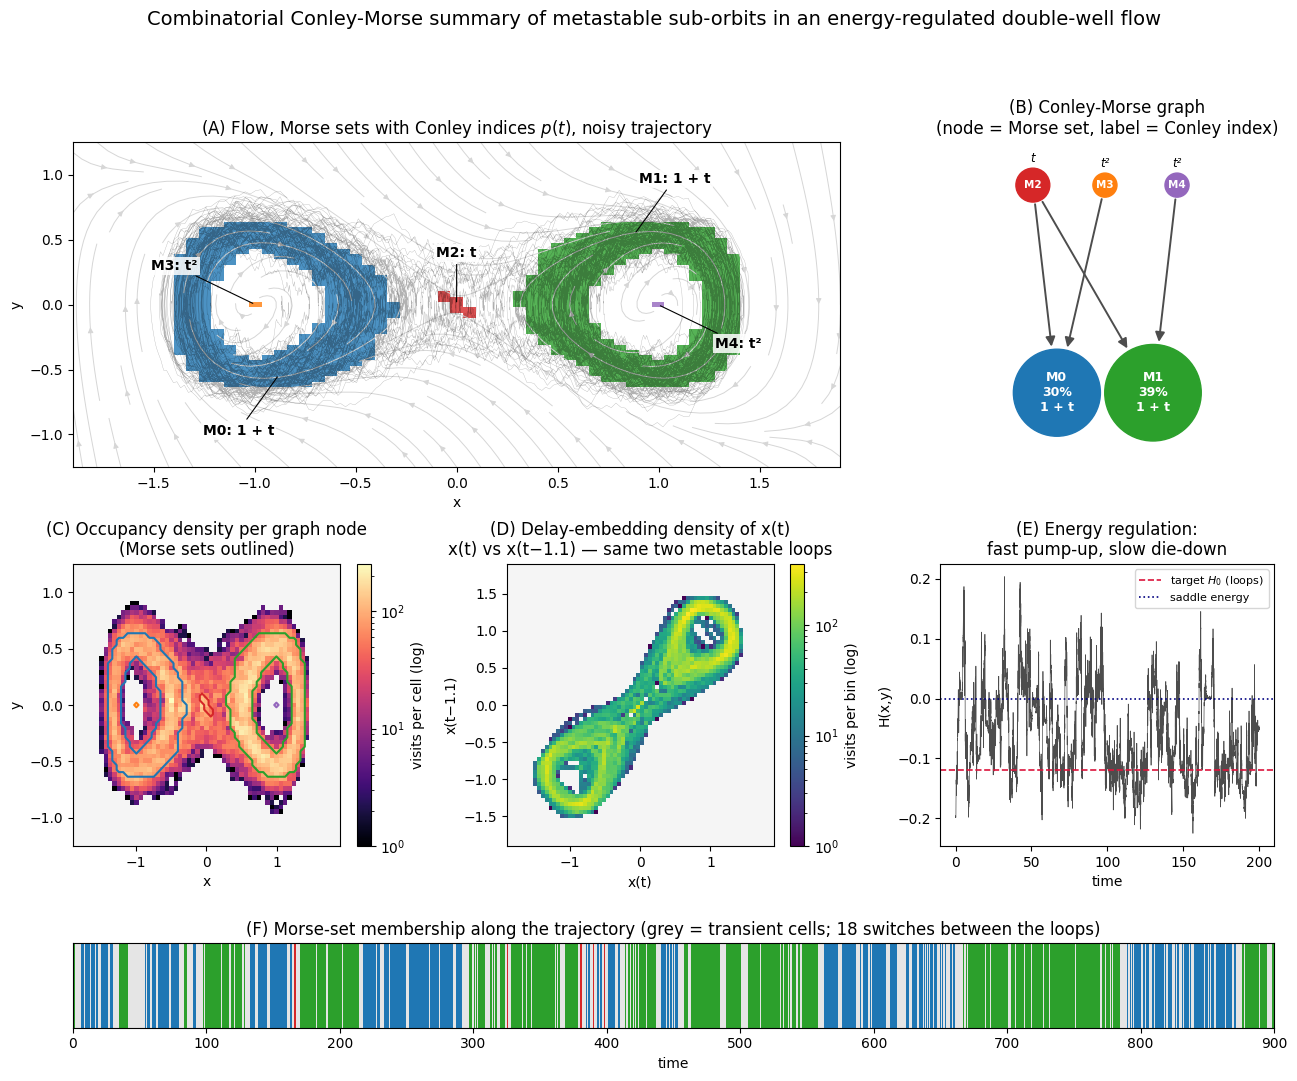

critical cells by dimension: {0: 4, 1: 2, 2: 0}


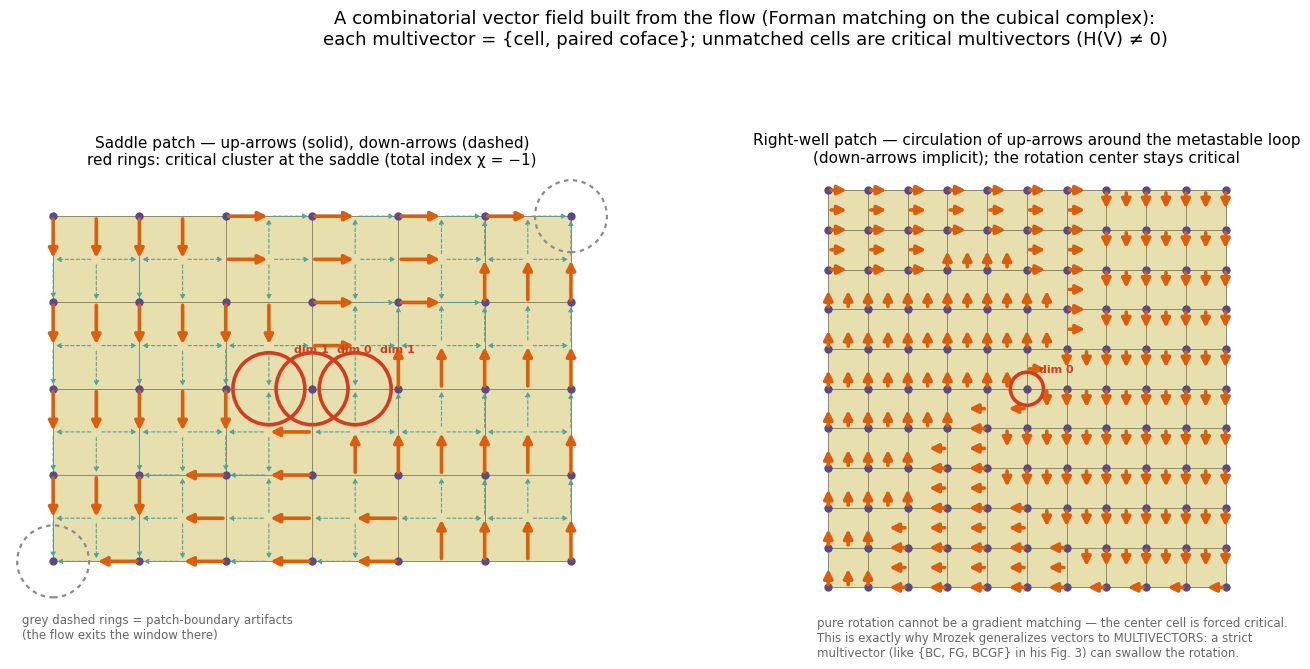

loaded 25 lambda values from sweep_cache.pkl

bars: 9  bifurcation lambdas: [np.float64(-0.19), np.float64(-0.07), np.float64(0.03)]


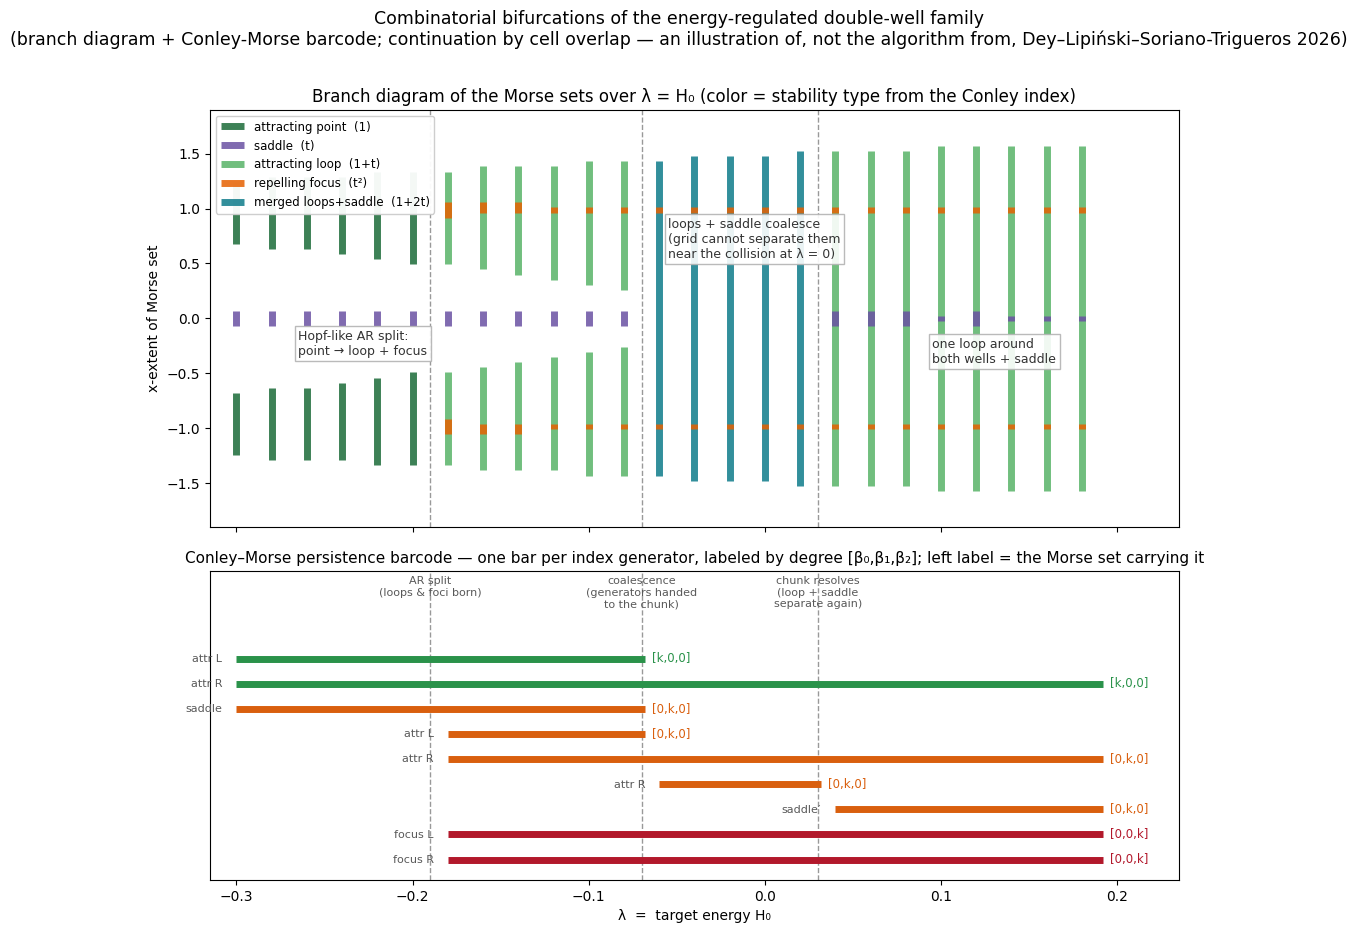

S1 Wang baseline:  accuracy by coherence 0.60: 100%  0.40:  90%  0.20:  75%  0.10:  45%   Morse sets: 3  occ ['34%', '24%', '17%']
S2 Basket control:  accuracy by coherence 0.60: 100%  0.40:  95%  0.20:  65%  0.10:  55%   Morse sets: 2  occ ['69%', '25%']
S3 Selective I:  accuracy by coherence 0.60: 100%  0.40:  95%  0.20:  70%  0.10:  60%   Morse sets: 2  occ ['67%', '26%']


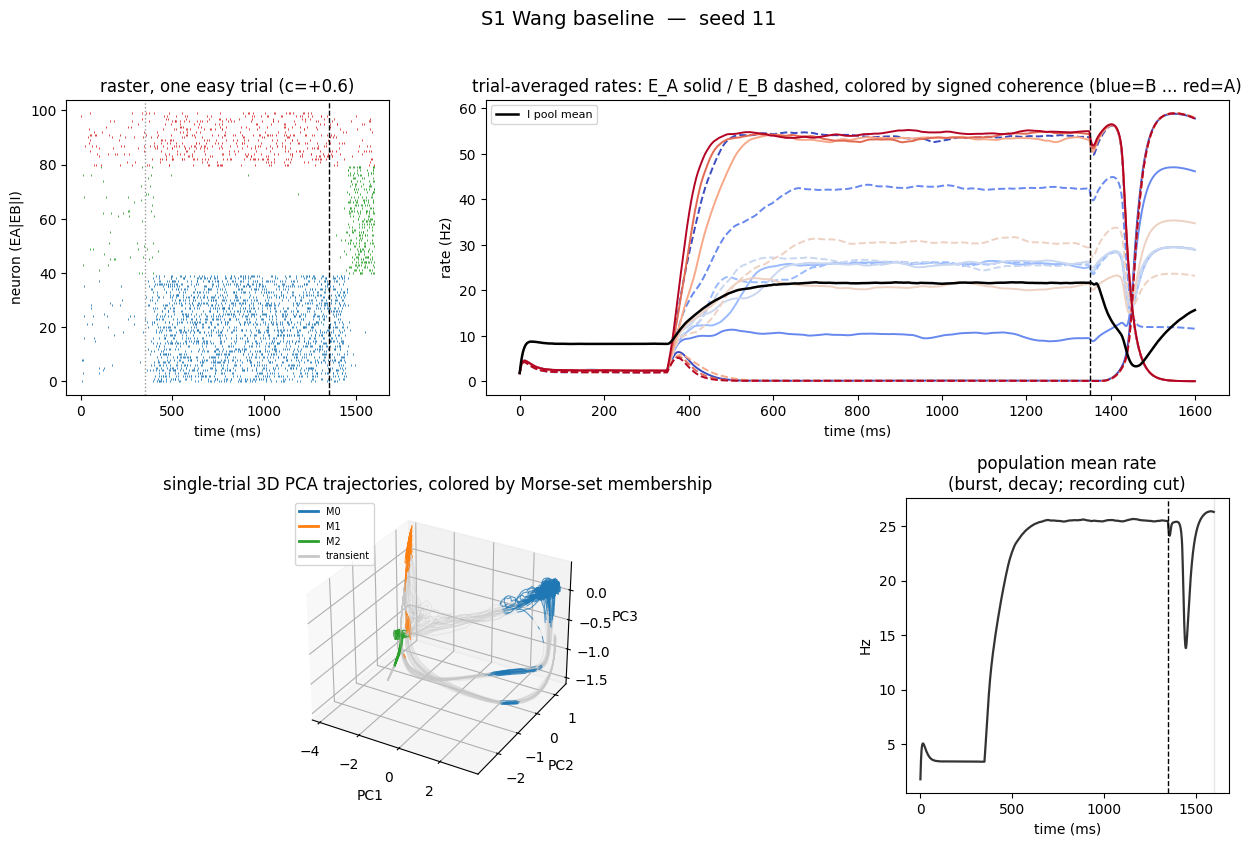

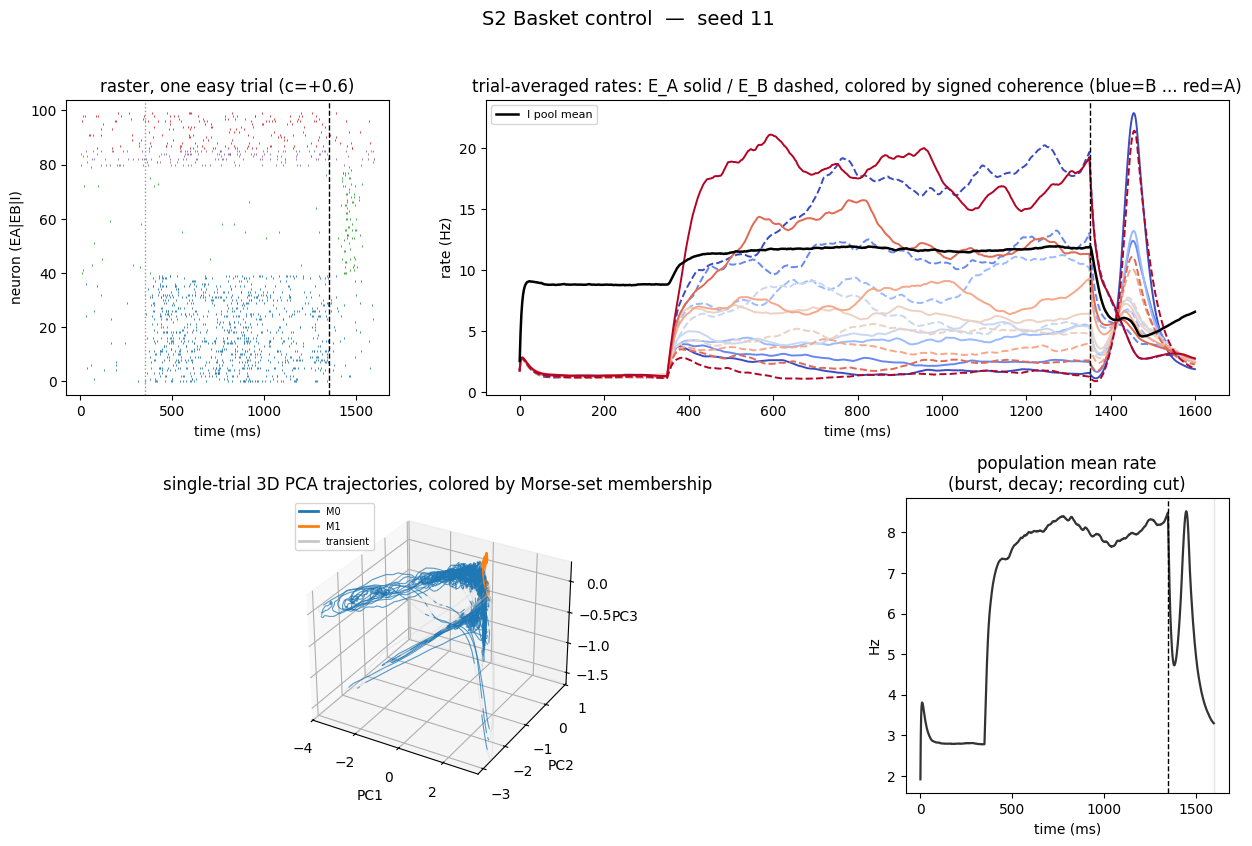

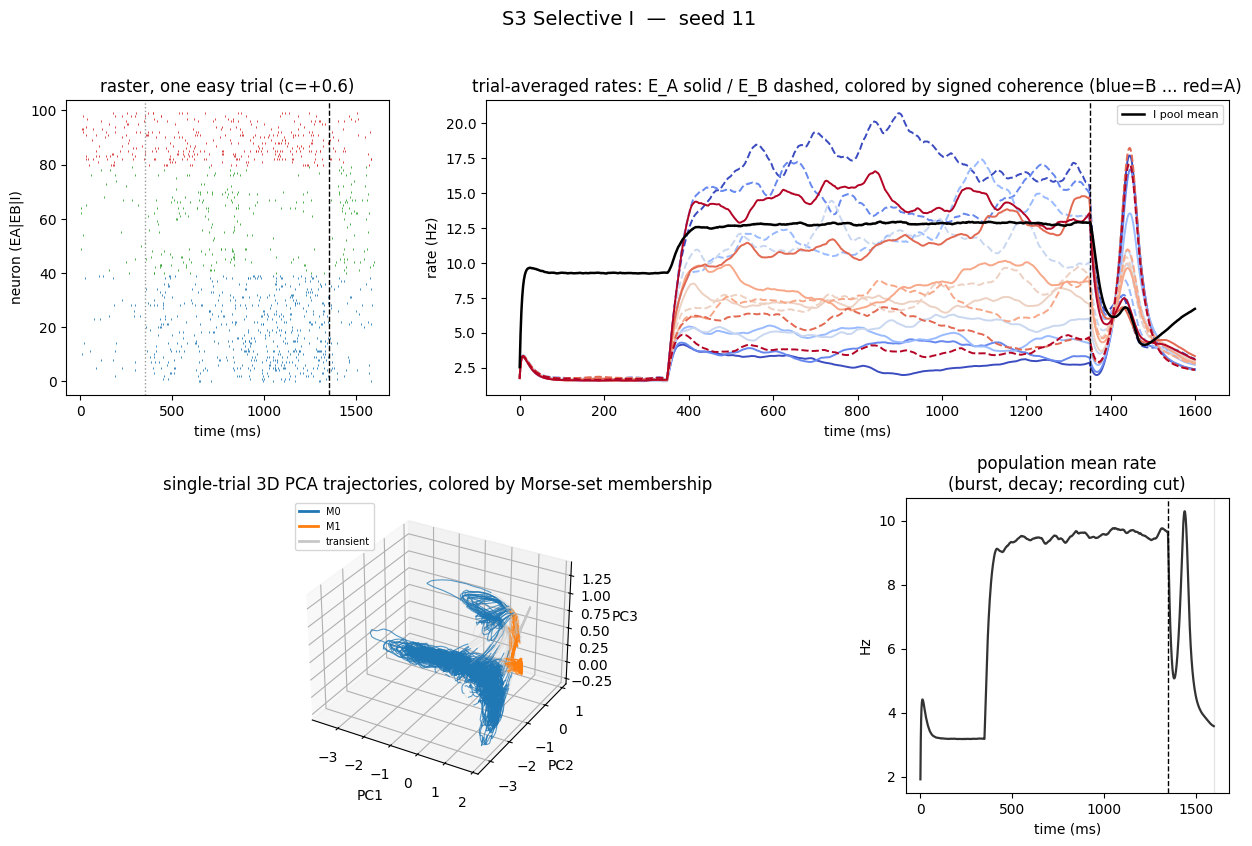

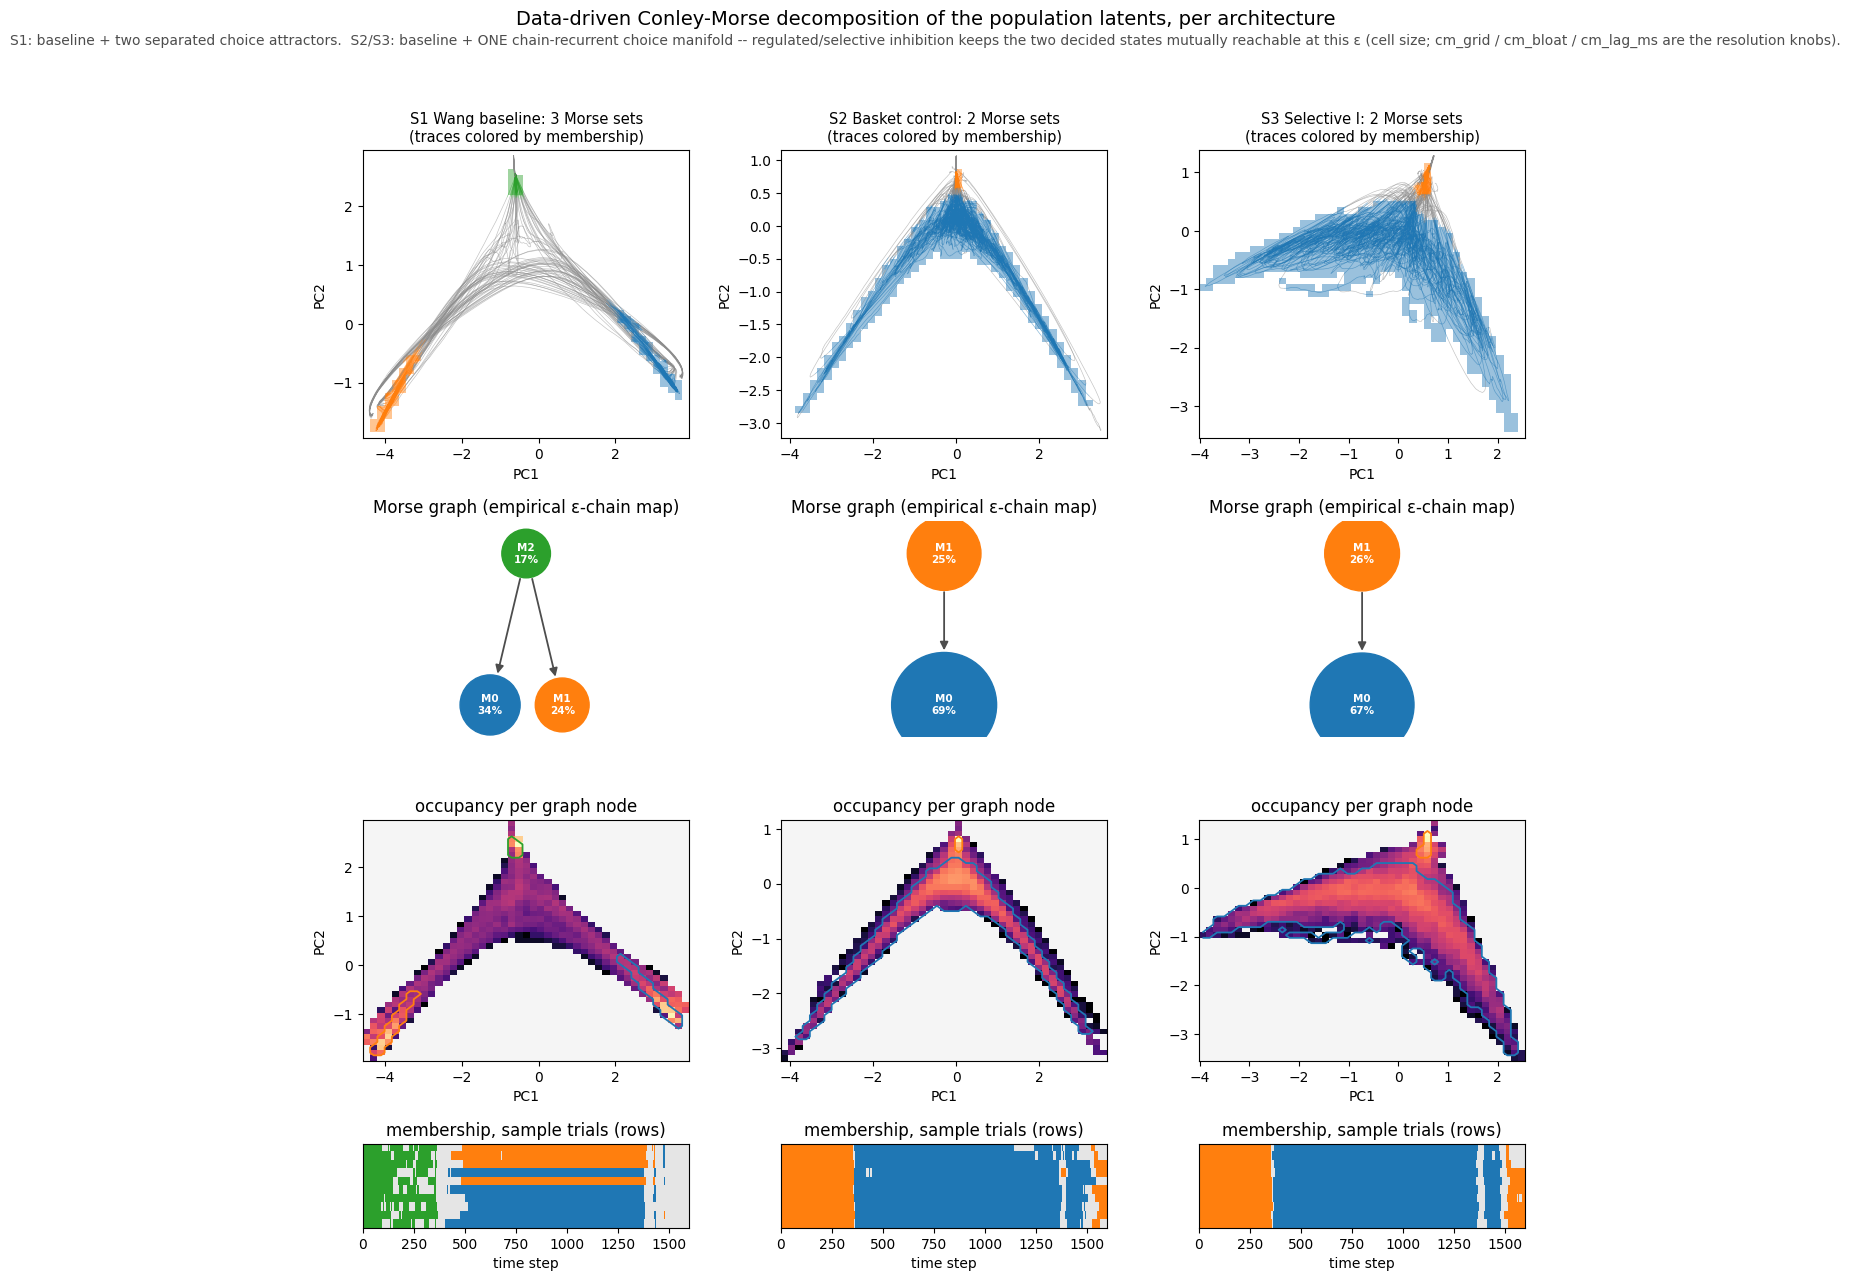

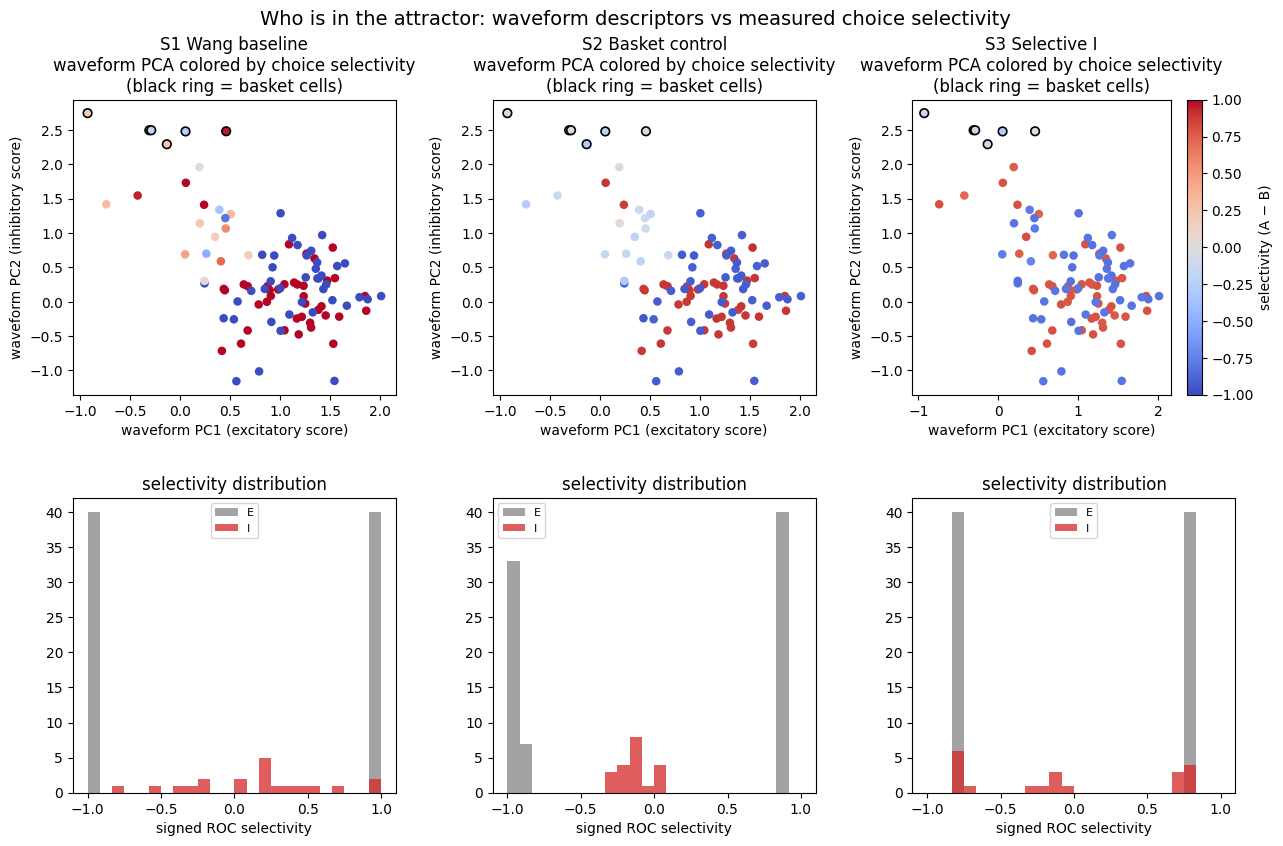

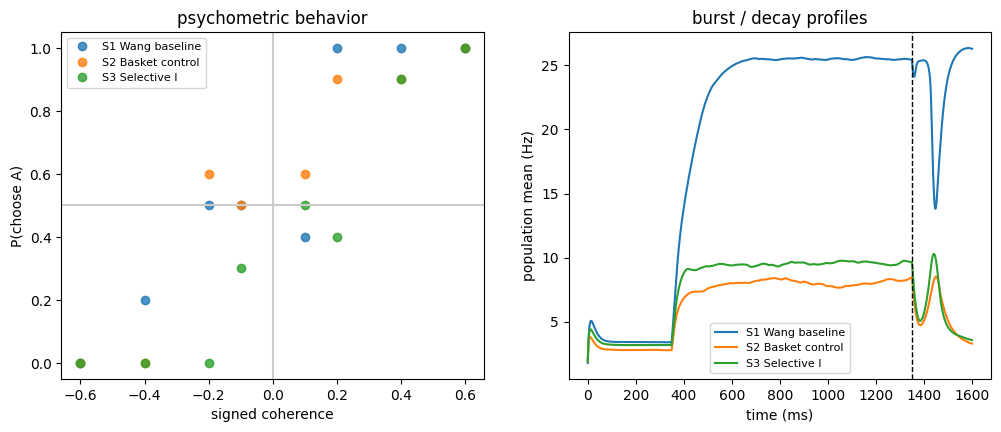

saved decision_scenario{1,2,3}.png, decision_conley_morse.png, decision_waveforms.png, decision_summary.png


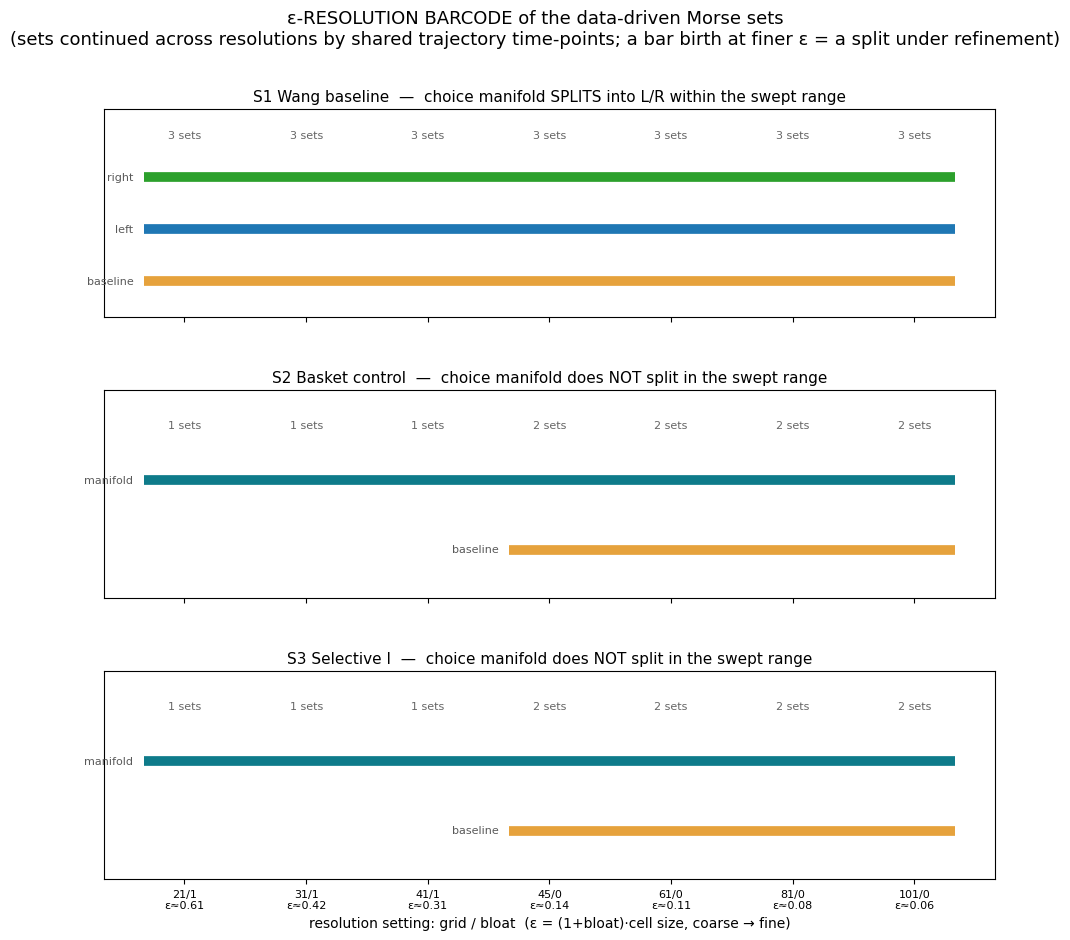

resolution counts per scenario: [[3, 3, 3, 3, 3, 3, 3], [1, 1, 1, 2, 2, 2, 2], [1, 1, 1, 2, 2, 2, 2]]


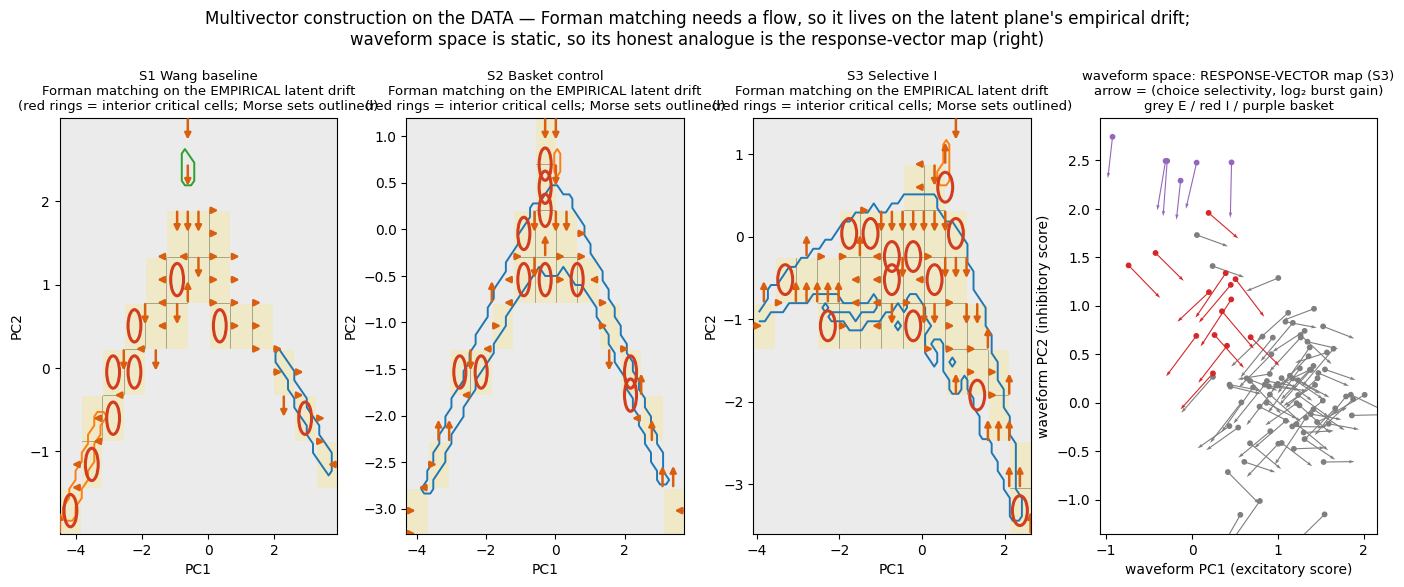

saved decision_resolution_barcode.png, decision_multivector.png


In [3]:
# =============================================================================
# conley_morse_notebook.py
#
# ONE self-contained script / notebook for the combinatorial Conley-Morse
# analysis of a 2D flow with metastable sub-orbits (an energy-regulated
# double-well: each well holds a small attracting loop at target energy H0,
# noise switches the state between wells -- a 2D caricature of Lorenz wings).
#
# Run top-to-bottom, or as cells (the "# %%" markers work in Jupyter/VS Code):
#   cell 1  LIBRARY   flow, grid, bloated time-tau cell map, Morse sets
#                     (recurrent SCCs), Conley-Morse graph, Conley indices
#                     via flow-adapted index pairs + relative cubical
#                     homology over Z/2, Morse-equation check, graph drawing
#   cell 2  FIGURE 1  six-panel summary: Morse sets + computed indices,
#                     Conley-Morse graph, occupancy heatmap per graph node,
#                     delay-embedding density, energy regulation, trajectory
#                     traced through the decomposition
#   cell 3  FIGURE 2  Forman-style combinatorial (multi)vector field on two
#                     cubical patches (saddle + right well)
#   cell 4  FIGURE 3  lambda-sweep over H0: branch diagram + Conley-Morse
#                     persistence barcode (illustration of, not the algorithm
#                     from, Dey-Lipinski-Soriano-Trigueros, FoCM 2026).
#                     ~3 min on first run; results cached in sweep_cache.pkl.
#   cell 5  DECISION  three E/I decision-circuit architectures (Wang /
#                     basket-control / selective-I), 80 trials x 4
#                     coherences, burst+reset; rasters, rates, 3D PCA
#                     colored by Morse-set membership, data-driven
#                     Conley-Morse decomposition of the latents, waveform
#                     descriptor layer, psychometrics (~2 min)
#   cell 6  FIGURE    epsilon-RESOLUTION BARCODE: sweep cm_grid/cm_bloat,
#                     continue Morse sets across resolutions -- does the
#                     soft choice manifold of S2/S3 ever split?
#   cell 7  FIGURE    multivector construction ON THE DATA: Forman matching
#                     on the empirical latent drift per scenario + the
#                     waveform-space response-vector map
#
# Extend from here: swap in your own 2D field in make_field(), re-tune the
# grid/tau/bloat in cell 2, or add lambda-parameterized families in cell 4.
# =============================================================================
# %% ------------------------------------------------- cell 1: LIBRARY
from types import SimpleNamespace

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import FancyArrowPatch, Circle, Rectangle
from matplotlib.collections import LineCollection
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

# ----------------------------------------------------------------------------
# flow
# ----------------------------------------------------------------------------
def make_field(H0, gamma_up=12.0, gamma_down=2.5):
    """Energy-regulated double-well vector field, vectorized."""
    def field(x, y):
        H = 0.5 * y**2 + 0.25 * x**4 - 0.5 * x**2
        g = np.where(H < H0, gamma_up, gamma_down)
        return y, x - x**3 + g * (H0 - H) * y
    return field

def make_rk2(field):
    def rk2(x, y, dt):
        k1x, k1y = field(x, y)
        k2x, k2y = field(x + 0.5 * dt * k1x, y + 0.5 * dt * k1y)
        return x + dt * k2x, y + dt * k2y
    return rk2

# ----------------------------------------------------------------------------
# grid
# ----------------------------------------------------------------------------
def make_grid(NX=61, NY=61, XMIN=-1.9, XMAX=1.9, YMIN=-1.25, YMAX=1.25):
    g = SimpleNamespace(NX=NX, NY=NY, XMIN=XMIN, XMAX=XMAX, YMIN=YMIN, YMAX=YMAX)
    g.x_edges = np.linspace(XMIN, XMAX, NX + 1)
    g.y_edges = np.linspace(YMIN, YMAX, NY + 1)
    g.hx = (XMAX - XMIN) / NX
    g.hy = (YMAX - YMIN) / NY
    g.N = NX * NY
    g.EXT = NX * NY
    return g

def cell_of(g, x, y):
    i = np.floor((x - g.XMIN) / (g.XMAX - g.XMIN) * g.NX).astype(int)
    j = np.floor((y - g.YMIN) / (g.YMAX - g.YMIN) * g.NY).astype(int)
    inside = (i >= 0) & (i < g.NX) & (j >= 0) & (j < g.NY)
    return np.where(inside, j * g.NX + i, -1)

def sample_points(g, cells, fr=(0.1, 0.37, 0.63, 0.9)):
    """k x k fan of sample points inside each listed cell. Returns px, py, src."""
    fr = np.asarray(fr)
    ci, cj = cells % g.NX, cells // g.NX
    cx = g.XMIN + (ci[:, None] + fr[None, :]) * g.hx
    cy = g.YMIN + (cj[:, None] + fr[None, :]) * g.hy
    px = np.repeat(cx, len(fr), axis=1).ravel()
    py = np.tile(cy, (1, len(fr))).ravel()
    src = np.repeat(cells, len(fr) ** 2)
    return px, py, src

# ----------------------------------------------------------------------------
# bloated time-tau multivalued cell map F
# ----------------------------------------------------------------------------
def build_map(g, rk2, dt=0.01, tau_steps=250, bloat=1):
    """Edges (src_cell, dst_cell) of the combinatorial multivalued map."""
    px, py, src = sample_points(g, np.arange(g.N))
    for _ in range(tau_steps):
        px, py = rk2(px, py, dt)
    di = np.floor((px - g.XMIN) / (g.XMAX - g.XMIN) * g.NX).astype(int)
    dj = np.floor((py - g.YMIN) / (g.YMAX - g.YMIN) * g.NY).astype(int)
    offs = [(a, b) for a in range(-bloat, bloat + 1) for b in range(-bloat, bloat + 1)]
    I = np.concatenate([di + a for a, b in offs])
    J = np.concatenate([dj + b for a, b in offs])
    S = np.tile(src, len(offs))
    inside = (I >= 0) & (I < g.NX) & (J >= 0) & (J < g.NY)
    D = np.where(inside, J * g.NX + I, g.EXT)
    return np.unique(np.stack([S, D], axis=1), axis=0)

# ----------------------------------------------------------------------------
# Morse decomposition + reduced Morse graph
# ----------------------------------------------------------------------------
def morse_decomposition(g, edges):
    """Returns (cell_morse, morse_cells, morse_edges, n_exits_to_EXT)."""
    A = coo_matrix((np.ones(len(edges)), (edges[:, 0], edges[:, 1])),
                   shape=(g.N + 1, g.N + 1)).tocsr()
    _, scc = connected_components(A, directed=True, connection='strong')
    size = np.bincount(scc)
    selfloop = np.zeros(len(size), dtype=bool)
    selfloop[scc[edges[edges[:, 0] == edges[:, 1], 0]]] = True
    recurrent = (size > 1) | selfloop
    recurrent[scc[g.EXT]] = False

    def cells(s): return np.flatnonzero(scc[:g.N] == s)
    morse_sccs = sorted(np.flatnonzero(recurrent),
                        key=lambda s: (-size[s], np.mean(cells(s) % g.NX)))
    morse_id = {s: k for k, s in enumerate(morse_sccs)}
    cell_morse = np.full(g.N, -1)
    morse_cells = []
    for s, k in morse_id.items():
        cs = cells(s)
        cell_morse[cs] = k
        morse_cells.append(cs)

    cond = {}
    for u, v in edges:
        if scc[u] != scc[v]:
            cond.setdefault(scc[u], set()).add(scc[v])

    def reach(s0):
        seen, stack, out = {s0}, [s0], set()
        while stack:
            for t in cond.get(stack.pop(), ()):
                if t not in seen:
                    seen.add(t)
                    if recurrent[t]:
                        out.add(t)
                    stack.append(t)
        return out

    R = {s: reach(s) for s in morse_sccs}
    morse_edges = [(morse_id[s], morse_id[t])
                   for s in morse_sccs for t in R[s]
                   if not any(t in R[m] for m in R[s] if m != t)]
    n_exit = int((edges[:, 1] == g.EXT).sum())
    return cell_morse, morse_cells, morse_edges, n_exit

# ----------------------------------------------------------------------------
# GF(2) linear algebra + relative cubical homology of a pair of square sets
# ----------------------------------------------------------------------------
def gf2_rank(A):
    A = A.copy()
    r = 0
    nrows, ncols = A.shape
    for c in range(ncols):
        piv = np.flatnonzero(A[r:, c])
        if len(piv) == 0:
            continue
        p = r + piv[0]
        if p != r:
            A[[r, p]] = A[[p, r]]
        mask = A[:, c].copy()
        mask[r] = False
        A[mask] ^= A[r]
        r += 1
        if r == nrows:
            break
    return r

def _closed_cells(squares):
    """Vertices, edges of the closed cubical complex spanned by (i,j) squares."""
    sq = set(map(tuple, squares))
    verts, hedges, vedges = set(), set(), set()
    for (i, j) in sq:
        verts |= {(i, j), (i + 1, j), (i, j + 1), (i + 1, j + 1)}
        hedges |= {(i, j), (i, j + 1)}          # horizontal edge at (i, j)
        vedges |= {(i, j), (i + 1, j)}          # vertical   edge at (i, j)
    return sq, verts, hedges, vedges

def relative_betti(P1_squares, P2_squares):
    """Betti numbers of H(cl P1, cl P2; Z/2). P2_squares subset of P1_squares."""
    sq1, v1, h1, ve1 = _closed_cells(P1_squares)
    sq2, v2, h2, ve2 = _closed_cells(P2_squares) if len(P2_squares) else \
        (set(), set(), set(), set())
    Q2 = sorted(sq1 - sq2)
    Qh = sorted(h1 - h2)
    Qv = sorted(ve1 - ve2)
    Q1 = [('h', e) for e in Qh] + [('v', e) for e in Qv]
    Q0 = sorted(v1 - v2)
    i1 = {c: n for n, c in enumerate(Q1)}
    i0 = {c: n for n, c in enumerate(Q0)}

    d2 = np.zeros((len(Q1), len(Q2)), dtype=bool)
    for n, (i, j) in enumerate(Q2):
        for c in (('h', (i, j)), ('h', (i, j + 1)),
                  ('v', (i, j)), ('v', (i + 1, j))):
            if c in i1:
                d2[i1[c], n] = True
    d1 = np.zeros((len(Q0), len(Q1)), dtype=bool)
    for n, (kind, (i, j)) in enumerate(Q1):
        ends = ((i, j), (i + 1, j)) if kind == 'h' else ((i, j), (i, j + 1))
        for vtx in ends:
            if vtx in i0:
                d1[i0[vtx], n] = True

    r2 = gf2_rank(d2) if d2.size else 0
    r1 = gf2_rank(d1) if d1.size else 0
    b2 = len(Q2) - r2
    b1 = len(Q1) - r1 - r2
    b0 = len(Q0) - r1
    return (b0, b1, b2)

def poincare_str(betti):
    terms = []
    for k, b in enumerate(betti):
        if b == 0:
            continue
        t = {0: "1", 1: "t", 2: "t²"}[k]
        terms.append(str(b) if (k == 0 and b > 1) else (t if b == 1 else f"{b}{t}"))
    return " + ".join(terms) if terms else "0"

# ----------------------------------------------------------------------------
# Conley index of a Morse set: index pair + relative homology
#
# Two constructions:
#   * equilibrium-like sets (saddle, foci): forward tube + exit squares
#   * attracting sets: a FLOW-ADAPTED ISOLATING BLOCK built from the energy
#     H (which the regulation term makes a two-sided Lyapunov function around
#     the loop): the band {c- <= H <= c+} straddling the target energy is
#     positively invariant exactly -- pumping enters through the inner shell,
#     damping through the outer -- so its exit set is empty and its topology
#     (annulus / disk) carries the index. A cell-hull cannot do this, because
#     grid cells straddling the separatrix drag the hull into the other well.
# ----------------------------------------------------------------------------
def _H(x, y):
    return 0.5 * y**2 + 0.25 * x**4 - 0.5 * x**2

def _n_components(cells):
    """Number of 8-connected components of a set of (i, j) squares."""
    cells = set(cells)
    comps, seen = 0, set()
    for c in cells:
        if c in seen:
            continue
        comps += 1
        stack = [c]
        while stack:
            x = stack.pop()
            if x in seen:
                continue
            seen.add(x)
            for a in (-1, 0, 1):
                for b in (-1, 0, 1):
                    n = (x[0] + a, x[1] + b)
                    if n in cells and n not in seen:
                        stack.append(n)
    return comps

def attracting_block_index(g, rk2, set_cells, H0, other_sets=None,
                           exit_time=2.0, dt=0.01, delta=0.02):
    """
    Index pair for an attracting Morse set at target energy H0, from a
    flow-adapted energy block (the band/sub-level sets of H are exactly
    positively invariant). Shapes:
      * point-attractor blob (H0 <= -0.25, or set contains a well bottom,
        or the set has swallowed everything near a bifurcation):
        disk {H <= hi}, possibly minus holes at remaining OTHER Morse sets
      * loop in one well (H0 < 0): annulus {lo <= H <= hi} in that well
      * merged loop around both wells (H0 > 0): global annulus
    The margin is widened until the cubical carrier is one connected piece;
    exits are tested against the SMOOTH block (H within [lo-delta, hi+delta]
    and on the correct side), not the jagged cell carrier.
    """
    ci = set_cells % g.NX
    xlo = g.XMIN + ci.min() * g.hx
    xhi = g.XMIN + (ci.max() + 1) * g.hx
    mean_x = 0.5 * (xlo + xhi)
    spans = (xlo < -0.3) and (xhi > 0.3)
    fcells = {cell_of(g, np.array([sx]), np.array([0.0]))[0] for sx in (-1., 1.)}
    scell = int(cell_of(g, np.array([0.0]), np.array([0.0]))[0])
    contains_focus = bool(fcells & set(set_cells.tolist()))
    # a set that has swallowed the saddle is a merged bifurcation chunk: its
    # block must be a disk (minus holes at remaining sets), never a band
    contains_saddle = scell in set(set_cells.tolist())

    ii, jj = np.meshgrid(np.arange(g.NX), np.arange(g.NY))
    Xc = g.XMIN + np.stack([ii, ii + 1, ii, ii + 1, ii + 0.5]) * g.hx
    Yc = g.YMIN + np.stack([jj, jj, jj + 1, jj + 1, jj + 0.5]) * g.hy
    Hs = _H(Xc, Yc)
    Hmin, Hmax = Hs.min(axis=0), Hs.max(axis=0)
    xc = g.XMIN + (ii + 0.5) * g.hx

    holes = set()
    if other_sets:
        for cs in other_sets:
            holes |= _dilate(g, cs, 2)

    shape = None
    for margin in (0.5, 0.65, 0.8, 0.92):
        if spans and H0 > 0 and not contains_saddle:   # global annulus
            lo = max(1e-4, H0 - margin * H0)
            hi = H0 + margin * (0.25 - H0)
            keep = (Hmin >= lo) & (Hmax <= hi)
            shape, well = 'band', 0
        elif (spans or contains_saddle or H0 <= -0.25
              or contains_focus):               # disk (minus holes)
            lo = -np.inf
            glob = spans or contains_saddle
            hi = (H0 + margin * (0.0 - H0)) if (H0 < 0 and not glob) \
                else (max(0.02, H0) + 0.06)
            keep = Hmax <= hi
            shape = 'disk'
            well = 0 if glob else (-1 if mean_x < 0 else 1)
        else:                                   # annulus in one well
            lo = H0 - margin * (H0 + 0.25)
            hi = H0 + margin * (0.0 - H0)
            keep = (Hmin >= lo) & (Hmax <= hi)
            shape, well = 'band', (-1 if mean_x < 0 else 1)
        if well < 0:
            keep = keep & (xc < 0)
        elif well > 0:
            keep = keep & (xc > 0)
        P1 = set(zip(ii[keep].ravel().tolist(), jj[keep].ravel().tolist()))
        P1 -= holes
        if P1 and _n_components(P1) == 1:
            break

    P1_cells = np.array(sorted(i + j * g.NX for i, j in P1))
    if len(P1_cells) == 0:
        return (0, 0, 0), SimpleNamespace(P1=[], P2=[], isolated=False,
                                          tube_time=0.0)
    # exit test against the smooth block
    px, py, src = sample_points(g, P1_cells)
    for _ in range(max(1, int(round(exit_time / dt)))):
        px, py = rk2(px, py, dt)
    Hf = _H(px, py)
    ok = (Hf <= hi + delta)
    if shape == 'band':
        ok &= (Hf >= lo - delta)
    if well < 0:
        ok &= (px < 0.05)
    elif well > 0:
        ok &= (px > -0.05)
    if holes:                                   # landing inside a hole = exit
        hc = cell_of(g, px, py)
        hole_ids = {i + j * g.NX for i, j in holes}
        ok &= ~np.isin(hc, list(hole_ids))
    exit_cells = np.unique(src[~ok])
    P2 = [(c % g.NX, c // g.NX) for c in exit_cells]
    betti = relative_betti(sorted(P1), sorted(P2))
    return betti, SimpleNamespace(P1=sorted(P1), P2=sorted(P2), isolated=True,
                                  tube_time=0.0)

def repelling_block_index(g, set_cells, lam, margin=0.6):
    """
    Flow-adapted index pair for a repelling focus at a well bottom (lam >
    -0.25 makes the bottoms unstable): P1 = energy disk {H <= c} around the
    bottom with -0.25 < c < lam. Pumping pushes H up through its entire
    boundary, so the exit set is the whole combinatorial boundary ring and
    H(P1, P2) = t^2 exactly. (Mirror image of the attracting energy block.)
    """
    ci = set_cells % g.NX
    mean_x = np.mean(g.XMIN + (ci + 0.5) * g.hx)
    sgn = -1 if mean_x < 0 else 1
    c = -0.25 + margin * (lam + 0.25)
    ii, jj = np.meshgrid(np.arange(g.NX), np.arange(g.NY))
    Xc = g.XMIN + np.stack([ii, ii + 1, ii, ii + 1, ii + 0.5]) * g.hx
    Yc = g.YMIN + np.stack([jj, jj, jj + 1, jj + 1, jj + 0.5]) * g.hy
    Hmax = _H(Xc, Yc).max(axis=0)
    xc = g.XMIN + (ii + 0.5) * g.hx
    keep = (Hmax <= c) & ((xc < 0) if sgn < 0 else (xc > 0))
    P1 = set(zip(ii[keep].ravel().tolist(), jj[keep].ravel().tolist()))
    if not P1:                                # disk under grid resolution:
        P1 = _dilate(g, set_cells, 1)         # fall back to dilated cells
    P2 = [c_ for c_ in P1
          if any((c_[0] + a, c_[1] + b) not in P1
                 for a in (-1, 0, 1) for b in (-1, 0, 1))]
    betti = relative_betti(sorted(P1), sorted(P2))
    return betti, SimpleNamespace(P1=sorted(P1), P2=sorted(P2), isolated=True,
                                  tube_time=0.0)

def equilibrium_cells(g):
    """Grid cells of the three equilibria: left bottom, saddle, right bottom."""
    return {name: int(cell_of(g, np.array([x]), np.array([0.0]))[0])
            for name, x in (('left', -1.0), ('saddle', 0.0), ('right', 1.0))}

def merge_adjacent_sets(g, morse_cells, radius=1):
    """Union Morse sets whose cells come within `radius` cells of each other
    (combinatorial Morse decompositions may always be coarsened; this absorbs
    splinter SCCs produced by near-neutral slow regions)."""
    n = len(morse_cells)
    parent = list(range(n))
    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a
    pts = [set(zip((cs % g.NX).tolist(), (cs // g.NX).tolist()))
           for cs in morse_cells]
    dil = [_dilate(g, cs, radius) for cs in morse_cells]
    for a in range(n):
        for b in range(a + 1, n):
            if dil[a] & pts[b]:
                parent[find(a)] = find(b)
    groups = {}
    for k in range(n):
        groups.setdefault(find(k), []).append(k)
    merged = [np.unique(np.concatenate([morse_cells[k] for k in ks]))
              for ks in groups.values()]
    return sorted(merged, key=lambda cs: (-len(cs), float(np.mean(cs % g.NX))))

def _dilate(g, cells, r=1):
    ci, cj = cells % g.NX, cells // g.NX
    out = set()
    for a in range(-r, r + 1):
        for b in range(-r, r + 1):
            I, J = ci + a, cj + b
            ok = (I >= 0) & (I < g.NX) & (J >= 0) & (J < g.NY)
            out |= set(zip(I[ok].tolist(), J[ok].tolist()))
    return out

def conley_index(g, rk2, set_cells, tube_time, exit_time,
                 dt=0.01, snapshots=10, forbidden=None, max_retry=3):
    """
    Forward-tube index pair for an equilibrium-like Morse set:
      P1 = 1-cell dilation of (set cells + cells swept by the flow over
           [0, tube_time], recorded at `snapshots` intermediate times)
      P2 = squares of P1 any of whose sample points leave P1 within exit_time
    Returns (betti, info). `forbidden` = cells of OTHER Morse sets; the tube
    is shrunk (retries) if it touches them, so the pair stays isolating.
    The time scale is also retried downward if the pair comes out degenerate
    (e.g. the quotient core disconnects for a very unstable saddle).
    Attracting sets should use attracting_block_index instead.
    """
    result = None
    for scale in (1.0, 0.65, 0.45, 0.3):
        tt, et = tube_time * scale, exit_time * scale
        fset = set()
        for attempt in range(max_retry):
            swept = set(zip((set_cells % g.NX).tolist(),
                            (set_cells // g.NX).tolist()))
            if tt > 0:
                px, py, _ = sample_points(g, set_cells)
                steps = max(1, int(round(tt / dt)))
                rec = np.unique(np.linspace(0, steps, snapshots + 1).astype(int))
                for s in range(1, steps + 1):
                    px, py = rk2(px, py, dt)
                    if s in rec:
                        c = cell_of(g, px, py)
                        c = c[c >= 0]
                        swept |= set(zip((c % g.NX).tolist(),
                                         (c // g.NX).tolist()))
            P1 = _dilate(g, np.array([i + j * g.NX for i, j in swept]), 1)

            if forbidden is not None and len(forbidden):
                fset = set(zip((forbidden % g.NX).tolist(),
                               (forbidden // g.NX).tolist()))
                if P1 & fset:
                    tt *= 0.6             # tube touched another Morse set
                    continue
            break
        isolated = not (P1 & fset)

        # exit squares: any sample point leaves P1 within exit_time
        P1_cells = np.array(sorted(i + j * g.NX for i, j in P1))
        px, py, src = sample_points(g, P1_cells)
        for _ in range(max(1, int(round(et / dt)))):
            px, py = rk2(px, py, dt)
        dest = cell_of(g, px, py)
        in_P1 = np.isin(dest, P1_cells) & (dest >= 0)
        exit_cells = np.unique(src[~in_P1])
        P2 = [(c % g.NX, c // g.NX) for c in exit_cells]

        betti = relative_betti(sorted(P1), sorted(P2))
        result = (betti, SimpleNamespace(P1=sorted(P1), P2=sorted(P2),
                                         isolated=isolated, tube_time=tt))
        if max(betti) <= 1 and 1 <= sum(betti) <= 2:   # elementary index: done
            break
    return result

def index_params_for(set_cells, g):
    """Heuristic (tube_time, exit_time) per Morse-set size/kind."""
    if len(set_cells) > 20:               # loop annulus or attracting blob
        return 0.0, 2.5
    return 1.1, 1.1                       # equilibrium-like (saddle / focus)

# ----------------------------------------------------------------------------
# Morse-equation check
# ----------------------------------------------------------------------------
def morse_equation(bettis, pX=(1, 0, 0)):
    """sum p_M(t) - p_X(t) must equal (1+t) q(t), q >= 0. Returns q or None."""
    tot = [sum(b[k] for b in bettis) - pX[k] for k in range(3)]
    # divide 'tot' (degree <= 2) by (1+t): synthetic division
    q0 = tot[0]
    q1 = tot[1] - q0
    rem = tot[2] - q1
    if rem != 0 or q0 < 0 or q1 < 0:
        return None
    return (q0, q1)

# ----------------------------------------------------------------------------
# Morse-graph drawing (Hasse diagram, rim-offset arrows, p(t) labels)
# ----------------------------------------------------------------------------
def layout_morse_graph(n, edges):
    """Longest-path layering + barycenter ordering within layers."""
    depth = {k: 0 for k in range(n)}
    for _ in range(n):
        for a, b in edges:
            depth[b] = max(depth[b], depth[a] + 1)
    maxd = max(depth.values()) if n else 0
    layers = {}
    for k in range(n):
        layers.setdefault(depth[k], []).append(k)
    # barycenter pass: order each layer by mean x of connected nodes above
    dy = max(0.72 / max(maxd, 1), 0.26)      # adaptive spacing for deep graphs
    pos = {}
    for d in sorted(layers):
        ks = layers[d]
        if d > 0:
            def bary(k):
                nb = [pos[a][0] for a, b in edges if b == k and a in pos]
                return np.mean(nb) if nb else 0.5
            ks = sorted(ks, key=bary)
        for q, k in enumerate(ks):
            pos[k] = ((q + 1) / (len(ks) + 1), 0.88 - dy * d)
    return pos, depth, maxd

def draw_morse_graph(ax, edges, occ, labels=None, colors=None, names=None,
                     min_r=0.05, max_extra=0.24):
    """
    Nodes sized by occupancy, arrows start/end ON NODE RIMS (computed in data
    coordinates, so heads are never hidden under the disks), p(t) labels
    inside big nodes / beside small ones. All radii are globally rescaled so
    that no two disks can overlap and every edge keeps room for an arrowhead.
    ax gets equal aspect and [0,1]^2 limits.
    """
    import matplotlib.pyplot as plt
    from matplotlib.patches import FancyArrowPatch, Circle

    n = len(occ)
    occ = np.asarray(occ, dtype=float)
    if colors is None:
        colors = plt.cm.tab10(np.linspace(0, 1, 10))[:max(n, 1)]
    if names is None:
        names = [f"M{k}" for k in range(n)]
    pos, depth, maxd = layout_morse_graph(n, edges)
    radii = {k: min_r + max_extra * np.sqrt(occ[k]) for k in range(n)}

    # global shrink so disks never collide and arrows keep >= 0.09 of room
    edge_set = {tuple(sorted(e)) for e in edges}
    scale = 1.0
    for a in range(n):
        for b in range(a + 1, n):
            d = np.linalg.norm(np.array(pos[a]) - np.array(pos[b]))
            gap = 0.09 if (a, b) in edge_set else 0.015
            if radii[a] + radii[b] > 0:
                scale = min(scale, max(d - gap, 0.02) / (radii[a] + radii[b]))
    radii = {k: r * scale for k, r in radii.items()}

    ax.set_aspect('equal')
    xs = [pos[k][0] for k in range(n)]; ys = [pos[k][1] for k in range(n)]
    rs = [radii[k] for k in range(n)]
    ax.set_xlim(min(x - r for x, r in zip(xs, rs)) - 0.12,
                max(x + r for x, r in zip(xs, rs)) + 0.12)
    ax.set_ylim(min(y - r for y, r in zip(ys, rs)) - 0.09,
                max(y + r for y, r in zip(ys, rs)) + 0.09)
    ax.set_axis_off()

    for a, b in edges:
        pa, pb = np.array(pos[a]), np.array(pos[b])
        u = pb - pa
        L = np.linalg.norm(u)
        if L < 1e-9:
            continue
        u = u / L
        start = pa + u * (radii[a] + 0.008)
        end = pb - u * (radii[b] + 0.010)
        ax.add_patch(FancyArrowPatch(start, end, arrowstyle='-|>',
                                     mutation_scale=14, color='0.3',
                                     lw=1.4, shrinkA=0, shrinkB=0, zorder=2))
    for k in range(n):
        r = radii[k]
        ax.add_patch(Circle(pos[k], r, color=colors[k], zorder=3))
        big = r >= 0.10
        inside = names[k]
        if big and occ[k] >= 0.005:
            inside += f"\n{occ[k]*100:.0f}%"
        if big and labels is not None:
            inside += f"\n{labels[k]}"
        ax.text(pos[k][0], pos[k][1], inside, ha='center', va='center',
                fontsize=9 if big else 7.5, color='white',
                fontweight='bold', zorder=4)
        if labels is not None and not big:
            # small node: label above (top layer), below (bottom layer),
            # or at the side (middle layers), away from the arrows
            if depth[k] == 0:
                xy, ha, va = (pos[k][0], pos[k][1] + r + 0.012), 'center', 'bottom'
            elif depth[k] == maxd:
                xy, ha, va = (pos[k][0], pos[k][1] - r - 0.012), 'center', 'top'
            else:
                side = 1 if pos[k][0] <= 0.55 else -1
                xy = (pos[k][0] + side * (r + 0.015), pos[k][1])
                ha, va = ('left' if side > 0 else 'right'), 'center'
            ax.text(*xy, labels[k], ha=ha, va=va,
                    fontsize=8.5, style='italic', zorder=4,
                    bbox=dict(fc='white', ec='none', alpha=0.75, pad=1.0))
    return pos


# %% ------------------------------------------------- cell 2: FIGURE 1 -- Conley-Morse summary of the H0 = -0.12 system


rng = np.random.default_rng(7)

H0, DT = -0.12, 0.01
field = make_field(H0)
rk2 = make_rk2(field)
g = make_grid()

# --- combinatorial map + Morse decomposition --------------------------------
edges = build_map(g, rk2, dt=DT, tau_steps=250, bloat=1)
cell_morse, morse_cells, morse_edges, n_exit = morse_decomposition(g, edges)
n_morse = len(morse_cells)

# --- Conley indices via index pairs (P1 = forward tube, P2 = exit squares) --
bettis, pair_info = [], []
all_cells = np.concatenate(morse_cells)
for k, cs in enumerate(morse_cells):
    if len(cs) > 20:                      # attracting set: energy-band block
        b, info = attracting_block_index(g, rk2, cs, H0, dt=DT)
    else:                                 # equilibrium-like: forward tube
        tube_t, exit_t = index_params_for(cs, g)
        b, info = conley_index(g, rk2, cs, tube_t, exit_t, dt=DT,
                                  forbidden=np.setdiff1d(all_cells, cs))
    bettis.append(b)
    pair_info.append(info)

labels = [poincare_str(b) for b in bettis]
q = morse_equation(bettis, pX=(1, 0, 0))

print(f"Morse sets: {n_morse}   (cells mapping out of window: {n_exit})")
for k, (cs, b, info) in enumerate(zip(morse_cells, bettis, pair_info)):
    print(f"  M{k}: {len(cs):4d} cells   Con = ({b[0]},{b[1]},{b[2]})  "
          f"p(t) = {labels[k]:7s}  |P1|={len(info.P1):4d} |P2|={len(info.P2):3d}"
          f"  isolated={info.isolated}")
print("Conley-Morse edges:", [(f"M{a}", f"M{b}") for a, b in morse_edges])
tot = tuple(sum(b[k] for b in bettis) for k in range(3))
if q is not None:
    print(f"Morse equation:  sum p_M = {poincare_str(tot)}"
          f"  =  p_X + (1+t) q(t)  with p_X = 1,  q(t) = {poincare_str((*q, 0))}"
          f"  ->  BALANCED (q >= 0 certifies the forced connecting orbits)")
else:
    print(f"Morse equation:  sum p_M = {poincare_str(tot)}  "
          f"did NOT balance against p_X = 1 (window not a trapping region?)")

# --- long noisy trajectory: densities, delay embedding, tracing -------------
STEPS, SIGMA = 90_000, 0.19
tx, ty = np.empty(STEPS), np.empty(STEPS)
x, y = 1.2, 0.1
for t in range(STEPS):
    x, y = rk2(x, y, DT)
    y += SIGMA * np.sqrt(DT) * rng.standard_normal()
    x = np.clip(x, g.XMIN + 1e-6, g.XMAX - 1e-6)
    y = np.clip(y, g.YMIN + 1e-6, g.YMAX - 1e-6)
    tx[t], ty[t] = x, y

traj_cells = cell_of(g, tx, ty)
density = np.bincount(traj_cells, minlength=g.N).reshape(g.NY, g.NX).astype(float)
trace = cell_morse[traj_cells]
occ = np.array([(trace == k).sum() for k in range(n_morse)]) / STEPS
visits = trace[np.isin(trace, [0, 1])]
switches = int(np.sum(visits[1:] != visits[:-1]))
print(f"Loop-to-loop switches in trajectory: {switches}")

LAG = 110
emb_hist, ex_e, ey_e = np.histogram2d(tx[LAG:], tx[:-LAG], bins=70,
                                      range=[[g.XMIN, g.XMAX], [g.XMIN, g.XMAX]])

# ----------------------------------------------------------------------------
# Figure
# ----------------------------------------------------------------------------
morse_colors = np.array(plt.cm.tab10.colors)[[0, 2, 3, 1, 4, 5, 6, 7, 8, 9][:n_morse]]
fig = plt.figure(figsize=(15.5, 11.5))
gs = fig.add_gridspec(3, 3, height_ratios=[1.15, 1, 0.3], hspace=0.42, wspace=0.3)

# (A) phase space
axA = fig.add_subplot(gs[0, 0:2])
gx, gy = np.meshgrid(np.linspace(g.XMIN, g.XMAX, 26), np.linspace(g.YMIN, g.YMAX, 18))
u, v = field(gx, gy)
axA.streamplot(gx, gy, u, v, color='0.84', density=1.1, linewidth=0.7, arrowsize=0.8)
overlay = np.ma.masked_where(cell_morse.reshape(g.NY, g.NX) < 0,
                             cell_morse.reshape(g.NY, g.NX))
axA.pcolormesh(g.x_edges, g.y_edges, overlay,
               cmap=mcolors.ListedColormap(morse_colors),
               vmin=-0.5, vmax=n_morse - 0.5, alpha=0.8)
axA.plot(tx[::3], ty[::3], color='k', lw=0.25, alpha=0.3)
anchor_off = {0: (0, -0.52), 1: (0, 0.52)}
text_off = {0: (-0.2, -0.95), 1: (0.2, 0.95),
            2: (0, 0.4), 3: (-0.4, 0.3), 4: (0.4, -0.3)}
for k in range(n_morse):
    cs = morse_cells[k]
    mx = np.mean(g.XMIN + (cs % g.NX + 0.5) * g.hx)
    my = np.mean(g.YMIN + (cs // g.NX + 0.5) * g.hy)
    ax_, ay_ = anchor_off.get(k, (0, 0))
    tx_, ty_ = text_off.get(k, (0, 0))
    axA.annotate(f"M{k}: {labels[k]}", (mx + ax_, my + ay_), (mx + tx_, my + ty_),
                 fontsize=10, fontweight='bold', ha='center', va='center',
                 arrowprops=dict(arrowstyle='-', lw=0.8) if (tx_ or ty_) else None,
                 bbox=dict(fc='white', alpha=0.85, ec='none', pad=1.5))
axA.set_title("(A) Flow, Morse sets with Conley indices $p(t)$, noisy trajectory")
axA.set_xlabel("x"); axA.set_ylabel("y")

# (B) Conley-Morse graph with p(t) labels (rim-offset arrows)
axB = fig.add_subplot(gs[0, 2])
axB.set_title("(B) Conley-Morse graph\n(node = Morse set, label = Conley index)")
draw_morse_graph(axB, morse_edges, occ, labels=labels, colors=morse_colors)

# (C) occupancy density per graph node
axC = fig.add_subplot(gs[1, 0])
pc = axC.pcolormesh(g.x_edges, g.y_edges, np.ma.masked_less(density, 1),
                    norm=mcolors.LogNorm(vmin=1), cmap='magma')
fig.colorbar(pc, ax=axC, label="visits per cell (log)")
cxs = 0.5 * (g.x_edges[:-1] + g.x_edges[1:])
cys = 0.5 * (g.y_edges[:-1] + g.y_edges[1:])
for k in range(n_morse):
    axC.contour(cxs, cys, (cell_morse.reshape(g.NY, g.NX) == k).astype(float),
                levels=[0.5], colors=[morse_colors[k]], linewidths=1.5)
axC.set_facecolor('0.96')
axC.set_title("(C) Occupancy density per graph node\n(Morse sets outlined)")
axC.set_xlabel("x"); axC.set_ylabel("y")

# (D) delay-embedding density
axD = fig.add_subplot(gs[1, 1])
pd_ = axD.pcolormesh(ex_e, ey_e, np.ma.masked_less(emb_hist.T, 1),
                     norm=mcolors.LogNorm(vmin=1), cmap='viridis')
fig.colorbar(pd_, ax=axD, label="visits per bin (log)")
axD.set_facecolor('0.96')
axD.set_title(f"(D) Delay-embedding density of x(t)\n"
              f"x(t) vs x(t−{LAG*DT:.1f}) — same two metastable loops")
axD.set_xlabel("x(t)"); axD.set_ylabel(f"x(t−{LAG*DT:.1f})")

# (E) energy regulation
axE = fig.add_subplot(gs[1, 2])
tseg = slice(0, 20_000)
tt = np.arange(STEPS) * DT
axE.plot(tt[tseg], 0.5*ty[tseg]**2 + 0.25*tx[tseg]**4 - 0.5*tx[tseg]**2,
         lw=0.5, color='0.3')
axE.axhline(H0, color='crimson', ls='--', lw=1.2, label='target $H_0$ (loops)')
axE.axhline(0.0, color='navy', ls=':', lw=1.2, label='saddle energy')
axE.set_title("(E) Energy regulation:\nfast pump-up, slow die-down")
axE.set_xlabel("time"); axE.set_ylabel("H(x,y)")
axE.legend(fontsize=8, loc='upper right')

# (F) trajectory traced through the decomposition
axF = fig.add_subplot(gs[2, :])
strip = mcolors.ListedColormap(['0.9'] + [tuple(c) for c in morse_colors])
axF.imshow((trace + 1)[None, :], aspect='auto', cmap=strip,
           vmin=-0.5, vmax=n_morse + 0.5,
           extent=[0, STEPS * DT, 0, 1], interpolation='nearest')
axF.set_yticks([]); axF.set_xlabel("time")
axF.set_title(f"(F) Morse-set membership along the trajectory "
              f"(grey = transient cells; {switches} switches between the loops)")

fig.suptitle("Combinatorial Conley-Morse summary of metastable sub-orbits in an "
             "energy-regulated double-well flow", fontsize=14, y=0.995)
fig.savefig("morse_metastable.png", dpi=140, bbox_inches='tight')
plt.show()


# %% ------------------------------------------------- cell 3: FIGURE 2 -- combinatorial (multi)vector field


field = make_field(-0.12)

# ---------------------------------------------------------------- complexes
def build_patch(x0, x1, y0, y1, nx, ny):
    xs = np.linspace(x0, x1, nx + 1)
    ys = np.linspace(y0, y1, ny + 1)
    verts = {(i, j): (xs[i], ys[j]) for i in range(nx + 1) for j in range(ny + 1)}
    edges = {}
    for i in range(nx):
        for j in range(ny + 1):
            edges[('h', i, j)] = ((xs[i] + xs[i + 1]) / 2, ys[j])
    for i in range(nx + 1):
        for j in range(ny):
            edges[('v', i, j)] = (xs[i], (ys[j] + ys[j + 1]) / 2)
    squares = {('q', i, j): ((xs[i] + xs[i + 1]) / 2, (ys[j] + ys[j + 1]) / 2)
               for i in range(nx) for j in range(ny)}
    return xs, ys, verts, edges, squares

def vertex_edges(v, nx, ny):
    i, j = v
    out = []
    if i < nx:  out.append((('h', i, j),     np.array([+1., 0.])))
    if i > 0:   out.append((('h', i - 1, j), np.array([-1., 0.])))
    if j < ny:  out.append((('v', i, j),     np.array([0., +1.])))
    if j > 0:   out.append((('v', i, j - 1), np.array([0., -1.])))
    return out

def edge_squares(e, nx, ny):
    kind, i, j = e
    out = []
    if kind == 'h':
        if j < ny:  out.append((('q', i, j),     np.array([0., +1.])))
        if j > 0:   out.append((('q', i, j - 1), np.array([0., -1.])))
    else:
        if i < nx:  out.append((('q', i, j),     np.array([+1., 0.])))
        if i > 0:   out.append((('q', i - 1, j), np.array([-1., 0.])))
    return out

def forman_match(verts, edges, squares, nx, ny):
    """Greedy best-score matching: vertices->edges, then edges->squares."""
    f_at = {c: np.array(field(np.array([p[0]]), np.array([p[1]]))).ravel()
            for c, p in {**verts, **edges}.items()}
    # vertices -> edges (edge claimed by the best-scoring endpoint)
    claims = {}
    for v in verts:
        for e, d in vertex_edges(v, nx, ny):
            s = float(f_at[v] @ d)
            if s > 1e-12:
                claims.setdefault(e, []).append((s, v))
    pair = {}                       # lower cell -> higher cell
    taken_e, taken_v = set(), set()
    for e, cands in sorted(claims.items(),
                           key=lambda kv: -max(s for s, _ in kv[1])):
        for s, v in sorted(cands, reverse=True):
            if v not in taken_v and e not in taken_e:
                pair[v] = e
                taken_v.add(v); taken_e.add(e)
                break
    # unmatched edges -> squares
    claims = {}
    for e in edges:
        if e in taken_e:
            continue
        for q, nrm in edge_squares(e, nx, ny):
            s = float(f_at[e] @ nrm)
            if s > 1e-12:
                claims.setdefault(q, []).append((s, e))
    taken_q = set()
    for q, cands in sorted(claims.items(),
                           key=lambda kv: -max(s for s, _ in kv[1])):
        for s, e in sorted(cands, reverse=True):
            if e not in pair and e not in taken_e and q not in taken_q:
                pair[e] = q
                taken_e.add(e); taken_q.add(q)
                break
    critical = ([v for v in verts if v not in pair]
                + [e for e in edges if e not in pair and e not in taken_e]
                + [q for q in squares if q not in taken_q])
    return pair, critical

# ------------------------------------------------------------------ drawing
BEIGE, EDGE_C = '#e8dfae', '#8a8a6a'
UP_C, DOWN_C, CRIT_C = '#d95f0e', '#52a39b', '#d13d1e'

def draw_patch(ax, x0, x1, y0, y1, nx, ny, title, down_arrows):
    xs, ys, verts, edges, squares = build_patch(x0, x1, y0, y1, nx, ny)
    pair, critical = forman_match(verts, edges, squares, nx, ny)
    posmap = {**verts, **edges, **squares}

    ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fc=BEIGE, ec='none'))
    for x in xs: ax.plot([x, x], [y0, y1], color=EDGE_C, lw=0.7, zorder=1)
    for y in ys: ax.plot([x0, x1], [y, y], color=EDGE_C, lw=0.7, zorder=1)

    if down_arrows:                       # thin dashed: dominant -> outside faces
        for q in squares:
            _, i, j = q
            for e in (('h', i, j), ('h', i, j + 1), ('v', i, j), ('v', i + 1, j)):
                if pair.get(e) != q:      # face outside this square's multivector
                    ax.add_patch(FancyArrowPatch(
                        posmap[q], posmap[e], arrowstyle='-|>',
                        mutation_scale=7, color=DOWN_C, lw=0.8,
                        linestyle=(0, (3, 2)), shrinkA=4, shrinkB=2, zorder=2))
        for v, e in [(v, e) for v, e in pair.items() if len(v) == 2]:
            kind, i, j = e                # edge's other vertex gets a down-arrow
            other = ((i + 1, j) if kind == 'h' else (i, j + 1))
            if other == v:
                other = (i, j)
            ax.add_patch(FancyArrowPatch(
                posmap[e], posmap[other], arrowstyle='-|>', mutation_scale=7,
                color=DOWN_C, lw=0.8, linestyle=(0, (3, 2)),
                shrinkA=3, shrinkB=3, zorder=2))

    for low, high in pair.items():        # thick solid up-arrows
        ax.add_patch(FancyArrowPatch(posmap[low], posmap[high],
                                     arrowstyle='-|>', mutation_scale=13,
                                     color=UP_C, lw=2.6, shrinkA=2, shrinkB=1,
                                     zorder=4))
    def on_boundary(c):
        if c[0] == 'q':
            return False
        if len(c) == 2:                   # vertex
            i, j = c
            return i in (0, nx) or j in (0, ny)
        kind, i, j = c
        return (j in (0, ny)) if kind == 'h' else (i in (0, nx))

    for c in critical:                    # loops on critical cells
        dim = 2 if c[0] == 'q' else (1 if c[0] in ('h', 'v') else 0)
        p = posmap[c]
        if on_boundary(c):                # artifact: flow exits the patch here
            ax.add_patch(Circle(p, 0.05, fill=False, ec='0.55', lw=1.6,
                                linestyle=(0, (2, 2)), zorder=5))
        else:
            ax.add_patch(Circle(p, 0.05, fill=False, ec=CRIT_C, lw=2.6,
                                zorder=5))
            ax.annotate(f"dim {dim}", p, (p[0] + 0.035, p[1] + 0.05),
                        fontsize=8, color=CRIT_C, fontweight='bold', zorder=6)
    for v, p in verts.items():
        ax.plot(*p, 'o', ms=5, color='#5b4a86', zorder=3)

    ax.set_xlim(x0 - 0.06, x1 + 0.06)
    ax.set_ylim(y0 - 0.06, y1 + 0.06)
    ax.set_aspect('equal'); ax.set_axis_off()
    ax.set_title(title, fontsize=11)
    return critical

fig, (axL, axR) = plt.subplots(
    1, 2, figsize=(15, 6.8), gridspec_kw=dict(width_ratios=[1, 1.5]))

critL = draw_patch(axL, -0.36, 0.36, -0.24, 0.24, 6, 4,
                   "Saddle patch — up-arrows (solid), down-arrows "
                   "(dashed)\nred rings: critical cluster at the saddle "
                   "(total index χ = −1)", down_arrows=True)
critR = draw_patch(axR, 0.40, 1.60, -0.60, 0.60, 10, 10,
                   "Right-well patch — circulation of up-arrows around "
                   "the metastable loop\n(down-arrows implicit); the rotation "
                   "center stays critical", down_arrows=False)
axL.annotate("grey dashed rings = patch-boundary artifacts\n(the flow exits "
             "the window there)", (0.02, -0.02), xycoords='axes fraction',
             fontsize=8.5, color='0.4', va='top')
axR.annotate("pure rotation cannot be a gradient matching — the center "
             "cell is forced critical.\nThis is exactly why Mrozek generalizes "
             "vectors to MULTIVECTORS: a strict\nmultivector (like "
             "{BC, FG, BCGF} in his Fig. 3) can swallow the rotation.",
             (0.02, -0.02), xycoords='axes fraction', fontsize=8.5,
             color='0.4', va='top')

fig.suptitle("A combinatorial vector field built from the flow "
             "(Forman matching on the cubical complex):\n"
             "each multivector = {cell, paired coface}; unmatched cells are "
             "critical multivectors (H(V) ≠ 0)", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.90])
fig.savefig("multivector_field.png", dpi=140, bbox_inches='tight')
ncrit = {0: 0, 1: 0, 2: 0}
for c in critL + critR:
    ncrit[2 if c[0] == 'q' else (1 if c[0] in ('h', 'v') else 0)] += 1
print("critical cells by dimension:", ncrit)
plt.show()


# %% ------------------------------------------------- cell 4: FIGURE 3 -- lambda sweep + Conley-Morse barcode (~3 min first run, then cached)


DT = 0.01
LAMS = np.round(np.arange(-0.30, 0.1801, 0.02), 3)
g = make_grid(NX=81, NY=81)          # finer than the main figure's 61:
                                        # narrows the window where the grid
                                        # cannot separate the colliding loops

TYPE_COLOR = {  # stability read off the index
    (1, 0, 0): ('#1b6b38', 'attracting point  (1)'),
    (1, 1, 0): ('#58b368', 'attracting loop  (1+t)'),
    (1, 2, 0): ('#0e7b8a', 'merged loops+saddle  (1+2t)'),
    (0, 1, 0): ('#6a51a3', 'saddle  (t)'),
    (0, 0, 1): ('#e66101', 'repelling focus  (t²)'),
}
DEG_COLOR = {0: '#2a924a', 1: '#d95f0e', 2: '#b2182b'}
DEG_LABEL = {0: '[k,0,0]', 1: '[0,k,0]', 2: '[0,0,k]'}

# ---------------------------------------------------------------- the sweep
EQ = equilibrium_cells(g)

def analyze(lam):
    rk2 = make_rk2(make_field(lam))
    edges = build_map(g, rk2, dt=DT, tau_steps=250, bloat=1)
    _, morse_cells, _, _ = morse_decomposition(g, edges)
    # absorb splinter SCCs from near-neutral slow regions (a Morse
    # decomposition may always be coarsened)
    morse_cells = merge_adjacent_sets(g, morse_cells, radius=1)
    # EQUILIBRIUM PROBES: a strong repeller leaves no cell-level recurrence,
    # so the SCC criterion can miss it entirely -- but the equilibria are
    # isolated invariant sets regardless, so include each fixed point as a
    # Morse set whenever no detected set already covers it.
    covered = set().union(*[set(cs.tolist()) for cs in morse_cells]) \
        if morse_cells else set()
    for name, c in EQ.items():
        if c not in covered:
            morse_cells.append(np.array([c]))
    # small sets clustered at the same equilibrium are one Morse set
    def centroid_x(cs):
        return g.XMIN + (np.mean(cs % g.NX) + 0.5) * g.hx
    buckets, keep = {}, []
    for cs in morse_cells:
        cx = centroid_x(cs)
        tag = None
        if len(cs) <= 20:
            for name, x0 in (('left', -1.0), ('saddle', 0.0), ('right', 1.0)):
                if abs(cx - x0) < 4 * g.hx:
                    tag = name
        if tag is None:
            keep.append(cs)
        else:
            buckets.setdefault(tag, []).append(cs)
    morse_cells = keep + [np.unique(np.concatenate(v))
                          for v in buckets.values()]
    allc = np.concatenate(morse_cells)
    out = []
    for cs in morse_cells:
        others = [o for o in morse_cells if o is not cs]
        cx = centroid_x(cs)
        near_bottom = min(abs(cx - 1.0), abs(cx + 1.0)) < 4 * g.hx
        if len(cs) > 20:
            b, info = attracting_block_index(g, rk2, cs, lam, dt=DT,
                                                other_sets=others)
        elif near_bottom and lam > -0.25:      # repelling focus
            b, info = repelling_block_index(g, cs, lam)
        else:                                  # saddle (or attracting bottom)
            # short tube: a strongly unstable saddle (trace ~ GAMMA_UP*lam)
            # shreds a long tube's core into disconnected pieces, so scale
            # the tube time with the local instability
            tt = min(0.5, 0.6 / (1 + 12 * max(lam, 0))) if abs(cx) < 0.3 \
                else 1.1
            b, info = conley_index(g, rk2, cs, tt, tt, dt=DT,
                                      forbidden=np.setdiff1d(allc, cs))
        ci = cs % g.NX
        out.append(dict(cells=set(cs.tolist()), betti=b,
                        isolated=info.isolated,
                        xlo=g.XMIN + ci.min() * g.hx,
                        xhi=g.XMIN + (ci.max() + 1) * g.hx))
    return out

import pickle, os
CACHE = "sweep_cache.pkl"
if os.path.exists(CACHE):
    with open(CACHE, "rb") as f:
        records = pickle.load(f)
    print(f"loaded {len(records)} lambda values from {CACHE}")
else:
    records = {}
    for lam in LAMS:
        records[lam] = analyze(lam)
        descr = ", ".join(poincare_str(s['betti'])
                          + ('' if s['isolated'] else '*')
                          for s in records[lam])
        print(f"lambda={lam:+.2f}: {len(records[lam])} Morse sets  [{descr}]",
              flush=True)
    with open(CACHE, "wb") as f:
        pickle.dump(records, f)

# ------------------------------------------------- continuation by overlap
class Entity:
    _n = 0
    _named = set()
    def __init__(self):
        self.id = Entity._n; Entity._n += 1
        self.rows = []                     # (lam, xlo, xhi, betti)
        self.cells = set()
        self.name = None
    def christen(self):
        """Semantic name from the first row (side + stability)."""
        lam, xlo, xhi, b = self.rows[0]
        mid = 0.5 * (xlo + xhi)
        if b == (0, 0, 1):
            base = 'focus L' if mid < 0 else 'focus R'
        elif b == (0, 1, 0):
            base = 'saddle'
        elif b[0] >= 1:
            if xlo < -0.3 < 0.3 < xhi:
                base = 'merged'
            else:
                base = 'attr L' if mid < 0 else 'attr R'
        else:
            base = f'M{self.id}'
        while base in Entity._named:
            base += "′"
        Entity._named.add(base)
        self.name = base

entities, active = [], []                  # active: list of Entity
for lam in LAMS:
    sets_ = records[lam]
    used_e, used_s = set(), set()
    pairs = sorted(((len(e.cells & s['cells']), ei, si)
                    for ei, e in enumerate(active)
                    for si, s in enumerate(sets_)), reverse=True)
    assign = {}
    for ov, ei, si in pairs:
        if ov == 0 or ei in used_e or si in used_s:
            continue
        assign[si] = active[ei]
        used_e.add(ei); used_s.add(si)
    new_active = []
    for si, s in enumerate(sets_):
        e = assign.get(si)
        if e is None:
            e = Entity(); entities.append(e)
        betti = s['betti']
        if not s['isolated'] and e.rows:   # continuation: keep last clean index
            betti = e.rows[-1][3]
        e.rows.append((lam, s['xlo'], s['xhi'], betti))
        e.cells = s['cells']
        if e.name is None:
            e.christen()
        new_active.append(e)
    active = new_active
by_id = {e.id: e for e in entities}

# ---------------------------------------------------------------- barcode
# multiplicity-aware: an entity with beta_d = m carries m degree-d bars at
# once (the merged chunk holds TWO degree-1 generators), so bars open and
# close as the count rises and falls
dlam = LAMS[1] - LAMS[0]
bars = []                                  # (deg, birth, death, entity_id)
for e in entities:
    for d in range(3):
        open_bars = []                     # birth lambdas of currently open
        prev_lam = None
        for lam, _, _, b in e.rows:
            m = b[d]
            while len(open_bars) < m:
                open_bars.append(lam)
            while len(open_bars) > m:
                bars.append((d, open_bars.pop(), prev_lam, e.id))
            prev_lam = lam
        for b0 in open_bars:
            bars.append((d, b0, prev_lam, e.id))
bars.sort(key=lambda t: (t[0], t[1], t[3]))

nsets = [len(records[l]) for l in LAMS]
bifs = [0.5 * (LAMS[i] + LAMS[i + 1])
        for i in range(len(LAMS) - 1) if nsets[i] != nsets[i + 1]]

# ---------------------------------------------------------------- figure
fig, (axT, axB) = plt.subplots(2, 1, figsize=(12.5, 10), sharex=True,
                               gridspec_kw=dict(height_ratios=[1.35, 1],
                                                hspace=0.12))
# top: branch diagram
seen = set()
for lam in LAMS:
    for s in records[lam]:
        col, lab = TYPE_COLOR.get(s['betti'], ('0.5', 'other'))
        xlo, xhi = s['xlo'], s['xhi']
        if xhi - xlo < 0.05:
            m = 0.5 * (xlo + xhi); xlo, xhi = m - 0.025, m + 0.025
        axT.add_collection(LineCollection([[(lam, xlo), (lam, xhi)]],
                                          colors=col, linewidths=5, alpha=0.85,
                                          label=lab if lab not in seen else None))
        seen.add(lab)
for b in bifs:
    axT.axvline(b, color='0.6', ls='--', lw=1)
    axB.axvline(b, color='0.6', ls='--', lw=1)
axT.set_xlim(LAMS[0] - 0.015, LAMS[-1] + 0.055)
axT.set_ylim(g.XMIN, g.XMAX)
axT.set_ylabel("x-extent of Morse set")
axT.set_title("Branch diagram of the Morse sets over λ = H₀ "
              "(color = stability type from the Conley index)")
axT.legend(loc='upper left', fontsize=8.5, framealpha=0.95)
box = dict(fc='white', ec='0.7', alpha=0.9, pad=2.5)
axT.annotate("Hopf-like AR split:\npoint → loop + focus",
             (-0.265, -0.33), fontsize=9, ha='left', color='0.2', bbox=box)
axT.annotate("loops + saddle coalesce\n(grid cannot separate them\n"
             "near the collision at λ = 0)",
             (-0.055, 0.55), fontsize=9, ha='left', color='0.2', bbox=box)
axT.annotate("one loop around\nboth wells + saddle",
             (0.095, -0.4), fontsize=9, ha='left', color='0.2', bbox=box)

# bottom: barcode
for row, (d, b0, b1, eid) in enumerate(bars):
    axB.hlines(-row, b0, b1 + 0.6 * dlam, color=DEG_COLOR[d], lw=5)
    axB.annotate(DEG_LABEL[d], (b1 + 0.8 * dlam, -row), fontsize=8.5,
                 va='center', color=DEG_COLOR[d])
    axB.annotate(by_id[eid].name, (b0 - 0.4 * dlam, -row), fontsize=8,
                 va='center', ha='right', color='0.35')
for x, txt in [(bifs[0], "AR split\n(loops & foci born)"),
               (bifs[1], "coalescence\n(generators handed\nto the chunk)"),
               (bifs[2], "chunk resolves\n(loop + saddle\nseparate again)")]:
    axB.annotate(txt, (x, 3.3), fontsize=8, ha='center', va='top',
                 color='0.35', annotation_clip=False)
axB.set_ylim(-len(bars) + 0.2, 3.5)
axB.set_yticks([])
axB.set_xlabel("λ  =  target energy H₀")
axB.set_title("Conley–Morse persistence barcode — one bar per index "
              "generator, labeled by degree [β₀,β₁,"
              "β₂]; left label = the Morse set carrying it",
              fontsize=11)

fig.suptitle("Combinatorial bifurcations of the energy-regulated double-well "
             "family\n(branch diagram + Conley-Morse barcode; continuation by "
             "cell overlap — an illustration of, not the algorithm from, "
             "Dey–Lipiński–Soriano-Trigueros 2026)",
             fontsize=12.5)
fig.savefig("conley_barcode.png", dpi=140, bbox_inches='tight')
print(f"\nbars: {len(bars)}  bifurcation lambdas: {bifs}")
plt.show()


# %% ------------------------------------------------- cell 5: DECISION CIRCUITS (three E/I architectures + data-driven Conley-Morse)
# =============================================================================
# cells 5-7 (decision circuits)
#
# Three alternative recurrent E/I circuit architectures for a 100-neuron
# population (80 E / 20 I) performing a 2AFC decision task, with synthetic
# spikes, rasters, rate traces, 3D PCA trajectories -- and, on top, the
# data-driven CONLEY-MORSE decomposition of the population latents (the
# epsilon-chain / cell-map construction from our earlier notebook, here built
# from the simulated time series rather than from a known vector field) plus
# a WAVEFORM-PCA descriptor layer telling us "who is in each attractor".
#
# -------------------------------- MODEL --------------------------------
# Rate dynamics per neuron i (Euler, dt = 1 ms):
#     tau_i dr_i/dt = -r_i + phi_i( G(t) * sum_j W_ij r_j + I_bg,i
#                                   + I_stim,i(t) + eta_i(t) )
#     phi_i(x) = rmax_i / (1 + exp(-(x - theta_i)/k_i))       (sigmoid F-I)
#     eta_i    = OU noise (tau_n) + a small pool-shared component
# Spikes: inhomogeneous Poisson with rate r_i(t).
#
# Timeline per trial (ms):  0-200 fixation | 200-1200 evidence (coherence c)
#   | 1200 gain surge G -> G_burst (population burst) | adaptation resets |
#   recording CUT at 1450 ms, mid-decay (sim continues to 1650 internally).
#
# Scenarios (same 100 neuron identities & waveforms; only W and I-cell roles
# change):
#   S1 "Wang baseline"   : E_A(40) vs E_B(40) compete through ONE shared
#                          non-selective inhibitory pool (20).
#   S2 "Basket control"  : 6 fast-spiking basket cells (fast tau, high rate,
#                          strong broad inhibition = global gain control)
#                          + 14 regular non-selective I cells.
#   S3 "Selective I"     : two choice-selective inhibitory subnetworks
#                          (10 + 10): I_A gets extra drive from E_A and
#                          preferentially inhibits E_A (feedback, not
#                          disinhibition); likewise I_B <-> E_B.
#
# Trials: 80 = 4 coherence levels (|p-0.5| from {0.8/0.2, 0.7/0.3, 0.6/0.4,
# 0.55/0.45}) x 2 directions x 10, shuffled; equal prior on the two choices.
#
# WAVEFORM DESCRIPTOR MODEL (fixed across scenarios): each neuron gets a
# point in waveform-PCA space where PC1 ~ "excitatory score" (broad spikes
# high), PC2 ~ "inhibitory score" (narrow/fast-spiking high). E and regular
# I overlap partially on both axes; the 6 BASKET cells sit far out on PC2
# (very separable), as requested. We then COLOR this static map by each
# neuron's measured choice selectivity (ROC-AUC of A vs B trials) so the
# descriptor layer reports who participates in which attractor.
#
# CONLEY-MORSE FROM DATA: soft-normalized rates -> PCA -> top-2 latents ->
# grid of cells -> empirical multivalued map F (cell(t) -> cell(t+lag) over
# every recorded trajectory, bloated by 1 cell = the epsilon of the chain) ->
# recurrent SCCs = Morse sets (dwell regions: baseline, choice-A, choice-B)
# -> Morse graph + occupancy + membership strip. No Conley indices here:
# with a purely empirical map we certify recurrence, not index pairs.
#
# All tunables in PARAMS / SCEN below. Master seed fixes identities,
# waveforms, trial order and noise. Run as a script or as "# %%" cells.
# =============================================================================
from mpl_toolkits.mplot3d import Axes3D  # noqa
from mpl_toolkits.mplot3d.art3d import Line3DCollection

SEED = 11
rng_master = np.random.default_rng(SEED)

PARAMS = dict(
    # populations ------------------------------------------------------
    N_E=80, N_I=20, N_A=40, N_B=40, N_BASKET=6,      # S2 basket count
    # single-neuron ----------------------------------------------------
    tau_E=20e-3, tau_I=10e-3, tau_basket=5e-3,       # membrane time consts
    rmax_E=60.0, rmax_I=100.0, rmax_basket=140.0,    # F-I ceilings (Hz)
    theta=12.0, k_E=2.5, k_I=2.5,                    # F-I threshold/slope
    # weights below solve the sigmoid fixed-point equations for the target
    # operating points: baseline (E=3, I=8 Hz) and decided (win=35, lose=1,
    # I=15 Hz) -- see derivation in the repo conversation
    # connectivity (pool-level mean weights; divided by N_pre per pool,
    # then jittered per synapse by lognormal(sigma_w)) -----------------
    w_EE_self=0.42, w_EE_cross=0.05,                 # recurrent excitation
    w_EI=0.085,                                      # E -> I
    w_IE=-0.865,                                     # I -> E (shared pool)
    w_II=-0.10,
    sigma_w=0.25,                                    # synaptic heterogeneity
    # S2: basket cells
    w_IE_basket=-0.35, w_EI_basket=0.11, w_II_basket=-0.14,
    w_IE_reg_S2=-0.53,                               # basket+reg ~ S1 total
    # S3: selective inhibition (within vs cross subnetwork)
    sel_in_EI=1.7, sel_cross_EI=0.3,                 # E->I selectivity
    sel_in_IE=0.68, sel_cross_IE=0.32,               # I->E (sums to 1: matched)
    # inputs -----------------------------------------------------------
    I_bg_E=9.94, I_bg_I=6.2, I_stim=3.6, I_coh=1.2,              # background & stimulus
    sigma_noise=0.5, tau_noise=20e-3, sigma_pool=0.12,
    sigma_ev=0.5, tau_ev=150e-3,      # slow evidence-stream fluctuations
    # burst + reset ----------------------------------------------------
    G_burst=1.55, burst_rise=15e-3, burst_hold=60e-3, burst_fall=40e-3,
    w_adapt=0.9, tau_adapt=120e-3,                   # adaptation -> reset
    # timeline ---------------------------------------------------------
    dt=1e-3, t_fix=0.35, t_dec=1.0, t_rec=1.6, t_end=1.8,
    # task -------------------------------------------------------------
    coherences=(0.6, 0.4, 0.2, 0.1),                 # |p_B - p_A|
    trials_per_cond=10,                              # x 2 directions x 4 = 80
    # Conley-Morse-from-data -------------------------------------------
    cm_grid=45, cm_lag_ms=300, cm_bloat=0, cm_soft_norm=5.0,      # Hz in soft normalizer
)

SCENARIOS = ["S1 Wang baseline", "S2 Basket control", "S3 Selective I"]
POOL_COLORS = dict(EA='#1f77b4', EB='#2ca02c', I='#d62728',
                   BASKET='#9467bd', IA='#e377c2', IB='#8c564b')

# %% ----------------------------------------------------- CM utilities
# (compact data-driven versions of the machinery from conley_morse_notebook)
def cm_cell_of(P, xmin, xmax, ymin, ymax, n):
    i = np.floor((P[:, 0] - xmin) / (xmax - xmin) * n).astype(int)
    j = np.floor((P[:, 1] - ymin) / (ymax - ymin) * n).astype(int)
    ok = (i >= 0) & (i < n) & (j >= 0) & (j < n)
    return np.where(ok, j * n + i, -1)

def cm_decompose(edges, n_cells):
    """Recurrent SCCs + transitively reduced Morse graph from edge list."""
    A = coo_matrix((np.ones(len(edges)), (edges[:, 0], edges[:, 1])),
                   shape=(n_cells, n_cells)).tocsr()
    _, scc = connected_components(A, directed=True, connection='strong')
    size = np.bincount(scc)
    selfl = np.zeros(len(size), bool)
    selfl[scc[edges[edges[:, 0] == edges[:, 1], 0]]] = True
    rec = (size > 1) | selfl

    def cells(s): return np.flatnonzero(scc == s)
    morse = [cells(s) for s in np.flatnonzero(rec)]
    # merge 8-adjacent recurrent SCCs (coarsening is always legitimate)
    def merge(sets, n):
        pts = [set(zip((c % n).tolist(), (c // n).tolist())) for c in sets]
        parent = list(range(len(sets)))
        def find(a):
            while parent[a] != a:
                parent[a] = parent[parent[a]]; a = parent[a]
            return a
        for a in range(len(sets)):
            dil = {(i + di, j + dj) for (i, j) in pts[a]
                   for di in (-1, 0, 1) for dj in (-1, 0, 1)}
            for b in range(a + 1, len(sets)):
                if dil & pts[b]:
                    parent[find(a)] = find(b)
        groups = {}
        for k in range(len(sets)):
            groups.setdefault(find(k), []).append(k)
        return [np.unique(np.concatenate([sets[k] for k in g]))
                for g in groups.values()]
    morse = merge(morse, int(np.sqrt(n_cells)))
    morse = sorted([m for m in morse if len(m) >= 2],
                   key=lambda c: -len(c))
    cell_morse = np.full(n_cells, -1)
    for k, cs in enumerate(morse):
        cell_morse[cs] = k
    # reachability order between Morse sets, transitively reduced
    cond = {}
    for u, v in edges:
        if scc[u] != scc[v]:
            cond.setdefault(scc[u], set()).add(scc[v])
    scc_of_set = [set(np.unique(scc[cs])) for cs in morse]
    def reach_sets(k):
        seen = set(scc_of_set[k]); stack = list(seen); out = set()
        while stack:
            for t in cond.get(stack.pop(), ()):
                if t not in seen:
                    seen.add(t); stack.append(t)
                    for k2, ss in enumerate(scc_of_set):
                        if k2 != k and t in ss:
                            out.add(k2)
        return out
    R = {k: reach_sets(k) for k in range(len(morse))}
    gedges = [(a, b) for a in R for b in R[a]
              if not any(b in R[m] for m in R[a] if m != b)]
    return morse, cell_morse, gedges

def draw_cm_graph(ax, edges, occ, names=None, colors=None):
    n = len(occ)
    occ = np.asarray(occ, float)
    if colors is None:
        colors = plt.cm.tab10(np.linspace(0, 1, 10))[:max(n, 1)]
    if names is None:
        names = [f"M{k}" for k in range(n)]
    depth = {k: 0 for k in range(n)}
    for _ in range(n):
        for a, b in edges:
            depth[b] = max(depth[b], depth[a] + 1)
    maxd = max(depth.values()) if n else 0
    layers = {}
    for k in range(n):
        layers.setdefault(depth[k], []).append(k)
    pos = {}
    for d in sorted(layers):
        for q, k in enumerate(sorted(layers[d])):
            pos[k] = ((q + 1) / (len(layers[d]) + 1),
                      0.85 - 0.7 * d / max(maxd, 1))
    radii = {k: 0.06 + 0.22 * np.sqrt(occ[k]) for k in range(n)}
    scale = 1.0
    for a in range(n):
        for b in range(a + 1, n):
            d_ = np.linalg.norm(np.array(pos[a]) - np.array(pos[b]))
            scale = min(scale, max(d_ - 0.07, 0.02) / (radii[a] + radii[b]))
    radii = {k: r * scale for k, r in radii.items()}
    ax.set_aspect('equal'); ax.set_axis_off()
    ax.set_xlim(-0.05, 1.05); ax.set_ylim(0, 1)
    for a, b in edges:
        pa, pb = np.array(pos[a]), np.array(pos[b])
        u = pb - pa; L = np.linalg.norm(u)
        if L < 1e-9: continue
        u /= L
        ax.add_patch(FancyArrowPatch(pa + u * (radii[a] + .008),
                                     pb - u * (radii[b] + .010),
                                     arrowstyle='-|>', mutation_scale=12,
                                     color='0.3', lw=1.3, shrinkA=0,
                                     shrinkB=0, zorder=2))
    for k in range(n):
        ax.add_patch(Circle(pos[k], radii[k], color=colors[k], zorder=3))
        ax.text(*pos[k], f"{names[k]}\n{occ[k]*100:.0f}%", ha='center',
                va='center', fontsize=7.5, color='white',
                fontweight='bold', zorder=4)
    return pos

# %% ----------------------------------------------------- fixed identities
P = PARAMS
N = P['N_E'] + P['N_I']
pool = np.array(['EA'] * P['N_A'] + ['EB'] * P['N_B'] + ['I'] * P['N_I'])
is_E = np.arange(N) < P['N_E']
I_idx = np.flatnonzero(~is_E)
basket_idx = I_idx[:P['N_BASKET']]              # fixed basket identities
regI_idx = I_idx[P['N_BASKET']:]
# S3 subnetworks: built from the NON-basket I cells (7 + 7), so basket
# cells stay non-selective in every scenario, per the waveform story.
# (The original spec said 10+10; this deviation keeps basket identity.)
selA_idx = regI_idx[:len(regI_idx) // 2]
selB_idx = regI_idx[len(regI_idx) // 2:]

# per-neuron parameter jitter (identities fixed by rng_master)
gain_jit = rng_master.lognormal(0, 0.12, N)
theta_i = P['theta'] + rng_master.normal(0, 0.5, N)

# waveform-PCA descriptor space (fixed): PC1 ~ excitatory, PC2 ~ inhibitory
wf = np.zeros((N, 2))
wf[is_E, 0] = rng_master.normal(1.1, 0.45, is_E.sum())
wf[is_E, 1] = rng_master.normal(0.1, 0.45, is_E.sum())
wf[regI_idx, 0] = rng_master.normal(0.25, 0.45, len(regI_idx))   # overlaps E
wf[regI_idx, 1] = rng_master.normal(1.0, 0.55, len(regI_idx))    # overlaps E
wf[basket_idx, 0] = rng_master.normal(-0.1, 0.35, len(basket_idx))
wf[basket_idx, 1] = rng_master.normal(2.4, 0.22, len(basket_idx))  # separable

# %% ----------------------------------------------------- connectivity
def build_W(scenario):
    """Pool-structured weight matrix with per-synapse lognormal jitter."""
    rg = np.random.default_rng(SEED + 100)      # same jitter all scenarios
    W = np.zeros((N, N))
    A = pool == 'EA'; B = pool == 'EB'; I = ~is_E

    def block(post, pre, w):
        if w == 0: return
        n_pre = pre.sum()
        jit = rg.lognormal(0, P['sigma_w'], (post.sum(), n_pre))
        W[np.ix_(np.flatnonzero(post), np.flatnonzero(pre))] += \
            (w / n_pre) * jit

    block(A, A, P['w_EE_self']); block(B, B, P['w_EE_self'])
    block(A, B, P['w_EE_cross']); block(B, A, P['w_EE_cross'])

    if scenario == 0:                           # S1: one shared I pool
        block(I, A, P['w_EI']); block(I, B, P['w_EI'])
        block(A, I, P['w_IE']); block(B, I, P['w_IE'])
        block(I, I, P['w_II'])
    elif scenario == 1:                         # S2: basket + regular I
        bk = np.isin(np.arange(N), basket_idx)
        rI = np.isin(np.arange(N), regI_idx)
        for Ipop, wei, wie, wii in ((bk, P['w_EI_basket'],
                                     P['w_IE_basket'], P['w_II_basket']),
                                    (rI, P['w_EI'], P['w_IE_reg_S2'],
                                     P['w_II'])):
            block(Ipop, A, wei); block(Ipop, B, wei)
            block(A, Ipop, wie); block(B, Ipop, wie)
            block(Ipop, I, wii)
    else:                                       # S3: selective subnetworks
        IA = np.isin(np.arange(N), selA_idx)
        IB = np.isin(np.arange(N), selB_idx)
        bk = np.isin(np.arange(N), basket_idx)
        wIE_sel = P['w_IE'] * 0.78              # selective share of I->E ...
        wIE_bk = P['w_IE'] * 0.22               # ... basket share (total ~ S1)
        block(IA, A, P['w_EI'] * P['sel_in_EI'])
        block(IA, B, P['w_EI'] * P['sel_cross_EI'])
        block(IB, B, P['w_EI'] * P['sel_in_EI'])
        block(IB, A, P['w_EI'] * P['sel_cross_EI'])
        block(bk, A, P['w_EI']); block(bk, B, P['w_EI'])
        block(A, IA, wIE_sel * P['sel_in_IE'])
        block(A, IB, wIE_sel * P['sel_cross_IE'])
        block(B, IB, wIE_sel * P['sel_in_IE'])
        block(B, IA, wIE_sel * P['sel_cross_IE'])
        block(A, bk, wIE_bk); block(B, bk, wIE_bk)
        block(IA, I, P['w_II']); block(IB, I, P['w_II'])
        block(bk, I, P['w_II'])
    return W

def neuron_consts(scenario):
    tau = np.where(is_E, P['tau_E'], P['tau_I']).astype(float)
    rmax = np.where(is_E, P['rmax_E'], P['rmax_I']).astype(float)
    kk = np.where(is_E, P['k_E'], P['k_I']).astype(float)
    Ibg = np.where(is_E, P['I_bg_E'], P['I_bg_I']).astype(float)
    if scenario in (1, 2):                      # basket kinetics & drive
        tau[basket_idx] = P['tau_basket']
        rmax[basket_idx] = P['rmax_basket']
        Ibg[basket_idx] = P['I_bg_I'] + 0.5     # high baseline rate
    return tau, rmax, kk, Ibg

# %% ----------------------------------------------------- simulation
def gain_profile(tt):
    """Recurrent gain G(t): 1, then burst pulse after the decision period."""
    t0 = P['t_fix'] + P['t_dec']
    up = np.clip((tt - t0) / P['burst_rise'], 0, 1)
    dn = np.clip((tt - t0 - P['burst_rise'] - P['burst_hold'])
                 / P['burst_fall'], 0, 1)
    return 1 + (P['G_burst'] - 1) * (up - dn)

def simulate_trial(W, consts, coh, rng):
    tau, rmax, kk, Ibg = consts
    dt = P['dt']
    T = int(round(P['t_end'] / dt))
    tt = np.arange(T) * dt
    G = gain_profile(tt)
    stim_on = (tt >= P['t_fix']) & (tt < P['t_fix'] + P['t_dec'])
    I_A = P['I_stim'] + P['I_coh'] * coh
    I_B = P['I_stim'] - P['I_coh'] * coh

    W_pos = np.clip(W, 0, None); W_neg = np.clip(W, None, 0)
    r = np.zeros(N) + 1.0
    a = np.zeros(N)                             # adaptation
    eta = np.zeros(N)
    ev = np.zeros(2)                            # slow evidence noise (A, B)
    al_e = dt / P['tau_ev']
    rates = np.empty((T, N), np.float32)
    al_n = dt / P['tau_noise']
    for t in range(T):
        eta += -al_n * eta + P['sigma_noise'] * np.sqrt(2 * al_n) \
            * rng.standard_normal(N)
        shared = P['sigma_pool'] * rng.standard_normal(3)
        I_ext = Ibg + eta
        I_ext[pool == 'EA'] += shared[0]
        I_ext[pool == 'EB'] += shared[1]
        I_ext[~is_E] += shared[2]
        ev += -al_e * ev + P['sigma_ev'] * np.sqrt(2 * al_e) \
            * rng.standard_normal(2)
        if stim_on[t]:
            I_ext[pool == 'EA'] += I_A + ev[0]
            I_ext[pool == 'EB'] += I_B + ev[1]
        x = G[t] * (W_pos @ r) + (W_neg @ r) + I_ext - a
        phi = rmax / (1 + np.exp(-np.clip((x - theta_i) * gain_jit / kk,
                                          -30, 30)))
        r += dt / tau * (-r + phi)
        a += dt / P['tau_adapt'] * (-a + P['w_adapt'] * r * (G[t] > 1.02))
        rates[t] = r
    spikes = rng.random(rates.shape) < rates * dt
    return rates, spikes

def run_scenario(scenario):
    rng = np.random.default_rng(SEED + 1000 * (scenario + 1))
    W = build_W(scenario)
    consts = neuron_consts(scenario)
    cohs = []
    for c in P['coherences']:
        cohs += [+c] * P['trials_per_cond'] + [-c] * P['trials_per_cond']
    cohs = np.array(cohs)
    rng.shuffle(cohs)
    T = int(round(P['t_end'] / P['dt']))
    R = np.empty((len(cohs), T, N), np.float32)
    S = np.zeros((len(cohs), T, N), bool)
    for tr, c in enumerate(cohs):
        R[tr], S[tr] = simulate_trial(W, consts, c, rng)
    t_dec_end = int(round((P['t_fix'] + P['t_dec']) / P['dt'])) - 1
    rA = R[:, t_dec_end, pool == 'EA'].mean(1)
    rB = R[:, t_dec_end, pool == 'EB'].mean(1)
    choice = np.where(rA > rB, +1, -1)          # +1 = A
    return dict(W=W, cohs=cohs, R=R, S=S, choice=choice,
                correct=(choice == np.sign(cohs)) | (cohs == 0))

# %% ----------------------------------------------------- analyses
def soft_norm(R):
    """(trials, T, N) -> per-neuron soft-normalized, mean-centered."""
    mx = R.reshape(-1, N).max(0)
    Z = R / (mx + P['cm_soft_norm'])
    return Z - Z.reshape(-1, N).mean(0)

def pca_latents(R, n_rec, d=3, fit_slice=None):
    """PCA on the recorded window; optionally FIT on a sub-epoch only
    (e.g. the decision period, so the burst's huge variance does not
    swallow the decision plane) while projecting the whole window."""
    Z = soft_norm(R)[:, :n_rec]
    Xf = (Z[:, fit_slice] if fit_slice else Z).reshape(-1, N)
    mu = Xf.mean(0)
    _, _, Vt = np.linalg.svd(Xf - mu, full_matrices=False)
    L = (Z.reshape(-1, N) - mu) @ Vt[:d].T
    return L.reshape(Z.shape[0], n_rec, d), Vt[:d]

def selectivity_auc(res, n_rec):
    """Per-neuron |ROC AUC - 0.5|*2 signed toward A, over late decision."""
    t0 = int(round((P['t_fix'] + 0.6) / P['dt']))
    t1 = int(round((P['t_fix'] + P['t_dec']) / P['dt']))
    m = res['R'][:, t0:t1].mean(1)              # (trials, N)
    A = m[res['choice'] > 0]; B = m[res['choice'] < 0]
    auc = np.empty(N)
    for i in range(N):
        auc[i] = (A[:, i][:, None] > B[:, i][None, :]).mean() \
            + 0.5 * (A[:, i][:, None] == B[:, i][None, :]).mean()
    return 2 * (auc - 0.5)                      # in [-1, 1], + = prefers A

def conley_morse_from_data(L2, t_cut, grid=None, lag_ms=None, bloat=None):
    """L2: (trials, T_rec, 2) latents. The multivalued map is built from
    t < t_cut only (the gain surge makes the flow nonautonomous, and the
    task protocol itself is a loop: baseline -> attractor -> burst -> decay
    back toward baseline would be ONE genuine recurrent cycle). Membership,
    occupancy and density still cover the whole recorded window."""
    n = P['cm_grid'] if grid is None else grid
    lag_ms_ = P['cm_lag_ms'] if lag_ms is None else lag_ms
    bloat_ = P['cm_bloat'] if bloat is None else bloat
    lag = int(round(lag_ms_ * 1e-3 / P['dt']))
    allpts = L2.reshape(-1, 2)
    pad = 0.02 * (allpts.max(0) - allpts.min(0))
    x0, y0 = allpts.min(0) - pad; x1, y1 = allpts.max(0) + pad
    E = []
    for tr in range(L2.shape[0]):
        c = cm_cell_of(L2[tr, :t_cut], x0, x1, y0, y1, n)
        src, dst = c[:-lag], c[lag:]
        ok = (src >= 0) & (dst >= 0)
        si, di = src[ok], dst[ok]
        bl = bloat_                             # chain epsilon >= cell size
        for a in range(-bl, bl + 1):
            for b in range(-bl, bl + 1):
                dd = di + a + b * n
                good = ((di % n + a >= 0) & (di % n + a < n)
                        & (di // n + b >= 0) & (di // n + b < n))
                E.append(np.stack([si[good], dd[good]], 1))
    edges = np.unique(np.concatenate(E), axis=0)
    morse, cell_morse, gedges = cm_decompose(edges, n * n)
    traj_cells = np.stack([cm_cell_of(L2[tr], x0, x1, y0, y1, n)
                           for tr in range(L2.shape[0])])
    trace = np.where(traj_cells >= 0, cell_morse[traj_cells], -1)
    occ = np.array([(trace == k).mean() for k in range(len(morse))])
    density = np.bincount(traj_cells[traj_cells >= 0].ravel(),
                          minlength=n * n).reshape(n, n).astype(float)
    return dict(morse=morse, cell_morse=cell_morse, gedges=gedges,
                trace=trace, occ=occ, density=density, n=n,
                box=(x0, x1, y0, y1))

# %% ----------------------------------------------------- run everything
n_rec = int(round(P['t_rec'] / P['dt']))
results, cms, latents3, latents2cm, aucs = [], [], [], [], []
for sc in range(3):
    res = run_scenario(sc)
    t_cut = int(round((P['t_fix'] + P['t_dec']) / P['dt']))
    L3, _ = pca_latents(res['R'], n_rec, d=3)              # full-window view
    L2cm, _ = pca_latents(res['R'], n_rec, d=2,
                          fit_slice=slice(0, t_cut))       # decision plane
    cm = conley_morse_from_data(L2cm, t_cut)
    results.append(res); latents3.append(L3); cms.append(cm)
    latents2cm.append(L2cm)
    aucs.append(selectivity_auc(res, n_rec))
    acc = {c: res['correct'][np.abs(res['cohs']) == c].mean()
           for c in P['coherences']}
    print(f"{SCENARIOS[sc]}:  accuracy by coherence "
          + "  ".join(f"{c:.2f}:{a*100:4.0f}%" for c, a in acc.items())
          + f"   Morse sets: {len(cm['morse'])}"
          + f"  occ {[f'{o*100:.0f}%' for o in cm['occ']]}", flush=True)

# %% ----------------------------------------------------- figures
tt_ms = np.arange(n_rec) * P['dt'] * 1e3
t_burst = (P['t_fix'] + P['t_dec']) * 1e3

def scenario_figure(sc):
    res, L3 = results[sc], latents3[sc]
    fig = plt.figure(figsize=(15, 9))
    gs = fig.add_gridspec(2, 3, height_ratios=[1, 1], hspace=0.35,
                          wspace=0.3)
    # raster of one easy A trial
    tr = int(np.flatnonzero(res['cohs'] == P['coherences'][0])[0])
    axR = fig.add_subplot(gs[0, 0])
    sp = res['S'][tr, :n_rec]
    order = np.concatenate([np.flatnonzero(pool == 'EA'),
                            np.flatnonzero(pool == 'EB'), I_idx])
    for row, i in enumerate(order):
        ts = np.flatnonzero(sp[:, i]) * P['dt'] * 1e3
        col = (POOL_COLORS['EA'] if pool[i] == 'EA' else
               POOL_COLORS['EB'] if pool[i] == 'EB' else
               POOL_COLORS['BASKET'] if (sc == 1 and i in basket_idx)
               else POOL_COLORS['I'])
        axR.scatter(ts, np.full_like(ts, row), s=0.6, color=col,
                    marker='|', linewidths=0.6)
    axR.axvline(P['t_fix'] * 1e3, color='0.6', ls=':', lw=1)
    axR.axvline(t_burst, color='k', ls='--', lw=1)
    axR.set_title(f"raster, one easy trial (c=+{P['coherences'][0]})")
    axR.set_xlabel("time (ms)"); axR.set_ylabel("neuron (EA|EB|I)")
    # trial-averaged rates by pool & coherence
    axT = fig.add_subplot(gs[0, 1:])
    cmap = plt.cm.coolwarm(np.linspace(0, 1, 8))
    for ci, c in enumerate(np.sort(np.unique(res['cohs']))):
        sel = res['cohs'] == c
        axT.plot(tt_ms, res['R'][sel][:, :n_rec][:, :, pool == 'EA']
                 .mean((0, 2)), color=cmap[ci], lw=1.4)
        axT.plot(tt_ms, res['R'][sel][:, :n_rec][:, :, pool == 'EB']
                 .mean((0, 2)), color=cmap[ci], lw=1.4, ls='--')
    axT.plot(tt_ms, res['R'][:, :n_rec][:, :, ~is_E].mean((0, 2)),
             color='k', lw=1.8, label='I pool mean')
    axT.axvline(t_burst, color='k', ls='--', lw=1)
    axT.set_title("trial-averaged rates: E_A solid / E_B dashed, "
                  "colored by signed coherence (blue=B ... red=A)")
    axT.set_xlabel("time (ms)"); axT.set_ylabel("rate (Hz)")
    axT.legend(fontsize=8)
    # 3D PCA trajectories, colored by Morse-set membership
    ax3 = fig.add_subplot(gs[1, 0:2], projection='3d')
    cm = cms[sc]
    colsM = plt.cm.tab10(np.linspace(0, 1, 10))[:max(len(cm['morse']), 1)]
    lut = np.vstack([[0.78, 0.78, 0.78, 1.0], colsM])   # index = trace + 1
    for tr in range(0, 80, 2):
        Lr = L3[tr][::3]
        mem = cm['trace'][tr][::3]
        segs = np.stack([Lr[:-1], Lr[1:]], axis=1)
        cols = lut[mem[:-1] + 1].copy()
        cols[:, 3] = np.where(mem[:-1] >= 0, 0.75, 0.3)
        ax3.add_collection3d(Line3DCollection(segs, colors=cols, lw=0.8))
    ax3.set_xlim(L3[:, :, 0].min(), L3[:, :, 0].max())
    ax3.set_ylim(L3[:, :, 1].min(), L3[:, :, 1].max())
    ax3.set_zlim(L3[:, :, 2].min(), L3[:, :, 2].max())
    for k in range(len(cm['morse'])):
        ax3.plot([], [], color=colsM[k], lw=2, label=f"M{k}")
    ax3.plot([], [], color='0.78', lw=2, label='transient')
    ax3.legend(fontsize=7, loc='upper left')
    ax3.set_title("single-trial 3D PCA trajectories, colored by "
                  "Morse-set membership")
    ax3.set_xlabel("PC1"); ax3.set_ylabel("PC2"); ax3.set_zlabel("PC3")
    # burst profile
    axB = fig.add_subplot(gs[1, 2])
    axB.plot(tt_ms, res['R'][:, :n_rec].mean((0, 2)), color='0.2', lw=1.6)
    axB.axvline(t_burst, color='k', ls='--', lw=1)
    axB.axvspan(P['t_rec'] * 1e3 - 1, tt_ms[-1] + 1, color='0.9')
    axB.set_title("population mean rate\n(burst, decay; recording cut)")
    axB.set_xlabel("time (ms)"); axB.set_ylabel("Hz")
    fig.suptitle(f"{SCENARIOS[sc]}  —  seed {SEED}", fontsize=14)
    fig.savefig(f"decision_scenario{sc+1}.png", dpi=130,
                bbox_inches='tight')
    plt.show()

for sc in range(3):
    scenario_figure(sc)

# %% ---------------------------- Conley-Morse comparison across scenarios
fig, axes = plt.subplots(4, 3, figsize=(15, 14),
                         gridspec_kw=dict(height_ratios=[1.2, 0.9, 1, 0.35],
                                          hspace=0.4, wspace=0.28))
for sc in range(3):
    cm = cms[sc]; res = results[sc]
    x0, x1, y0, y1 = cm['box']; n = cm['n']
    xe = np.linspace(x0, x1, n + 1); ye = np.linspace(y0, y1, n + 1)
    colors = plt.cm.tab10(np.linspace(0, 1, 10))[:max(len(cm['morse']), 1)]
    ax = axes[0, sc]
    overlay = np.ma.masked_where(cm['cell_morse'].reshape(n, n) < 0,
                                 cm['cell_morse'].reshape(n, n))
    ax.pcolormesh(xe, ye, overlay,
                  cmap=mcolors.ListedColormap(colors), vmin=-0.5,
                  vmax=len(cm['morse']) - 0.5, alpha=0.45, zorder=1)
    lut = np.vstack([[0.55, 0.55, 0.55, 1.0], colors])
    for tr in range(0, 80, 2):
        Lr = latents2cm[sc][tr][::2]
        mem = cm['trace'][tr][::2]
        segs = np.stack([Lr[:-1], Lr[1:]], axis=1)
        cc = lut[mem[:-1] + 1].copy(); cc[:, 3] = 0.55
        ax.add_collection(LineCollection(segs, colors=cc, lw=0.45, zorder=2))
    ax.set_title(f"{SCENARIOS[sc]}: {len(cm['morse'])} Morse sets\n"
                 "(traces colored by membership)", fontsize=10.5)
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    draw_cm_graph(axes[1, sc], cm['gedges'], cm['occ'], colors=colors)
    axes[1, sc].set_title("Morse graph (empirical ε-chain map)")
    axd = axes[2, sc]
    pc = axd.pcolormesh(xe, ye, np.ma.masked_less(cm['density'], 1),
                        norm=mcolors.LogNorm(vmin=1), cmap='magma')
    for k in range(len(cm['morse'])):
        axd.contour(0.5 * (xe[:-1] + xe[1:]), 0.5 * (ye[:-1] + ye[1:]),
                    (cm['cell_morse'].reshape(n, n) == k).astype(float),
                    levels=[0.5], colors=[colors[k]], linewidths=1.3)
    axd.set_facecolor('0.96')
    axd.set_title("occupancy per graph node")
    axd.set_xlabel("PC1"); axd.set_ylabel("PC2")
    axs = axes[3, sc]
    strip = mcolors.ListedColormap(['0.9'] + [tuple(c) for c in colors])
    tr_show = np.argsort(res['cohs'])[::8]      # a spread of trials
    axs.imshow(cm['trace'][tr_show] + 1, aspect='auto', cmap=strip,
               vmin=-0.5, vmax=len(cm['morse']) + 0.5,
               interpolation='nearest')
    axs.set_title("membership, sample trials (rows)")
    axs.set_xlabel("time step"); axs.set_yticks([])
fig.suptitle("Data-driven Conley-Morse decomposition of the population "
             "latents, per architecture", fontsize=14)
fig.text(0.5, 0.955,
         "S1: baseline + two separated choice attractors.  S2/S3: baseline + "
         "ONE chain-recurrent choice manifold -- regulated/selective "
         "inhibition keeps the two decided states mutually reachable at this "
         "ε (cell size; cm_grid / cm_bloat / cm_lag_ms are the "
         "resolution knobs).", ha='center', fontsize=10, color='0.3')
fig.savefig("decision_conley_morse.png", dpi=130, bbox_inches='tight')
plt.show()

# %% ---------------------------- waveform descriptor + summary comparison
fig, axes = plt.subplots(2, 3, figsize=(15, 9),
                         gridspec_kw=dict(hspace=0.35, wspace=0.3))
for sc in range(3):
    ax = axes[0, sc]
    sel = aucs[sc]
    scat = ax.scatter(wf[:, 0], wf[:, 1], c=sel, cmap='coolwarm',
                      vmin=-1, vmax=1, s=38,
                      edgecolors=np.where(np.isin(np.arange(N), basket_idx),
                                          'k', 'none'), linewidths=1.2)
    ax.set_title(f"{SCENARIOS[sc]}\nwaveform PCA colored by choice "
                 "selectivity\n(black ring = basket cells)")
    ax.set_xlabel("waveform PC1 (excitatory score)")
    ax.set_ylabel("waveform PC2 (inhibitory score)")
    if sc == 2:
        fig.colorbar(scat, ax=ax, label="selectivity (A − B)")
    axh = axes[1, sc]
    axh.hist(aucs[sc][is_E], bins=np.linspace(-1, 1, 25), alpha=0.6,
             color='0.4', label='E')
    axh.hist(aucs[sc][~is_E], bins=np.linspace(-1, 1, 25), alpha=0.75,
             color=POOL_COLORS['I'], label='I')
    axh.set_title("selectivity distribution")
    axh.set_xlabel("signed ROC selectivity"); axh.legend(fontsize=8)
fig.suptitle("Who is in the attractor: waveform descriptors vs measured "
             "choice selectivity", fontsize=14)
fig.savefig("decision_waveforms.png", dpi=130, bbox_inches='tight')
plt.show()

# psychometrics + burst comparison
fig, (axp, axb) = plt.subplots(1, 2, figsize=(12, 4.5))
for sc in range(3):
    res = results[sc]
    cc = np.array(P['coherences'])
    pA = [np.mean(res['choice'][res['cohs'] == c] > 0) for c in cc] \
        + [np.mean(res['choice'][res['cohs'] == -c] > 0) for c in cc]
    axp.plot(np.concatenate([cc, -cc]), pA, 'o', ms=6, alpha=0.8,
             label=SCENARIOS[sc])
    axb.plot(tt_ms, res['R'][:, :n_rec].mean((0, 2)), lw=1.5,
             label=SCENARIOS[sc])
axp.axhline(0.5, color='0.8'); axp.axvline(0, color='0.8')
axp.set_xlabel("signed coherence"); axp.set_ylabel("P(choose A)")
axp.set_title("psychometric behavior"); axp.legend(fontsize=8)
axb.axvline(t_burst, color='k', ls='--', lw=1)
axb.set_xlabel("time (ms)"); axb.set_ylabel("population mean (Hz)")
axb.set_title("burst / decay profiles"); axb.legend(fontsize=8)
fig.savefig("decision_summary.png", dpi=130, bbox_inches='tight')
plt.show()
print("saved decision_scenario{1,2,3}.png, decision_conley_morse.png, "
      "decision_waveforms.png, decision_summary.png")

# %% ------------------ epsilon-RESOLUTION BARCODE of the Morse structures
# Sweep the resolution of the empirical epsilon-chain map (cm_grid, cm_bloat
# -> effective epsilon = (1+bloat) * cell size) and TRACK the Morse sets
# across resolutions by their shared trajectory time-points (a continuation
# that is grid-independent). This is the resolution analogue of the lambda
# barcode: bars persist while a set survives refinement; a SPLIT appears as
# a bar birth. Headline question: does the soft choice manifold of S2/S3
# ever split into two attractors as epsilon shrinks?
RES_SETTINGS = [(21, 1), (31, 1), (41, 1), (45, 0), (61, 0), (81, 0),
                (101, 0)]                     # (grid, bloat)
CLASS_COLOR = {'baseline': '#e6a23c', 'left': '#1f77b4',
               'right': '#2ca02c', 'manifold': '#0e7b8a'}

def _eps_of(L2, grid, bloat):
    span = (L2.reshape(-1, 2).max(0) - L2.reshape(-1, 2).min(0)).mean()
    return (1 + bloat) * span / grid

def _set_masks(cm, t_cut):
    """Boolean (trials, t_cut) membership mask per Morse set."""
    return [(cm['trace'][:, :t_cut] == k) for k in range(len(cm['morse']))]

def _classify(mask, L2, t_cut):
    pts = L2[:, :t_cut][mask]
    if len(pts) == 0:
        return 'manifold'
    span = L2[:, :, 0].max() - L2[:, :, 0].min()
    ext = pts[:, 0].max() - pts[:, 0].min()
    mean1 = pts[:, 0].mean()
    if ext > 0.55 * span:
        return 'manifold'
    if abs(mean1) < 0.18 * span:
        return 'baseline'
    return 'left' if mean1 < 0 else 'right'

res_tracks, res_eps, res_counts = [], [], []
for sc in range(3):
    L2 = latents2cm[sc]
    t_cut = int(round((P['t_fix'] + P['t_dec']) / P['dt']))
    settings = sorted(RES_SETTINGS,
                      key=lambda gb: -_eps_of(L2, *gb))   # coarse -> fine
    eps_list = [_eps_of(L2, *gb) for gb in settings]
    entities = []                       # dict(mask, cls, s0, s1)
    active = []
    counts = []
    for si, (grid, bloat) in enumerate(settings):
        cm = conley_morse_from_data(L2, t_cut, grid=grid, bloat=bloat)
        masks = _set_masks(cm, t_cut)
        counts.append(len(masks))
        used = set()
        new_active = []
        order = np.argsort([-m.sum() for m in masks])
        for k in order:
            m = masks[k]
            best, bov = None, 0
            for ei, e in enumerate(active):
                if ei in used:
                    continue
                ov = (m & e['mask']).sum()
                if ov > bov:
                    best, bov = ei, ov
            if best is not None and bov > 0:
                e = active[best]; used.add(best)
                e['mask'] = m; e['s1'] = si
            else:                       # birth (often a split)
                e = dict(mask=m, cls=_classify(m, L2, t_cut), s0=si, s1=si)
                entities.append(e)
            new_active.append(e)
        active = new_active
    res_tracks.append(entities); res_eps.append(eps_list)
    res_counts.append(counts)

fig, axes = plt.subplots(3, 1, figsize=(11.5, 10), sharex=True,
                         gridspec_kw=dict(hspace=0.35))
settings = sorted(RES_SETTINGS, key=lambda gb: -_eps_of(latents2cm[0], *gb))
for sc in range(3):
    ax = axes[sc]
    for row, e in enumerate(res_tracks[sc]):
        ax.hlines(-row, e['s0'] - 0.33, e['s1'] + 0.33,
                  color=CLASS_COLOR[e['cls']], lw=7)
        ax.annotate(e['cls'], (e['s0'] - 0.42, -row), fontsize=8,
                    ha='right', va='center', color='0.35')
    for si, cnt in enumerate(res_counts[sc]):
        ax.annotate(f"{cnt} sets", (si, 0.75), fontsize=8, ha='center',
                    color='0.4')
    nL = sum(e['cls'] == 'left' for e in res_tracks[sc])
    nR = sum(e['cls'] == 'right' for e in res_tracks[sc])
    verdict = ("choice manifold SPLITS into L/R within the swept range"
               if (nL and nR) else
               "choice manifold does NOT split in the swept range")
    ax.set_title(f"{SCENARIOS[sc]}  —  {verdict}", fontsize=11)
    ax.set_ylim(-len(res_tracks[sc]) + 0.3, 1.3)
    ax.set_yticks([])
axes[-1].set_xticks(range(len(settings)))
axes[-1].set_xticklabels([f"{g_}/{b_}\nε≈{e_:.2f}"
                          for (g_, b_), e_ in zip(settings, res_eps[0])],
                         fontsize=8)
axes[-1].set_xlabel("resolution setting: grid / bloat  "
                    "(ε = (1+bloat)·cell size, coarse → fine)")
fig.suptitle("ε-RESOLUTION BARCODE of the data-driven Morse sets\n"
             "(sets continued across resolutions by shared trajectory "
             "time-points; a bar birth at finer ε = a split under "
             "refinement)", fontsize=13)
fig.savefig("decision_resolution_barcode.png", dpi=130, bbox_inches='tight')
plt.show()
print("resolution counts per scenario:", res_counts)

# %% ------------- MULTIVECTOR FIELD ON THE DATA + waveform response map
# A Forman-style combinatorial vector field needs a FLOW. Waveform space is
# static (each neuron is one fixed point there), so no multivector field can
# live on it; the honest pair of pictures is:
#   (1) the Forman matching built on the EMPIRICAL DRIFT of the latent
#       decision plane (mean displacement per 20 ms, binned) -- the true
#       multivector construction, now estimated from data, per scenario.
#       Its interior critical cells should sit where the Morse sets are.
#   (2) a RESPONSE-VECTOR map over waveform space: each neuron's arrow =
#       (choice drive = signed ROC selectivity, burst drive = log2 burst
#       gain). A descriptor field, not a dynamical one.
def empirical_drift(L2, t_cut, nb=28, dstep=20, min_pts=6):
    pts = L2[:, :t_cut - dstep].reshape(-1, 2)
    vel = ((L2[:, dstep:t_cut] - L2[:, :t_cut - dstep])
           .reshape(-1, 2) / (dstep * P['dt']))
    pad = 0.03 * (pts.max(0) - pts.min(0))
    b0 = pts.min(0) - pad; b1 = pts.max(0) + pad
    ij = np.floor((pts - b0) / (b1 - b0) * nb).astype(int)
    ij = np.clip(ij, 0, nb - 1)
    flat = ij[:, 1] * nb + ij[:, 0]
    cnt = np.bincount(flat, minlength=nb * nb).astype(float)
    U = np.bincount(flat, vel[:, 0], minlength=nb * nb)
    V = np.bincount(flat, vel[:, 1], minlength=nb * nb)
    with np.errstate(invalid='ignore', divide='ignore'):
        U = np.where(cnt >= min_pts, U / np.maximum(cnt, 1), 0.0)
        V = np.where(cnt >= min_pts, V / np.maximum(cnt, 1), 0.0)

    def field_fn(x, y):
        i = np.clip(((np.atleast_1d(x) - b0[0]) / (b1[0] - b0[0]) * nb)
                    .astype(int), 0, nb - 1)
        j = np.clip(((np.atleast_1d(y) - b0[1]) / (b1[1] - b0[1]) * nb)
                    .astype(int), 0, nb - 1)
        f = j * nb + i
        return U[f], V[f]

    def coverage(x, y):
        i = np.clip(((np.atleast_1d(x) - b0[0]) / (b1[0] - b0[0]) * nb)
                    .astype(int), 0, nb - 1)
        j = np.clip(((np.atleast_1d(y) - b0[1]) / (b1[1] - b0[1]) * nb)
                    .astype(int), 0, nb - 1)
        return cnt[j * nb + i]
    return field_fn, coverage, (b0[0], b1[0], b0[1], b1[1])

def mv_patch(nx, ny, box):
    x0, x1, y0, y1 = box
    xs = np.linspace(x0, x1, nx + 1); ys = np.linspace(y0, y1, ny + 1)
    verts = {(i, j): (xs[i], ys[j])
             for i in range(nx + 1) for j in range(ny + 1)}
    edges = {}
    for i in range(nx):
        for j in range(ny + 1):
            edges[('h', i, j)] = ((xs[i] + xs[i + 1]) / 2, ys[j])
    for i in range(nx + 1):
        for j in range(ny):
            edges[('v', i, j)] = (xs[i], (ys[j] + ys[j + 1]) / 2)
    squares = {('q', i, j): ((xs[i] + xs[i + 1]) / 2,
                             (ys[j] + ys[j + 1]) / 2)
               for i in range(nx) for j in range(ny)}
    return xs, ys, verts, edges, squares

def mv_forman(field_fn, verts, edges, squares, nx, ny):
    def f_at(p):
        u, v = field_fn(np.array([p[0]]), np.array([p[1]]))
        return np.array([u[0], v[0]])
    def vedges(v):
        i, j = v; out = []
        if i < nx: out.append((('h', i, j), np.array([+1., 0.])))
        if i > 0: out.append((('h', i - 1, j), np.array([-1., 0.])))
        if j < ny: out.append((('v', i, j), np.array([0., +1.])))
        if j > 0: out.append((('v', i, j - 1), np.array([0., -1.])))
        return out
    def esquares(e):
        kind, i, j = e; out = []
        if kind == 'h':
            if j < ny: out.append((('q', i, j), np.array([0., +1.])))
            if j > 0: out.append((('q', i, j - 1), np.array([0., -1.])))
        else:
            if i < nx: out.append((('q', i, j), np.array([+1., 0.])))
            if i > 0: out.append((('q', i - 1, j), np.array([-1., 0.])))
        return out
    claims = {}
    for v in verts:
        fv = f_at(verts[v])
        for e, d in vedges(v):
            sc_ = float(fv @ d)
            if sc_ > 1e-9:
                claims.setdefault(e, []).append((sc_, v))
    pair, taken_e, taken_v = {}, set(), set()
    for e, cands in sorted(claims.items(),
                           key=lambda kv: -max(x[0] for x in kv[1])):
        for sc_, v in sorted(cands, reverse=True):
            if v not in taken_v and e not in taken_e:
                pair[v] = e; taken_v.add(v); taken_e.add(e); break
    claims = {}
    for e in edges:
        if e in taken_e:
            continue
        fe = f_at(edges[e])
        for q, nrm in esquares(e):
            sc_ = float(fe @ nrm)
            if sc_ > 1e-9:
                claims.setdefault(q, []).append((sc_, e))
    taken_q = set()
    for q, cands in sorted(claims.items(),
                           key=lambda kv: -max(x[0] for x in kv[1])):
        for sc_, e in sorted(cands, reverse=True):
            if e not in pair and e not in taken_e and q not in taken_q:
                pair[e] = q; taken_e.add(e); taken_q.add(q); break
    critical = ([v for v in verts if v not in pair]
                + [e for e in edges if e not in pair and e not in taken_e]
                + [q for q in squares if q not in taken_q])
    return pair, critical

fig = plt.figure(figsize=(17, 5.4))
gsM = fig.add_gridspec(1, 4, wspace=0.25)
t_cut = int(round((P['t_fix'] + P['t_dec']) / P['dt']))
for sc in range(3):
    ax = fig.add_subplot(gsM[0, sc])
    L2 = latents2cm[sc]
    field_fn, coverage, box = empirical_drift(L2, t_cut)
    nx, ny = 13, 9
    xs, ys, verts, edges_, squares = mv_patch(nx, ny, box)
    pair, critical = mv_forman(field_fn, verts, edges_, squares, nx, ny)
    posmap = {**verts, **edges_, **squares}
    hx_, hy_ = xs[1] - xs[0], ys[1] - ys[0]
    ax.set_facecolor('#efe9c8')
    for x_ in xs: ax.plot([x_, x_], [ys[0], ys[-1]], color='#9a9a7c',
                          lw=0.6, zorder=1)
    for y_ in ys: ax.plot([xs[0], xs[-1]], [y_, y_], color='#9a9a7c',
                          lw=0.6, zorder=1)
    cov_sq = {q: coverage(np.array([posmap[q][0]]),
                          np.array([posmap[q][1]]))[0] for q in squares}
    for q, c_ in cov_sq.items():        # grey out unexplored squares
        if c_ < 6:
            _, i, j = q
            ax.fill([xs[i], xs[i + 1], xs[i + 1], xs[i]],
                    [ys[j], ys[j], ys[j + 1], ys[j + 1]],
                    color='0.92', zorder=1.5)
    for low, high in pair.items():
        ax.add_patch(FancyArrowPatch(posmap[low], posmap[high],
                                     arrowstyle='-|>', mutation_scale=9,
                                     color='#d95f0e', lw=1.8,
                                     shrinkA=1, shrinkB=1, zorder=4))
    for c_ in critical:
        p = posmap[c_]
        covered = coverage(np.array([p[0]]), np.array([p[1]]))[0] >= 6
        on_b = (c_[0] != 'q' and (
            (len(c_) == 2 and (c_[0] in (0, nx) or c_[1] in (0, ny))) or
            (len(c_) == 3 and ((c_[1] in (0, nx)) if c_[0] == 'v'
                               else (c_[2] in (0, ny))))))
        if covered and not on_b:
            ax.add_patch(Circle(p, 0.35 * min(hx_, hy_), fill=False,
                                ec='#d13d1e', lw=2.2, zorder=5))
    cmd = cms[sc]
    colors = plt.cm.tab10(np.linspace(0, 1, 10))[:max(len(cmd['morse']), 1)]
    n_ = cmd['n']; bx = cmd['box']
    xe = np.linspace(bx[0], bx[1], n_ + 1)
    ye = np.linspace(bx[2], bx[3], n_ + 1)
    for k in range(len(cmd['morse'])):
        ax.contour(0.5 * (xe[:-1] + xe[1:]), 0.5 * (ye[:-1] + ye[1:]),
                   (cmd['cell_morse'].reshape(n_, n_) == k).astype(float),
                   levels=[0.5], colors=[colors[k]], linewidths=1.4,
                   zorder=3)
    ax.set_xlim(box[0], box[1]); ax.set_ylim(box[2], box[3])
    ax.set_title(f"{SCENARIOS[sc]}\nForman matching on the EMPIRICAL "
                 "latent drift\n(red rings = interior critical cells; "
                 "Morse sets outlined)", fontsize=9.5)
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")

axW = fig.add_subplot(gsM[0, 3])
scW = 2                                        # response map for S3
dec = slice(int((P['t_fix'] + 0.5) / P['dt']), t_cut)
bur = slice(t_cut, int(P['t_rec'] / P['dt']))
Rm = results[scW]['R']
bgain = np.log2((Rm[:, bur].mean((0, 1)) + 1)
                / (Rm[:, dec].mean((0, 1)) + 1))
colsN = np.where(np.isin(np.arange(N), basket_idx), '#9467bd',
                 np.where(is_E, '#7f7f7f', '#d62728'))
axW.quiver(wf[:, 0], wf[:, 1], aucs[scW], bgain, color=colsN,
           angles='xy', scale_units='xy', scale=2.2, width=0.004)
axW.scatter(wf[:, 0], wf[:, 1], s=10, color=colsN, zorder=3)
axW.set_title("waveform space: RESPONSE-VECTOR map (S3)\n"
              "arrow = (choice selectivity, log₂ burst gain)\n"
              "grey E / red I / purple basket", fontsize=9.5)
axW.set_xlabel("waveform PC1 (excitatory score)")
axW.set_ylabel("waveform PC2 (inhibitory score)")
fig.suptitle("Multivector construction on the DATA \u2014 Forman "
             "matching needs a flow, so it lives on the latent plane's "
             "empirical drift;\nwaveform space is static, so its honest "
             "analogue is the response-vector map (right)",
             fontsize=12, y=1.08)
fig.savefig("decision_multivector.png", dpi=130, bbox_inches='tight')
plt.show()
print("saved decision_resolution_barcode.png, decision_multivector.png")

In [ ]:
# %% ----------------------------------------------------- imports & params
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import FancyArrowPatch, Circle
from mpl_toolkits.mplot3d import Axes3D  # noqa
from mpl_toolkits.mplot3d.art3d import Line3DCollection
from matplotlib.collections import LineCollection
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

SEED = 11
rng_master = np.random.default_rng(SEED)

PARAMS = dict(
    # populations ------------------------------------------------------
    N_E=80, N_I=20, N_A=40, N_B=40, N_BASKET=6,      # S2 basket count
    # single-neuron ----------------------------------------------------
    tau_E=20e-3, tau_I=10e-3, tau_basket=5e-3,       # membrane time consts
    rmax_E=60.0, rmax_I=100.0, rmax_basket=140.0,    # F-I ceilings (Hz)
    theta=12.0, k_E=2.5, k_I=2.5,                    # F-I threshold/slope
    # weights below solve the sigmoid fixed-point equations for the target
    # operating points: baseline (E=3, I=8 Hz) and decided (win=35, lose=1,
    # I=15 Hz) -- see derivation in the repo conversation
    # connectivity (pool-level mean weights; divided by N_pre per pool,
    # then jittered per synapse by lognormal(sigma_w)) -----------------
    w_EE_self=0.42, w_EE_cross=0.05,                 # recurrent excitation
    w_EI=0.085,                                      # E -> I
    w_IE=-0.865,                                     # I -> E (shared pool)
    w_II=-0.10,
    sigma_w=0.25,                                    # synaptic heterogeneity
    # S2: basket cells
    w_IE_basket=-0.35, w_EI_basket=0.11, w_II_basket=-0.14,
    w_IE_reg_S2=-0.53,                               # basket+reg ~ S1 total
    # S3: selective inhibition (within vs cross subnetwork)
    sel_in_EI=1.7, sel_cross_EI=0.3,                 # E->I selectivity
    sel_in_IE=0.68, sel_cross_IE=0.32,               # I->E (sums to 1: matched)
    # inputs -----------------------------------------------------------
    I_bg_E=9.94, I_bg_I=6.2, I_stim=3.6, I_coh=1.2,              # background & stimulus
    sigma_noise=0.5, tau_noise=20e-3, sigma_pool=0.12,
    sigma_ev=0.5, tau_ev=150e-3,      # slow evidence-stream fluctuations
    # burst + reset ----------------------------------------------------
    G_burst=1.55, burst_rise=15e-3, burst_hold=60e-3, burst_fall=40e-3,
    w_adapt=0.9, tau_adapt=120e-3,                   # adaptation -> reset
    # timeline ---------------------------------------------------------
    dt=1e-3, t_fix=0.35, t_dec=1.0, t_rec=1.6, t_end=1.8,
    # task -------------------------------------------------------------
    coherences=(0.6, 0.4, 0.2, 0.1),                 # |p_B - p_A|
    trials_per_cond=10,                              # x 2 directions x 4 = 80
    # Conley-Morse-from-data -------------------------------------------
    cm_grid=45, cm_lag_ms=300, cm_bloat=0, cm_soft_norm=5.0,      # Hz in soft normalizer
)

SCENARIOS = ["S1 Wang baseline", "S2 Basket control", "S3 Selective I"]
POOL_COLORS = dict(EA='#1f77b4', EB='#2ca02c', I='#d62728',
                   BASKET='#9467bd', IA='#e377c2', IB='#8c564b')

# %% ----------------------------------------------------- CM utilities
# (compact data-driven versions of the machinery from conley_morse_notebook)
def cm_cell_of(P, xmin, xmax, ymin, ymax, n):
    i = np.floor((P[:, 0] - xmin) / (xmax - xmin) * n).astype(int)
    j = np.floor((P[:, 1] - ymin) / (ymax - ymin) * n).astype(int)
    ok = (i >= 0) & (i < n) & (j >= 0) & (j < n)
    return np.where(ok, j * n + i, -1)

def cm_decompose(edges, n_cells):
    """Recurrent SCCs + transitively reduced Morse graph from edge list."""
    A = coo_matrix((np.ones(len(edges)), (edges[:, 0], edges[:, 1])),
                   shape=(n_cells, n_cells)).tocsr()
    _, scc = connected_components(A, directed=True, connection='strong')
    size = np.bincount(scc)
    selfl = np.zeros(len(size), bool)
    selfl[scc[edges[edges[:, 0] == edges[:, 1], 0]]] = True
    rec = (size > 1) | selfl

    def cells(s): return np.flatnonzero(scc == s)
    morse = [cells(s) for s in np.flatnonzero(rec)]
    # merge 8-adjacent recurrent SCCs (coarsening is always legitimate)
    def merge(sets, n):
        pts = [set(zip((c % n).tolist(), (c // n).tolist())) for c in sets]
        parent = list(range(len(sets)))
        def find(a):
            while parent[a] != a:
                parent[a] = parent[parent[a]]; a = parent[a]
            return a
        for a in range(len(sets)):
            dil = {(i + di, j + dj) for (i, j) in pts[a]
                   for di in (-1, 0, 1) for dj in (-1, 0, 1)}
            for b in range(a + 1, len(sets)):
                if dil & pts[b]:
                    parent[find(a)] = find(b)
        groups = {}
        for k in range(len(sets)):
            groups.setdefault(find(k), []).append(k)
        return [np.unique(np.concatenate([sets[k] for k in g]))
                for g in groups.values()]
    morse = merge(morse, int(np.sqrt(n_cells)))
    morse = sorted([m for m in morse if len(m) >= 2],
                   key=lambda c: -len(c))
    cell_morse = np.full(n_cells, -1)
    for k, cs in enumerate(morse):
        cell_morse[cs] = k
    # reachability order between Morse sets, transitively reduced
    cond = {}
    for u, v in edges:
        if scc[u] != scc[v]:
            cond.setdefault(scc[u], set()).add(scc[v])
    scc_of_set = [set(np.unique(scc[cs])) for cs in morse]
    def reach_sets(k):
        seen = set(scc_of_set[k]); stack = list(seen); out = set()
        while stack:
            for t in cond.get(stack.pop(), ()):
                if t not in seen:
                    seen.add(t); stack.append(t)
                    for k2, ss in enumerate(scc_of_set):
                        if k2 != k and t in ss:
                            out.add(k2)
        return out
    R = {k: reach_sets(k) for k in range(len(morse))}
    gedges = [(a, b) for a in R for b in R[a]
              if not any(b in R[m] for m in R[a] if m != b)]
    return morse, cell_morse, gedges

def draw_cm_graph(ax, edges, occ, names=None, colors=None):
    n = len(occ)
    occ = np.asarray(occ, float)
    if colors is None:
        colors = plt.cm.tab10(np.linspace(0, 1, 10))[:max(n, 1)]
    if names is None:
        names = [f"M{k}" for k in range(n)]
    depth = {k: 0 for k in range(n)}
    for _ in range(n):
        for a, b in edges:
            depth[b] = max(depth[b], depth[a] + 1)
    maxd = max(depth.values()) if n else 0
    layers = {}
    for k in range(n):
        layers.setdefault(depth[k], []).append(k)
    pos = {}
    for d in sorted(layers):
        for q, k in enumerate(sorted(layers[d])):
            pos[k] = ((q + 1) / (len(layers[d]) + 1),
                      0.85 - 0.7 * d / max(maxd, 1))
    radii = {k: 0.06 + 0.22 * np.sqrt(occ[k]) for k in range(n)}
    scale = 1.0
    for a in range(n):
        for b in range(a + 1, n):
            d_ = np.linalg.norm(np.array(pos[a]) - np.array(pos[b]))
            scale = min(scale, max(d_ - 0.07, 0.02) / (radii[a] + radii[b]))
    radii = {k: r * scale for k, r in radii.items()}
    ax.set_aspect('equal'); ax.set_axis_off()
    ax.set_xlim(-0.05, 1.05); ax.set_ylim(0, 1)
    for a, b in edges:
        pa, pb = np.array(pos[a]), np.array(pos[b])
        u = pb - pa; L = np.linalg.norm(u)
        if L < 1e-9: continue
        u /= L
        ax.add_patch(FancyArrowPatch(pa + u * (radii[a] + .008),
                                     pb - u * (radii[b] + .010),
                                     arrowstyle='-|>', mutation_scale=12,
                                     color='0.3', lw=1.3, shrinkA=0,
                                     shrinkB=0, zorder=2))
    for k in range(n):
        ax.add_patch(Circle(pos[k], radii[k], color=colors[k], zorder=3))
        ax.text(*pos[k], f"{names[k]}\n{occ[k]*100:.0f}%", ha='center',
                va='center', fontsize=7.5, color='white',
                fontweight='bold', zorder=4)
    return pos

# %% ----------------------------------------------------- fixed identities
P = PARAMS
N = P['N_E'] + P['N_I']
pool = np.array(['EA'] * P['N_A'] + ['EB'] * P['N_B'] + ['I'] * P['N_I'])
is_E = np.arange(N) < P['N_E']
I_idx = np.flatnonzero(~is_E)
basket_idx = I_idx[:P['N_BASKET']]              # fixed basket identities
regI_idx = I_idx[P['N_BASKET']:]
# S3 subnetworks: built from the NON-basket I cells (7 + 7), so basket
# cells stay non-selective in every scenario, per the waveform story.
# (The original spec said 10+10; this deviation keeps basket identity.)
selA_idx = regI_idx[:len(regI_idx) // 2]
selB_idx = regI_idx[len(regI_idx) // 2:]

# per-neuron parameter jitter (identities fixed by rng_master)
gain_jit = rng_master.lognormal(0, 0.12, N)
theta_i = P['theta'] + rng_master.normal(0, 0.5, N)

# waveform-PCA descriptor space (fixed): PC1 ~ excitatory, PC2 ~ inhibitory
wf = np.zeros((N, 2))
wf[is_E, 0] = rng_master.normal(1.1, 0.45, is_E.sum())
wf[is_E, 1] = rng_master.normal(0.1, 0.45, is_E.sum())
wf[regI_idx, 0] = rng_master.normal(0.25, 0.45, len(regI_idx))   # overlaps E
wf[regI_idx, 1] = rng_master.normal(1.0, 0.55, len(regI_idx))    # overlaps E
wf[basket_idx, 0] = rng_master.normal(-0.1, 0.35, len(basket_idx))
wf[basket_idx, 1] = rng_master.normal(2.4, 0.22, len(basket_idx))  # separable

# %% ----------------------------------------------------- connectivity
def build_W(scenario):
    """Pool-structured weight matrix with per-synapse lognormal jitter."""
    rg = np.random.default_rng(SEED + 100)      # same jitter all scenarios
    W = np.zeros((N, N))
    A = pool == 'EA'; B = pool == 'EB'; I = ~is_E

    def block(post, pre, w):
        if w == 0: return
        n_pre = pre.sum()
        jit = rg.lognormal(0, P['sigma_w'], (post.sum(), n_pre))
        W[np.ix_(np.flatnonzero(post), np.flatnonzero(pre))] += \
            (w / n_pre) * jit

    block(A, A, P['w_EE_self']); block(B, B, P['w_EE_self'])
    block(A, B, P['w_EE_cross']); block(B, A, P['w_EE_cross'])

    if scenario == 0:                           # S1: one shared I pool
        block(I, A, P['w_EI']); block(I, B, P['w_EI'])
        block(A, I, P['w_IE']); block(B, I, P['w_IE'])
        block(I, I, P['w_II'])
    elif scenario == 1:                         # S2: basket + regular I
        bk = np.isin(np.arange(N), basket_idx)
        rI = np.isin(np.arange(N), regI_idx)
        for Ipop, wei, wie, wii in ((bk, P['w_EI_basket'],
                                     P['w_IE_basket'], P['w_II_basket']),
                                    (rI, P['w_EI'], P['w_IE_reg_S2'],
                                     P['w_II'])):
            block(Ipop, A, wei); block(Ipop, B, wei)
            block(A, Ipop, wie); block(B, Ipop, wie)
            block(Ipop, I, wii)
    else:                                       # S3: selective subnetworks
        IA = np.isin(np.arange(N), selA_idx)
        IB = np.isin(np.arange(N), selB_idx)
        bk = np.isin(np.arange(N), basket_idx)
        wIE_sel = P['w_IE'] * 0.78              # selective share of I->E ...
        wIE_bk = P['w_IE'] * 0.22               # ... basket share (total ~ S1)
        block(IA, A, P['w_EI'] * P['sel_in_EI'])
        block(IA, B, P['w_EI'] * P['sel_cross_EI'])
        block(IB, B, P['w_EI'] * P['sel_in_EI'])
        block(IB, A, P['w_EI'] * P['sel_cross_EI'])
        block(bk, A, P['w_EI']); block(bk, B, P['w_EI'])
        block(A, IA, wIE_sel * P['sel_in_IE'])
        block(A, IB, wIE_sel * P['sel_cross_IE'])
        block(B, IB, wIE_sel * P['sel_in_IE'])
        block(B, IA, wIE_sel * P['sel_cross_IE'])
        block(A, bk, wIE_bk); block(B, bk, wIE_bk)
        block(IA, I, P['w_II']); block(IB, I, P['w_II'])
        block(bk, I, P['w_II'])
    return W

def neuron_consts(scenario):
    tau = np.where(is_E, P['tau_E'], P['tau_I']).astype(float)
    rmax = np.where(is_E, P['rmax_E'], P['rmax_I']).astype(float)
    kk = np.where(is_E, P['k_E'], P['k_I']).astype(float)
    Ibg = np.where(is_E, P['I_bg_E'], P['I_bg_I']).astype(float)
    if scenario in (1, 2):                      # basket kinetics & drive
        tau[basket_idx] = P['tau_basket']
        rmax[basket_idx] = P['rmax_basket']
        Ibg[basket_idx] = P['I_bg_I'] + 0.5     # high baseline rate
    return tau, rmax, kk, Ibg

# %% ----------------------------------------------------- simulation
def gain_profile(tt):
    """Recurrent gain G(t): 1, then burst pulse after the decision period."""
    t0 = P['t_fix'] + P['t_dec']
    up = np.clip((tt - t0) / P['burst_rise'], 0, 1)
    dn = np.clip((tt - t0 - P['burst_rise'] - P['burst_hold'])
                 / P['burst_fall'], 0, 1)
    return 1 + (P['G_burst'] - 1) * (up - dn)

def simulate_trial(W, consts, coh, rng):
    tau, rmax, kk, Ibg = consts
    dt = P['dt']
    T = int(round(P['t_end'] / dt))
    tt = np.arange(T) * dt
    G = gain_profile(tt)
    stim_on = (tt >= P['t_fix']) & (tt < P['t_fix'] + P['t_dec'])
    I_A = P['I_stim'] + P['I_coh'] * coh
    I_B = P['I_stim'] - P['I_coh'] * coh

    W_pos = np.clip(W, 0, None); W_neg = np.clip(W, None, 0)
    r = np.zeros(N) + 1.0
    a = np.zeros(N)                             # adaptation
    eta = np.zeros(N)
    ev = np.zeros(2)                            # slow evidence noise (A, B)
    al_e = dt / P['tau_ev']
    rates = np.empty((T, N), np.float32)
    al_n = dt / P['tau_noise']
    for t in range(T):
        eta += -al_n * eta + P['sigma_noise'] * np.sqrt(2 * al_n) \
            * rng.standard_normal(N)
        shared = P['sigma_pool'] * rng.standard_normal(3)
        I_ext = Ibg + eta
        I_ext[pool == 'EA'] += shared[0]
        I_ext[pool == 'EB'] += shared[1]
        I_ext[~is_E] += shared[2]
        ev += -al_e * ev + P['sigma_ev'] * np.sqrt(2 * al_e) \
            * rng.standard_normal(2)
        if stim_on[t]:
            I_ext[pool == 'EA'] += I_A + ev[0]
            I_ext[pool == 'EB'] += I_B + ev[1]
        x = G[t] * (W_pos @ r) + (W_neg @ r) + I_ext - a
        phi = rmax / (1 + np.exp(-np.clip((x - theta_i) * gain_jit / kk,
                                          -30, 30)))
        r += dt / tau * (-r + phi)
        a += dt / P['tau_adapt'] * (-a + P['w_adapt'] * r * (G[t] > 1.02))
        rates[t] = r
    spikes = rng.random(rates.shape) < rates * dt
    return rates, spikes

def run_scenario(scenario):
    rng = np.random.default_rng(SEED + 1000 * (scenario + 1))
    W = build_W(scenario)
    consts = neuron_consts(scenario)
    cohs = []
    for c in P['coherences']:
        cohs += [+c] * P['trials_per_cond'] + [-c] * P['trials_per_cond']
    cohs = np.array(cohs)
    rng.shuffle(cohs)
    T = int(round(P['t_end'] / P['dt']))
    R = np.empty((len(cohs), T, N), np.float32)
    S = np.zeros((len(cohs), T, N), bool)
    for tr, c in enumerate(cohs):
        R[tr], S[tr] = simulate_trial(W, consts, c, rng)
    t_dec_end = int(round((P['t_fix'] + P['t_dec']) / P['dt'])) - 1
    rA = R[:, t_dec_end, pool == 'EA'].mean(1)
    rB = R[:, t_dec_end, pool == 'EB'].mean(1)
    choice = np.where(rA > rB, +1, -1)          # +1 = A
    return dict(W=W, cohs=cohs, R=R, S=S, choice=choice,
                correct=(choice == np.sign(cohs)) | (cohs == 0))

# %% ----------------------------------------------------- analyses
def soft_norm(R):
    """(trials, T, N) -> per-neuron soft-normalized, mean-centered."""
    mx = R.reshape(-1, N).max(0)
    Z = R / (mx + P['cm_soft_norm'])
    return Z - Z.reshape(-1, N).mean(0)

def pca_latents(R, n_rec, d=3, fit_slice=None):
    """PCA on the recorded window; optionally FIT on a sub-epoch only
    (e.g. the decision period, so the burst's huge variance does not
    swallow the decision plane) while projecting the whole window."""
    Z = soft_norm(R)[:, :n_rec]
    Xf = (Z[:, fit_slice] if fit_slice else Z).reshape(-1, N)
    mu = Xf.mean(0)
    _, _, Vt = np.linalg.svd(Xf - mu, full_matrices=False)
    L = (Z.reshape(-1, N) - mu) @ Vt[:d].T
    return L.reshape(Z.shape[0], n_rec, d), Vt[:d]

def selectivity_auc(res, n_rec):
    """Per-neuron |ROC AUC - 0.5|*2 signed toward A, over late decision."""
    t0 = int(round((P['t_fix'] + 0.6) / P['dt']))
    t1 = int(round((P['t_fix'] + P['t_dec']) / P['dt']))
    m = res['R'][:, t0:t1].mean(1)              # (trials, N)
    A = m[res['choice'] > 0]; B = m[res['choice'] < 0]
    auc = np.empty(N)
    for i in range(N):
        auc[i] = (A[:, i][:, None] > B[:, i][None, :]).mean() \
            + 0.5 * (A[:, i][:, None] == B[:, i][None, :]).mean()
    return 2 * (auc - 0.5)                      # in [-1, 1], + = prefers A

def conley_morse_from_data(L2, t_cut, grid=None, lag_ms=None, bloat=None):
    """L2: (trials, T_rec, 2) latents. The multivalued map is built from
    t < t_cut only (the gain surge makes the flow nonautonomous, and the
    task protocol itself is a loop: baseline -> attractor -> burst -> decay
    back toward baseline would be ONE genuine recurrent cycle). Membership,
    occupancy and density still cover the whole recorded window."""
    n = P['cm_grid'] if grid is None else grid
    lag_ms_ = P['cm_lag_ms'] if lag_ms is None else lag_ms
    bloat_ = P['cm_bloat'] if bloat is None else bloat
    lag = int(round(lag_ms_ * 1e-3 / P['dt']))
    allpts = L2.reshape(-1, 2)
    pad = 0.02 * (allpts.max(0) - allpts.min(0))
    x0, y0 = allpts.min(0) - pad; x1, y1 = allpts.max(0) + pad
    E = []
    for tr in range(L2.shape[0]):
        c = cm_cell_of(L2[tr, :t_cut], x0, x1, y0, y1, n)
        src, dst = c[:-lag], c[lag:]
        ok = (src >= 0) & (dst >= 0)
        si, di = src[ok], dst[ok]
        bl = bloat_                             # chain epsilon >= cell size
        for a in range(-bl, bl + 1):
            for b in range(-bl, bl + 1):
                dd = di + a + b * n
                good = ((di % n + a >= 0) & (di % n + a < n)
                        & (di // n + b >= 0) & (di // n + b < n))
                E.append(np.stack([si[good], dd[good]], 1))
    edges = np.unique(np.concatenate(E), axis=0)
    morse, cell_morse, gedges = cm_decompose(edges, n * n)
    traj_cells = np.stack([cm_cell_of(L2[tr], x0, x1, y0, y1, n)
                           for tr in range(L2.shape[0])])
    trace = np.where(traj_cells >= 0, cell_morse[traj_cells], -1)
    occ = np.array([(trace == k).mean() for k in range(len(morse))])
    density = np.bincount(traj_cells[traj_cells >= 0].ravel(),
                          minlength=n * n).reshape(n, n).astype(float)
    return dict(morse=morse, cell_morse=cell_morse, gedges=gedges,
                trace=trace, occ=occ, density=density, n=n,
                box=(x0, x1, y0, y1))

In [ ]:
# =============================================================================
# cca_conley_morse.py -- multiview (time-lagged) CCA on the S1 decision
# circuit, with redundancy-index component selection and a Conley-Morse
# consistency check between the low-lag and high-lag embeddings.
#
# VIEWS: V_l = X(t + l) for 8 log-spaced lags l in [20, 400] ms -- each lag
# is one "view" (block) of the soft-normalized population rates over the
# decision epoch, restricted to the time window common to all lags.
#
# MULTIVIEW CCA (MAXVAR / Carroll's generalized CCA): whiten each view by
# its own PCA, horizontally concatenate the whitened blocks, SVD -> the left
# singular vectors are the CONSENSUS variates; each view's canonical variate
# is its block's projection, and rho_i(l) = corr(consensus_i, variate_i(l))
# is the canonical correlation of component i at lag l.
#
# REDUNDANCY INDEX (per component i, per lag l), as specified:
#     RI_i(l) = SharedVar(V_l, variate_i(l)) * rho_i(l)^2
# where SharedVar = mean squared loading (correlation) of the ORIGINAL
# view-l channels on their own i-th variate -- i.e. variance explained
# WITHIN THAT LAG'S BLOCK, not in the concatenated matrix.
#
# COMPONENT SELECTION: elbow (max perpendicular distance to the chord of the
# sorted spectrum) of RI at the LOWEST lag -> k_low; same at the HIGHEST lag
# -> k_high. The Conley-Morse decomposition is retraced in both embeddings
# and mismatches are reported at the end.
#
# OUTPUT FIGURES
#   cca_procrustes.png   (a) Orthogonal-Procrustes residual "down to the
#                        next lag" for the k-component trajectory embedding,
#                        one curve per k = 1..K  (the sketch you drew);
#                        (b) full lag x lag Procrustes heat map at k = k_low
#   cca_variance.png     variance explained vs lag: whole CCA model at that
#                        lag; RI-elbowed subset at that lag; plus the bar
#                        plot comparing three elbow policies (global RI,
#                        block/timescale-weighted RI, per-lag RI)
#   cca_conley_mismatch.png  Morse sets + membership in the k_low vs k_high
#                        embeddings, matched by trajectory overlap, with a
#                        per-time-step mismatch strip
#
# Caveats stated once: with an empirical map we certify RECURRENCE (Morse
# sets + graph), not index pairs, so "comparable Conley indices" here means
# matched Morse-set counts / types / graph position. Shared-variance sums
# over components are approximate (canonical variates of one view are not
# exactly orthogonal in channel space).
# =============================================================================
exec(open('_sim_base.py').read())        # simulation + CM machinery (S1 etc.)

import numpy.linalg as npl

# %% -------------------------------------------------- simulate S1 + views
LAGS_MS = np.unique(np.round(np.logspace(np.log10(20), np.log10(400), 8))
                    .astype(int))
K_MODEL = 10                              # components kept in the MCCA model
PCA_RANK = 20                             # per-view whitening rank

print("simulating S1 ...", flush=True)
res = run_scenario(0)
n_rec = int(round(P['t_rec'] / P['dt']))
t_cut = int(round((P['t_fix'] + P['t_dec']) / P['dt']))
Z = soft_norm(res['R'])[:, :n_rec]        # (trials, T, N)
n_tr = Z.shape[0]

lag_steps = (LAGS_MS * 1e-3 / P['dt']).round().astype(int)
max_lag = lag_steps.max()
T_common = t_cut - max_lag                # window where every lag is defined
views = []                                # V_l: (n_tr*T_common, N), centered
for ls in lag_steps:
    V = Z[:, ls:ls + T_common].reshape(-1, N)
    views.append(V - V.mean(0))
n_samp = views[0].shape[0]
print(f"views: {len(views)} lags {list(LAGS_MS)} ms, "
      f"{n_samp} samples x {N} channels")

# %% -------------------------------------------------- multiview CCA
whiteners, Zw = [], []
for V in views:
    U_, S_, Vt_ = npl.svd(V, full_matrices=False)
    r = min(PCA_RANK, (S_ > 1e-8 * S_[0]).sum())
    W = Vt_[:r].T / S_[:r] * np.sqrt(n_samp)    # V @ W is white
    whiteners.append(W)
    Zw.append(V @ W)
C = np.concatenate(Zw, axis=1)
Uc, Sc, Vtc = npl.svd(C, full_matrices=False)
consensus = Uc[:, :K_MODEL] * np.sqrt(n_samp)   # unit-variance consensus

# per-view canonical variates + stats
blocks = np.cumsum([0] + [z.shape[1] for z in Zw])
variates, rho, shared = [], np.zeros((K_MODEL, len(views))), \
    np.zeros((K_MODEL, len(views)))
for li, V in enumerate(views):
    Bv = Vtc[:K_MODEL, blocks[li]:blocks[li + 1]].T     # whitened weights
    xv = Zw[li] @ Bv                                    # (n_samp, K)
    xv = xv / xv.std(0)
    variates.append(xv)
    for i in range(K_MODEL):
        rho[i, li] = np.corrcoef(consensus[:, i], xv[:, i])[0, 1]
        loads = (V * xv[:, i:i + 1]).mean(0) / V.std(0)  # corr per channel
        shared[i, li] = np.mean(loads ** 2)
RI = shared * rho ** 2                                  # (K, n_lags)

def elbow(vals, floor=1e-12):
    """Components kept = position of the largest LOG-gap in the descending
    spectrum (robust where the chord rule degenerates on convex spectra:
    its endpoint terms tie at 0 up to float error)."""
    v = np.sort(np.maximum(np.asarray(vals, float), floor))[::-1]
    gaps = np.log(v[:-1] / v[1:])
    return int(np.argmax(gaps) + 1)

order_low = np.argsort(-RI[:, 0])
order_high = np.argsort(-RI[:, -1])
k_low = elbow(RI[:, 0])
k_high = elbow(RI[:, -1])
print(f"RI elbow at lag {LAGS_MS[0]} ms: k_low = {k_low}  "
      f"(components {order_low[:k_low]})")
print(f"RI elbow at lag {LAGS_MS[-1]} ms: k_high = {k_high} "
      f"(components {order_high[:k_high]})")

# %% -------------------------------------------------- Procrustes distances
def procrustes_resid(Xc, Yc):
    """Normalized orthogonal-Procrustes residual ||X R - Y||_F / ||Y||_F."""
    U_, S_, Vt_ = npl.svd(Xc.T @ Yc, full_matrices=False)
    num = (Xc ** 2).sum() + (Yc ** 2).sum() - 2 * S_.sum()
    return np.sqrt(max(num, 0.0)) / npl.norm(Yc)

n_lag = len(views)
proc_next = np.full((K_MODEL, n_lag - 1), np.nan)   # k x (consecutive pairs)
for k in range(1, K_MODEL + 1):
    for li in range(n_lag - 1):
        proc_next[k - 1, li] = procrustes_resid(variates[li][:, :k],
                                                variates[li + 1][:, :k])
proc_mat = np.zeros((n_lag, n_lag))                 # full heat map at k_low
kk = max(k_low, 1)
for a in range(n_lag):
    for b in range(n_lag):
        if a != b:
            proc_mat[a, b] = procrustes_resid(variates[a][:, :kk],
                                              variates[b][:, :kk])

# %% -------------------------------------------------- variance + policies
ve_full = shared.sum(0)                             # whole model, per lag
ve_perlag, k_perlag = np.zeros(n_lag), np.zeros(n_lag, int)
for li in range(n_lag):
    kl = elbow(RI[:, li])
    k_perlag[li] = kl
    top = np.argsort(-RI[:, li])[:kl]
    ve_perlag[li] = shared[top, li].sum()

# policy scores
score_global = RI.mean(1)                           # plain average over lags
blockvar = np.array([v.var(0).sum() for v in views])
w_block = blockvar / blockvar.sum()
score_block = RI @ w_block                          # block-variance weighted
kg, kb = elbow(score_global), elbow(score_block)
sel_g = np.argsort(-score_global)[:kg]
sel_b = np.argsort(-score_block)[:kb]
ve_g = shared[sel_g].sum(0)                         # per lag
ve_b = shared[sel_b].sum(0)
print(f"elbow policies: global k={kg}, block-weighted k={kb}, "
      f"per-lag k={list(k_perlag)}")

# %% -------------------------------------------------- figures 1 + 2
fig, (axP, axH) = plt.subplots(1, 2, figsize=(13.5, 5),
                               gridspec_kw=dict(width_ratios=[1.4, 1]))
ccols = plt.cm.YlOrRd(np.linspace(0.35, 0.95, K_MODEL))
mid = np.sqrt(LAGS_MS[:-1] * LAGS_MS[1:])           # geometric midpoints
for k in range(K_MODEL):
    axP.plot(mid, proc_next[k], '-o', ms=3.5, color=ccols[k], lw=1.6,
             label=f"k={k+1}")
axP.set_xscale('log')
axP.set_xlabel("lag (ms, log)  —  'timescale'")
axP.set_ylabel("Procrustes residual to next lag\n(rotation + stretch)")
axP.set_title("Rotation of the k-component CCA embedding\n"
              "down to the next timescale grid (your sketch, for CCA)")
axP.legend(fontsize=7, ncol=2, loc='upper left')
im = axH.imshow(proc_mat, cmap='magma_r', origin='lower')
axH.set_xticks(range(n_lag)); axH.set_xticklabels(LAGS_MS, fontsize=8)
axH.set_yticks(range(n_lag)); axH.set_yticklabels(LAGS_MS, fontsize=8)
axH.set_xlabel("to lag (ms)"); axH.set_ylabel("from lag (ms)")
axH.set_title(f"pairwise Procrustes distance\n(k = k_low = {kk} components)")
fig.colorbar(im, ax=axH, label="residual")
fig.suptitle("Multiview CCA across lags — S1 Wang baseline",
             fontsize=13, y=1.04)
fig.savefig("cca_procrustes.png", dpi=130, bbox_inches='tight')
plt.show()

fig, (axV, axB) = plt.subplots(1, 2, figsize=(13.5, 4.8))
axV.plot(LAGS_MS, ve_full * 100, '-o', color='0.25', lw=2,
         label=f"whole model ({K_MODEL} comps)")
axV.plot(LAGS_MS, ve_perlag * 100, '-s', color='#d95f0e', lw=2,
         label="RI-elbowed at that lag")
for li in range(n_lag):
    axV.annotate(f"k={k_perlag[li]}", (LAGS_MS[li], ve_perlag[li] * 100),
                 (0, -14), textcoords='offset points', fontsize=7.5,
                 ha='center', color='#d95f0e')
axV.set_xscale('log')
axV.set_xlabel("lag (ms, log)")
axV.set_ylabel("% variance of that lag's block explained")
axV.set_title("Variance explained vs lag:\nfull CCA model vs RI elbow")
axV.legend(fontsize=9)
axV.annotate("note: variates are not orthogonal in channel space, so the\n"
             "full-model sum of squared loadings can exceed 100%",
             (0.02, 0.02), xycoords='axes fraction', fontsize=7.5,
             color='0.45')
wbar = 0.26
xs = np.arange(n_lag)
axB.bar(xs - wbar, ve_g * 100, wbar, color='#4c72b0',
        label=f"global RI elbow (k={kg})")
axB.bar(xs, ve_b * 100, wbar, color='#0e7b8a',
        label=f"block-weighted RI elbow (k={kb})")
axB.bar(xs + wbar, ve_perlag * 100, wbar, color='#d95f0e',
        label="per-lag RI elbow (k varies)")
axB.set_xticks(xs); axB.set_xticklabels(LAGS_MS, fontsize=8)
axB.set_xlabel("lag (ms)")
axB.set_ylabel("% block variance explained by kept comps")
axB.set_title("Elbow policies compared\n(global vs timescale/block-weighted "
              "vs per-lag redundancy)")
axB.legend(fontsize=8)
fig.savefig("cca_variance.png", dpi=130, bbox_inches='tight')
plt.show()

# %% ----------------------- Conley-Morse retrace: k_low vs k_high embedding
def embed_full(order, k):
    """Project the FULL recorded window onto the view-0 canonical directions
    of the KEPT components (that lag's RI ranking). k >= 2 -> top-2 of the
    kept set span the CM plane; k == 1 -> an HONEST 1-D embedding (second
    coordinate identically 0), so the retrace sees only what the selection
    kept. Returns (tr, n_rec, 2)."""
    idx = order[:min(max(k, 1), 2)]
    W0 = whiteners[0] @ Vtc[:K_MODEL, blocks[0]:blocks[1]].T   # N x K
    Zfull = Z.reshape(-1, N) - views[0].mean(0)
    L = Zfull @ W0[:, idx]
    L = L / L.std(0)
    if L.shape[1] == 1:
        L = np.concatenate([L, np.zeros_like(L)], axis=1)
    return L.reshape(n_tr, n_rec, 2)

def cm_from_data(L2, t_cut):
    """conley_morse_from_data with a degenerate-axis guard, so a 1-D
    embedding (constant second coordinate) bins into a single row of
    cells instead of dividing by a zero span."""
    L2 = L2.copy()
    span = L2[:, :, 1].max() - L2[:, :, 1].min()
    if span < 1e-9:
        L2[:, :, 1] += 1e-6 * np.random.default_rng(0).standard_normal(
            L2.shape[:2])                 # breaks the zero span; one cell row
    return conley_morse_from_data(L2, t_cut)

L_low = embed_full(order_low, k_low)
L_high = embed_full(order_high, k_high)
cm_low = cm_from_data(L_low, t_cut)
cm_high = cm_from_data(L_high, t_cut)

# match Morse sets between embeddings by shared trajectory time-points
def match_sets(cmA, cmB):
    nA, nB = len(cmA['morse']), len(cmB['morse'])
    ov = np.zeros((nA, nB))
    for a in range(nA):
        for b in range(nB):
            ov[a, b] = ((cmA['trace'] == a) & (cmB['trace'] == b)).sum()
    pairs = {}
    used_b = set()
    for a in np.argsort(-ov.max(1)):
        b = int(np.argmax(ov[a]))
        if ov[a, b] > 0 and b not in used_b:
            pairs[a] = b
            used_b.add(b)
    return pairs, ov

pairs, ov = match_sets(cm_low, cm_high)
remap = np.full(len(cm_high['morse']), -2)
for a, b in pairs.items():
    remap[b] = a
tr_high_m = np.where(cm_high['trace'] >= 0,
                     remap[np.clip(cm_high['trace'], 0, None)], -1)
both = (cm_low['trace'] >= 0) & (cm_high['trace'] >= 0)
mismatch = both & (cm_low['trace'] != tr_high_m)
mm_rate = mismatch.sum() / max(both.sum(), 1)
print(f"Morse sets: k_low embedding {len(cm_low['morse'])}, "
      f"k_high embedding {len(cm_high['morse'])}; matched pairs {pairs}")
print(f"membership mismatch where both assign a set: {mm_rate*100:.1f}%")

fig, axes = plt.subplots(2, 3, figsize=(15.5, 8.5),
                         gridspec_kw=dict(width_ratios=[1, 1, 1.1],
                                          height_ratios=[1, 0.55],
                                          hspace=0.38, wspace=0.3))
for col, (cmx, Lx, k_, lagname, order) in enumerate(
        [(cm_low, L_low, k_low, f"lowest lag ({LAGS_MS[0]} ms)", order_low),
         (cm_high, L_high, k_high, f"highest lag ({LAGS_MS[-1]} ms)",
          order_high)]):
    ax = axes[0, col]
    n_ = cmx['n']; bx = cmx['box']
    xe = np.linspace(bx[0], bx[1], n_ + 1)
    ye = np.linspace(bx[2], bx[3], n_ + 1)
    cols = plt.cm.tab10(np.linspace(0, 1, 10))[:max(len(cmx['morse']), 1)]
    overlay = np.ma.masked_where(cmx['cell_morse'].reshape(n_, n_) < 0,
                                 cmx['cell_morse'].reshape(n_, n_))
    ax.pcolormesh(xe, ye, overlay, cmap=mcolors.ListedColormap(cols),
                  vmin=-0.5, vmax=len(cmx['morse']) - 0.5, alpha=0.5)
    lut = np.vstack([[0.55, 0.55, 0.55, 1.0], cols])
    for tr in range(0, n_tr, 2):
        Lr = Lx[tr][::2]
        mem = cmx['trace'][tr][::2]
        segs = np.stack([Lr[:-1], Lr[1:]], axis=1)
        cc = lut[mem[:-1] + 1].copy(); cc[:, 3] = 0.5
        ax.add_collection(LineCollection(segs, colors=cc, lw=0.4))
    dim = "1-D" if k_ == 1 else "2-D"
    comps = [int(c) for c in order[:min(max(k_, 1), 2)]]
    ax.set_title(f"elbowed at {lagname}:\nk = {k_} ({dim}), "
                 f"{len(cmx['morse'])} Morse sets (comps {comps})",
                 fontsize=9.5)
    ax.set_xlabel("CC-a"); ax.set_ylabel("CC-b")
    if k_ == 1:                           # 1-D embedding: y is only jitter
        ax.set_yticks([])
        ax.set_ylabel("(1-D: no second axis)")
    draw_cm_graph(axes[1, col], cmx['gedges'], cmx['occ'], colors=cols)
    axes[1, col].set_title("Morse graph", fontsize=10)

axO = axes[0, 2]
imO = axO.imshow(ov / max(ov.sum(), 1), cmap='Blues', aspect='auto')
axO.set_xticks(range(len(cm_high['morse'])))
axO.set_xticklabels([f"hi-M{b}" for b in range(len(cm_high['morse']))])
axO.set_yticks(range(len(cm_low['morse'])))
axO.set_yticklabels([f"lo-M{a}" for a in range(len(cm_low['morse']))])
for a in range(ov.shape[0]):
    for b in range(ov.shape[1]):
        axO.annotate(f"{ov[a,b]/max(ov.sum(),1)*100:.0f}%", (b, a),
                     ha='center', va='center', fontsize=9,
                     color='k' if ov[a, b] < 0.5 * ov.max() else 'w')
axO.set_title("set-matching overlap\n(shared trajectory time-points)",
              fontsize=10)
fig.colorbar(imO, ax=axO, shrink=0.8)

axM = axes[1, 2]
tr_show = np.argsort(res['cohs'])[::8]
strip = np.where(mismatch[tr_show], 2.0,
                 np.where(both[tr_show], 1.0, 0.0))
axM.imshow(strip, aspect='auto', interpolation='nearest',
           cmap=mcolors.ListedColormap(['0.92', '#9ecae1', '#d62728']),
           vmin=-0.5, vmax=2.5)
axM.set_yticks([])
axM.set_xlabel("time step")
axM.set_title(f"membership MISMATCH (red) — {mm_rate*100:.1f}% of "
              "co-assigned points", fontsize=10)
fig.suptitle("Conley-Morse retrace in the low-lag vs high-lag CCA "
             "embeddings — where the decompositions disagree\n"
             "(empirical map: Morse sets certify recurrence; 'index' "
             "comparison = matched set counts / graph position)",
             fontsize=12.5)
fig.savefig("cca_conley_mismatch.png", dpi=130, bbox_inches='tight')
plt.show()
print("saved cca_procrustes.png, cca_variance.png, cca_conley_mismatch.png")

# %% -------------------- rotation+stretch visualization (consecutive lags)
# "Show the bigger lag's top-2 CC embedding, then the next lag down ROTATED
# onto it" -- the geometric content of the Procrustes distance. Each panel:
# grey cloud = embedding at the bigger lag; colored cloud = embedding at the
# next smaller lag after the optimal orthogonal alignment R (rotation, plus
# reflection if det R = -1); arrows = where R sends the smaller lag's basis,
# scaled by the per-axis std ratio (the residual stretch R cannot absorb).
pairs_desc = [(n_lag - 1 - i, n_lag - 2 - i) for i in range(4)]  # big -> next
fig, axes = plt.subplots(2, 2, figsize=(11.5, 10.5))
sub = slice(0, n_samp, 23)                    # subsample for legibility
for ax, (bi, si) in zip(axes.ravel(), pairs_desc):
    Xb = variates[bi][:, :2]                  # bigger lag (base frame)
    Xs = variates[si][:, :2]                  # next lag down
    U_, S_, Vt_ = npl.svd(Xs.T @ Xb, full_matrices=False)
    Rm = U_ @ Vt_                             # optimal Xs -> Xb alignment
    Xs_rot = Xs @ Rm
    resid = npl.norm(Xs_rot - Xb) / npl.norm(Xb)
    theta = np.degrees(np.arctan2(Rm[1, 0], Rm[0, 0]))
    refl = npl.det(Rm) < 0
    ax.scatter(*Xb[sub].T, s=3, color='0.55', alpha=0.35,
               label=f"lag {LAGS_MS[bi]} ms (base)")
    ax.scatter(*Xs_rot[sub].T, s=3, color='#d95f0e', alpha=0.35,
               label=f"lag {LAGS_MS[si]} ms, rotated")
    tr0 = int(np.argmax(res['cohs']))         # one easy trial's path, both
    seg = slice(tr0 * T_common, (tr0 + 1) * T_common)
    ax.plot(*Xb[seg].T, color='0.2', lw=1.1)
    ax.plot(*Xs_rot[seg].T, color='#a03b00', lw=1.1)
    # per-axis residual after alignment (variates are unit-std, so the
    # mismatch is SHAPE change, not marginal scale)
    rax = npl.norm(Xs_rot - Xb, axis=0) / npl.norm(Xb, axis=0)
    for j, col in enumerate(('#1f77b4', '#2ca02c')):
        v = Rm.T[j] * 1.25                    # unit-std frame: fixed length
        ax.annotate('', xy=v, xytext=(0, 0),
                    arrowprops=dict(arrowstyle='-|>', color=col, lw=2.2))
        ax.annotate(f"e{j+1}: resid {rax[j]:.2f}", v * 1.12, fontsize=8,
                    color=col, ha='center')
    ax.set_title(f"lag {LAGS_MS[bi]} → {LAGS_MS[si]} ms:   "
                 f"θ = {theta:+.1f}°"
                 + ("  (reflected)" if refl else "")
                 + f",  residual = {resid:.3f}", fontsize=10)
    ax.set_xlabel("CC1 (base frame)"); ax.set_ylabel("CC2 (base frame)")
    ax.legend(fontsize=7.5, loc='lower right', markerscale=3)
    ax.set_aspect('equal')
fig.suptitle("What the Procrustes distance measures: the next timescale's "
             "top-2 CC embedding,\nrotated onto the bigger lag's frame "
             "(arrows = rotated basis, scaled by the residual stretch)",
             fontsize=12.5)
fig.savefig("cca_rotation.png", dpi=130, bbox_inches='tight')
plt.show()
print("saved cca_rotation.png")